In [3]:
import pylidc as pl

scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()

seen = {}
for s in scans:
    if s.patient_id not in seen:
        seen[s.patient_id] = s

client1_scans = list(seen.values())[:160]

# count stats across all 160 patients
patients_with_consensus = 0
patients_no_consensus   = 0
total_consensus_nodules = 0
total_ambiguous_nodules = 0
nodule_counts           = []

for s in client1_scans:
    nods      = s.cluster_annotations()
    consensus = [n for n in nods if len(n) >= 3]
    ambiguous = [n for n in nods if len(n) < 3]
    
    total_consensus_nodules += len(consensus)
    total_ambiguous_nodules += len(ambiguous)
    nodule_counts.append(len(consensus))
    
    if len(consensus) > 0:
        patients_with_consensus += 1
    else:
        patients_no_consensus += 1

import numpy as np
print(f"Patients with ≥1 consensus nodule : {patients_with_consensus}")
print(f"Patients with 0 consensus nodules  : {patients_no_consensus}")
print(f"Total ≥3 consensus nodules         : {total_consensus_nodules}")
print(f"Total ambiguous nodules (<3)       : {total_ambiguous_nodules}")
print(f"Avg consensus nodules per patient  : {np.mean(nodule_counts):.2f}")
print(f"Max consensus nodules in one scan  : {np.max(nodule_counts)}")
print(f"Patients with 0 nodules (clean)    : {nodule_counts.count(0)}")

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Patients with ≥1 consensus nodule : 132
Patients with 0 consensus nodules  : 28
Total ≥3 consensus nodules         : 291
Total ambiguous nodules (<3)       : 187
Avg consensus nodules per patient  : 1.82
Max consensus nodules in one scan  : 12
Patients with 0 nodules (clean)    : 28


In [ ]:
132 patients have at least one confirmed nodule (≥3 radiologists agreed)
28  patients have zero confirmed nodules
    → either all their nodules were ambiguous (<3 agreement)
    → or they are genuinely clean scans

291 total confirmed nodules across 160 patients  ← these are your positives
187 ambiguous nodules                            ← excluded from both pos and neg
28  clean patients                               ← only negative patches from these

In [4]:
import warnings

all_scans = list(seen.values())  # all 1018 unique patients sorted

splits = {
    'client1': all_scans[0:160],
    'client2': all_scans[160:320],
    'client3': all_scans[320:480],
    'client4': all_scans[480:640],
    'client5': all_scans[640:800],
    'test':    all_scans[800:],
}

for name, split in splits.items():
    total = 0
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for s in split:
            nods = s.cluster_annotations()
            total += len([n for n in nods if len(n) >= 3])
    print(f"{name}: {len(split)} patients, {total} confirmed nodules")

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
client1: 160 patients, 291 confirmed nodules
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
client2: 160 patients, 210 confirmed nodules
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
client3: 160 patients, 236 confirmed nodules
Failed to reduce all grou

In [2]:
# CELL 0 — CONFIG
# Run this first in every session
# ============================================================
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
# add at the very top of Cell 6, after imports
import torch.nn as nn

class DoubleConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool = nn.MaxPool3d(2)
        self.conv = DoubleConv3D(in_ch, out_ch)
    def forward(self, x):
        return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up   = nn.ConvTranspose3d(in_ch, out_ch, 2, stride=2)
        self.conv = DoubleConv3D(in_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)

class UNet3D(nn.Module):
    def __init__(self, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1       = DoubleConv3D(1,   f)
        self.enc2       = Down(f,   f*2)
        self.enc3       = Down(f*2, f*4)
        self.enc4       = Down(f*4, f*8)
        self.bottleneck = Down(f*8, f*16)
        self.dec4       = Up(f*16, f*8)
        self.dec3       = Up(f*8,  f*4)
        self.dec2       = Up(f*4,  f*2)
        self.dec1       = Up(f*2,  f)
        self.head       = nn.Conv3d(f, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        b  = self.bottleneck(e4)
        d4 = self.dec4(b,  e4)
        d3 = self.dec3(d4, e3)
        d2 = self.dec2(d3, e2)
        d1 = self.dec1(d2, e1)
        return torch.sigmoid(self.head(d1))
        
# ── root paths ───────────────────────────────────────────────
DATA_ROOT  = Path(r"C:\Users\Administrator\desktop\manifest-1600709154662\LIDC-IDRI")
OUT_ROOT   = Path(r"C:\Users\Administrator\desktop\unet")

# ── subdirectories ───────────────────────────────────────────
PREPROC_DIR   = OUT_ROOT / "preprocessed"    # resampled CT .npy
MASK_DIR      = OUT_ROOT / "lung_masks"      # binary lung mask .npy
ANNOT_DIR     = OUT_ROOT / "annotations"     # nodule centers .json
PATCH_DIR     = OUT_ROOT / "patches"         # extracted patches
WEIGHTS_DIR   = OUT_ROOT / "weights"         # model checkpoints
LOG_DIR       = OUT_ROOT / "logs"            # loss curves

for d in [PREPROC_DIR, MASK_DIR, ANNOT_DIR, PATCH_DIR, WEIGHTS_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ── hyperparameters ──────────────────────────────────────────
PATCH_SIZE     = 96       # 96³ voxels per patch
STRIDE         = 20       # 50% overlap at inference
BATCH_SIZE     = 4        # fits in 12GB with 96³
N_EPOCHS  = 30
PATIENCE  = 8
N_JITTERS = 4  
MAX_JITTER_VOXELS = 20
LR             = 1e-4
NEG_POS_RATIO  = 2        # 2 negative patches per positive
MIN_CONSENSUS  = 3        # minimum radiologists agreeing
MARGIN_VOXELS  = 10       # exclusion margin around any annotation
BASE_FILTERS   = 32       # UNet width
GAUSSIAN_SIGMA_FACTOR = 3 # sigma = nodule_radius / this

# ── client splits (patient indices into sorted scan list) ────
CLIENT_SPLITS = {
    'client1': (0,   160),
    'client2': (160, 320),
    'client3': (320, 480),
    'client4': (480, 640),
    'client5': (640, 800),
    'test':    (800, None),
}

print("Config loaded.")
print(f"Output root: {OUT_ROOT}")
for d in [PREPROC_DIR, MASK_DIR, ANNOT_DIR, PATCH_DIR, WEIGHTS_DIR, LOG_DIR]:
    print(f"  {d.name}/  ✓")

Config loaded.
Output root: C:\Users\Administrator\desktop\unet
  preprocessed/  ✓
  lung_masks/  ✓
  annotations/  ✓
  patches/  ✓
  weights/  ✓
  logs/  ✓


In [11]:
# CELL 1 — PREPROCESSING (FULL RUN)
# Resamples each CT to 1mm³, normalizes HU, saves vol + spacing + sitk metadata
# Runtime: ~20-40 min for 160 patients
# Output:
#   preprocessed/<pid>.npy          — float32 (D,H,W) normalized [0,1]
#   preprocessed/<pid>_spacing.npy  — original spacing (x,y,z)
#   preprocessed/<pid>_meta.npy     — origin+direction for coordinate conversion
# ============================================================
import numpy as np
import SimpleITK as sitk
import pylidc as pl
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

def resample_to_1mm(sitk_img):
    original_spacing = sitk_img.GetSpacing()
    original_size    = sitk_img.GetSize()
    new_spacing = [1.0, 1.0, 1.0]
    new_size = [
        int(round(original_size[i] * original_spacing[i] / new_spacing[i]))
        for i in range(3)
    ]
    resampler = sitk.ResampleImageFilter()
    resampler.SetOutputSpacing(new_spacing)
    resampler.SetSize(new_size)
    resampler.SetOutputDirection(sitk_img.GetDirection())
    resampler.SetOutputOrigin(sitk_img.GetOrigin())
    resampler.SetTransform(sitk.Transform())
    resampler.SetDefaultPixelValue(-1000)
    resampler.SetInterpolator(sitk.sitkLinear)
    return resampler.Execute(sitk_img)

def normalize_hu(vol):
    vol = np.clip(vol, -1000, 400)
    vol = (vol + 1000) / 1400.0
    return vol.astype(np.float32)

def load_dicom_series(dicom_path):
    ids   = sitk.ImageSeriesReader.GetGDCMSeriesIDs(str(dicom_path))
    files = sitk.ImageSeriesReader.GetGDCMSeriesFileNames(str(dicom_path), ids[0])
    reader = sitk.ImageSeriesReader()
    reader.SetFileNames(files)
    return reader.Execute()

# ── load client 1 scans ──────────────────────────────────────
all_scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()
seen = {}
for s in all_scans:
    if s.patient_id not in seen:
        seen[s.patient_id] = s
client1_scans = list(seen.values())[:160]

print(f"Preprocessing {len(client1_scans)} scans...")
print(f"Saving to: {PREPROC_DIR}\n")

failed  = []
skipped = 0

for scan in tqdm(client1_scans, desc="Preprocessing"):
    pid     = scan.patient_id
    out_vol  = PREPROC_DIR / f"{pid}.npy"
    out_sp   = PREPROC_DIR / f"{pid}_spacing.npy"
    out_meta = PREPROC_DIR / f"{pid}_meta.npy"

    if out_vol.exists():
        skipped += 1
        continue

    try:
        dicom_path   = scan.get_path_to_dicom_files()
        sitk_img     = load_dicom_series(dicom_path)
        sitk_resampled = resample_to_1mm(sitk_img)

        # save original spacing
        np.save(out_sp, np.array(sitk_img.GetSpacing()))

        # save metadata needed for coordinate conversion later
        # store: orig_origin, orig_direction, res_origin, res_direction
        meta = {
            'orig_origin'    : np.array(sitk_img.GetOrigin()),
            'orig_spacing'   : np.array(sitk_img.GetSpacing()),
            'orig_size'      : np.array(sitk_img.GetSize()),
            'orig_direction' : np.array(sitk_img.GetDirection()),
            'res_origin'     : np.array(sitk_resampled.GetOrigin()),
            'res_spacing'    : np.array(sitk_resampled.GetSpacing()),
            'res_size'       : np.array(sitk_resampled.GetSize()),
            'res_direction'  : np.array(sitk_resampled.GetDirection()),
        }
        np.save(out_meta, meta)

        # save normalized volume
        vol = sitk.GetArrayFromImage(sitk_resampled).astype(np.float32)
        vol = normalize_hu(vol)
        np.save(out_vol, vol)

    except Exception as e:
        print(f"\n  ERROR on {pid}: {e}")
        failed.append(pid)

print(f"\n{'='*40}")
print(f"Done.")
print(f"  Preprocessed : {len(client1_scans) - len(failed) - skipped}")
print(f"  Skipped      : {skipped}")
print(f"  Failed       : {len(failed)}")
if failed:
    print(f"  Failed IDs   : {failed}")

Preprocessing 160 scans...
Saving to: C:\Users\Administrator\desktop\unet\preprocessed



Preprocessing: 100%|█████████████████████████████████████████████████████████████████| 160/160 [13:18<00:00,  4.99s/it]


Done.
  Preprocessed : 160
  Skipped      : 0
  Failed       : 0


In [12]:
# CELL 1-VERIFY
# Quick sanity check on saved preprocessing output
# ============================================================
import numpy as np
from pathlib import Path

pids_to_check = [
    "LIDC-IDRI-0001",
    "LIDC-IDRI-0080",
    "LIDC-IDRI-0160"
]

print(f"{'PID':<20} {'shape':>15} {'min':>6} {'max':>6} {'mean':>6} {'size_MB':>8}")
print("-" * 65)

for pid in pids_to_check:
    vol  = np.load(PREPROC_DIR / f"{pid}.npy")
    sp   = np.load(PREPROC_DIR / f"{pid}_spacing.npy")
    meta = np.load(PREPROC_DIR / f"{pid}_meta.npy", allow_pickle=True).item()
    
    size_mb = vol.nbytes / 1e6
    print(f"{pid:<20} {str(vol.shape):>15} {vol.min():>6.3f} {vol.max():>6.3f} "
          f"{vol.mean():>6.3f} {size_mb:>7.1f}MB")
    print(f"  orig spacing : {sp}")
    print(f"  res origin   : {meta['res_origin']}")
    print(f"  res size     : {meta['res_size']}")

print(f"\nTotal files in preprocessed/:")
npy_files = list(PREPROC_DIR.glob("*.npy"))
vol_files = [f for f in npy_files if "_" not in f.stem]
print(f"  volumes  : {len(vol_files)}")
print(f"  total    : {len(npy_files)}")

# check disk usage
total_bytes = sum(f.stat().st_size for f in npy_files)
print(f"  disk use : {total_bytes/1e9:.2f} GB")

PID                            shape    min    max   mean  size_MB
-----------------------------------------------------------------
LIDC-IDRI-0001       (332, 360, 360)  0.000  1.000  0.282   172.1MB
  orig spacing : [0.703125 0.703125 2.5     ]
  res origin   : [-166.       -171.699997 -340.      ]
  res size     : [360 360 332]
LIDC-IDRI-0080       (321, 400, 400)  0.000  1.000  0.247   205.4MB
  orig spacing : [0.78125 0.78125 1.25   ]
  res origin   : [-188.1 -200.  -310. ]
  res size     : [400 400 321]
LIDC-IDRI-0160       (350, 400, 400)  0.000  1.000  0.343   224.0MB
  orig spacing : [0.78125 0.78125 2.5    ]
  res origin   : [-219.699997 -200.       -332.      ]
  res size     : [400 400 350]

Total files in preprocessed/:
  volumes  : 160
  total    : 480
  disk use : 31.57 GB


In [17]:
# CELL 2 — RESAMPLE EXISTING MASKS (confirmed good quality)
# Runtime: ~3-4 min for 160 patients
# ============================================================
import numpy as np
import SimpleITK as sitk
import pylidc as pl
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

OLD_MASK_DIR = Path(r"C:\Users\Administrator\Desktop\lung_masks")

all_scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()
seen = {}
for s in all_scans:
    if s.patient_id not in seen:
        seen[s.patient_id] = s
client1_scans = list(seen.values())[:160]

failed  = []
skipped = 0

for scan in tqdm(client1_scans, desc="Resampling masks"):
    pid      = scan.patient_id
    out_mask = MASK_DIR / f"{pid}.npy"

    if out_mask.exists():
        skipped += 1
        continue

    old_mask_path = OLD_MASK_DIR / f"{pid}.npy"
    if not old_mask_path.exists():
        print(f"\n  WARNING: old mask missing for {pid}")
        failed.append(pid)
        continue

    try:
        mask_orig = np.load(old_mask_path)

        dicom_path = scan.get_path_to_dicom_files()
        ids   = sitk.ImageSeriesReader.GetGDCMSeriesIDs(str(dicom_path))
        files = sitk.ImageSeriesReader.GetGDCMSeriesFileNames(
                    str(dicom_path), ids[0])
        reader = sitk.ImageSeriesReader()
        reader.SetFileNames(files)
        sitk_img = reader.Execute()

        mask_sitk = sitk.GetImageFromArray(mask_orig)
        mask_sitk.SetSpacing(sitk_img.GetSpacing())
        mask_sitk.SetOrigin(sitk_img.GetOrigin())
        mask_sitk.SetDirection(sitk_img.GetDirection())

        orig_size    = sitk_img.GetSize()
        orig_spacing = sitk_img.GetSpacing()
        new_size = [
            int(round(orig_size[i] * orig_spacing[i]))
            for i in range(3)
        ]

        resampler = sitk.ResampleImageFilter()
        resampler.SetOutputSpacing([1.0, 1.0, 1.0])
        resampler.SetSize(new_size)
        resampler.SetOutputDirection(sitk_img.GetDirection())
        resampler.SetOutputOrigin(sitk_img.GetOrigin())
        resampler.SetTransform(sitk.Transform())
        resampler.SetDefaultPixelValue(0)
        resampler.SetInterpolator(sitk.sitkNearestNeighbor)

        mask_resampled = sitk.GetArrayFromImage(
            resampler.Execute(mask_sitk)
        ).astype(np.uint8)

        # match shape exactly to preprocessed volume
        vol_shape = np.load(PREPROC_DIR / f"{pid}.npy").shape
        if mask_resampled.shape != vol_shape:
            mask_resampled = mask_resampled[
                :vol_shape[0], :vol_shape[1], :vol_shape[2]
            ]
            if mask_resampled.shape != vol_shape:
                pad = [
                    (0, max(0, vol_shape[i] - mask_resampled.shape[i]))
                    for i in range(3)
                ]
                mask_resampled = np.pad(
                    mask_resampled, pad, mode='constant'
                )

        np.save(out_mask, mask_resampled)

    except Exception as e:
        print(f"\n  ERROR on {pid}: {e}")
        failed.append(pid)

print(f"\n{'='*40}")
print(f"Done.")
print(f"  Resampled : {len(client1_scans) - len(failed) - skipped}")
print(f"  Skipped   : {skipped}")
print(f"  Failed    : {len(failed)}")
if failed:
    print(f"  Failed IDs: {failed}")

Resampling masks: 100%|██████████████████████████████████████████████████████████████| 160/160 [07:35<00:00,  2.85s/it]


Done.
  Resampled : 133
  Skipped   : 27
  Failed    : 0


Checking all 160 resampled masks...

Total checked     : 160
Missing masks     : 0
Shape mismatches  : 0
Low lung vol (<1.5L) : 0
High lung vol (>8L)  : 0

Lung volume stats (liters):
  min  : 1.84
  max  : 7.82
  mean : 4.68
  median: 4.68

Visual check on 6 patients...


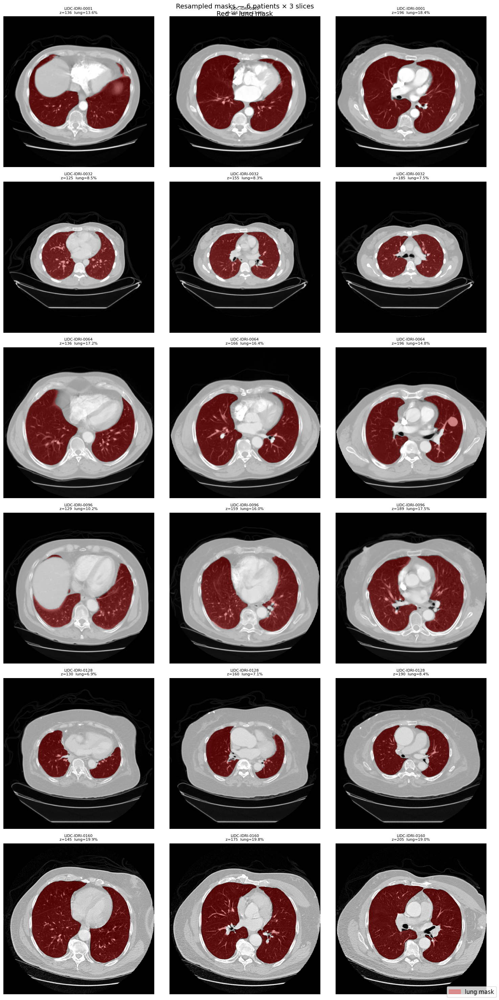

Saved to: C:\Users\Administrator\desktop\unet\mask_verify_resampled.png


In [18]:
# CELL 2-VERIFY — full quality check on resampled masks
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

# ── stats across all 160 ─────────────────────────────────────
print("Checking all 160 resampled masks...\n")

shape_mismatches = []
missing          = []
low_coverage     = []
high_coverage    = []
all_lung_vols    = []

for scan in client1_scans:
    pid       = scan.patient_id
    mask_path = MASK_DIR / f"{pid}.npy"
    vol_path  = PREPROC_DIR / f"{pid}.npy"

    # existence check
    if not mask_path.exists():
        missing.append(pid)
        continue

    mask = np.load(mask_path)
    vol  = np.load(vol_path)

    # shape match check
    if mask.shape != vol.shape:
        shape_mismatches.append((pid, mask.shape, vol.shape))
        continue

    # binary values check
    unique_vals = np.unique(mask)
    if not set(unique_vals).issubset({0, 1}):
        print(f"  ⚠ {pid}: unexpected mask values {unique_vals}")

    # lung volume in liters (1mm³ voxels after resampling)
    lung_voxels   = mask.sum()
    lung_vol_liters = lung_voxels / 1e6   # 1mm³ each = direct conversion
    all_lung_vols.append((pid, lung_vol_liters))

    if lung_vol_liters < 1.5:
        low_coverage.append((pid, lung_vol_liters))
    elif lung_vol_liters > 8.0:
        high_coverage.append((pid, lung_vol_liters))

# ── print summary ─────────────────────────────────────────────
print(f"{'='*50}")
print(f"Total checked     : {len(client1_scans)}")
print(f"Missing masks     : {len(missing)}")
print(f"Shape mismatches  : {len(shape_mismatches)}")
print(f"Low lung vol (<1.5L) : {len(low_coverage)}")
print(f"High lung vol (>8L)  : {len(high_coverage)}")

vols = [v for _, v in all_lung_vols]
print(f"\nLung volume stats (liters):")
print(f"  min  : {min(vols):.2f}")
print(f"  max  : {max(vols):.2f}")
print(f"  mean : {np.mean(vols):.2f}")
print(f"  median: {np.median(vols):.2f}")

if missing:
    print(f"\nMissing: {missing}")
if shape_mismatches:
    print(f"\nShape mismatches:")
    for pid, ms, vs in shape_mismatches:
        print(f"  {pid}: mask={ms} vol={vs}")
if low_coverage:
    print(f"\nSuspiciously low lung volume:")
    for pid, v in low_coverage:
        print(f"  {pid}: {v:.2f}L")
if high_coverage:
    print(f"\nSuspiciously high lung volume:")
    for pid, v in high_coverage:
        print(f"  {pid}: {v:.2f}L")

# ── visual check on 6 patients spread across the 160 ─────────
print(f"\n{'='*50}")
print("Visual check on 6 patients...")

check_pids = [
    client1_scans[0].patient_id,    # first
    client1_scans[31].patient_id,   # ~20%
    client1_scans[63].patient_id,   # ~40%
    client1_scans[95].patient_id,   # ~60%
    client1_scans[127].patient_id,  # ~80%
    client1_scans[159].patient_id,  # last
]

fig, axes = plt.subplots(6, 3, figsize=(15, 30))
fig.suptitle("Resampled masks — 6 patients × 3 slices\nRed = lung mask", fontsize=14)

for row, pid in enumerate(check_pids):
    vol  = np.load(PREPROC_DIR / f"{pid}.npy")
    mask = np.load(MASK_DIR    / f"{pid}.npy")

    mid_z = vol.shape[0] // 2
    slices = [mid_z - 30, mid_z, mid_z + 30]

    for col, z in enumerate(slices):
        z = max(0, min(vol.shape[0]-1, z))
        ax = axes[row, col]

        ax.imshow(vol[z], cmap='gray', vmin=0, vmax=1)

        overlay = np.zeros((*mask[z].shape, 4), dtype=np.float32)
        overlay[mask[z] == 1, 0] = 1.0
        overlay[mask[z] == 1, 3] = 0.3
        ax.imshow(overlay)

        lung_pct = mask[z].mean() * 100
        ax.set_title(f"{pid}\nz={z}  lung={lung_pct:.1f}%", fontsize=8)
        ax.axis('off')

red_patch = mpatches.Patch(color='red', alpha=0.3, label='lung mask')
fig.legend(handles=[red_patch], loc='lower right', fontsize=12)

plt.tight_layout()
out_path = OUT_ROOT / "mask_verify_resampled.png"
plt.savefig(out_path, dpi=80, bbox_inches='tight')
plt.show()
print(f"Saved to: {out_path}")

In [19]:
# quick count first before full verify
masks_saved = list(MASK_DIR.glob("*.npy"))
print(f"Masks in MASK_DIR : {len(masks_saved)}")
print(f"Expected          : 160")

# check if any are missing
saved_pids = {m.stem for m in masks_saved}
expected_pids = {s.patient_id for s in client1_scans}
missing = expected_pids - saved_pids
extra   = saved_pids - expected_pids

print(f"Missing           : {len(missing)}")
print(f"Unexpected        : {len(extra)}")
if missing:
    print(f"Missing IDs: {sorted(missing)}")

Masks in MASK_DIR : 160
Expected          : 160
Missing           : 0
Unexpected        : 0


In [21]:
# CELL 3 — ANNOTATION EXTRACTION
# Extracts nodule centers from pylidc, converts to resampled 1mm³ space
# Saves one JSON per patient with consensus nodules + exclusion zones
# Runtime: ~3-5 min for 160 patients
# Output:  annotations/<pid>.json
# ============================================================
import json
import numpy as np
import SimpleITK as sitk
import pylidc as pl
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

def get_nodule_center_resampled(ann, sitk_orig, sitk_resampled):
    """
    Convert pylidc annotation center to resampled 1mm³ voxel coords.
    Uses SimpleITK physical coordinate conversion — correct for all spacings.
    
    pylidc bbox: [0]=rows(y), [1]=cols(x), [2]=slices(k/z)
    """
    bbox = ann.bbox()
    
    # center in original voxel space
    orig_col = (bbox[1].start + bbox[1].stop) // 2  # x
    orig_row = (bbox[0].start + bbox[0].stop) // 2  # y
    orig_k   = (bbox[2].start + bbox[2].stop) // 2  # z slice index

    # original voxel → physical mm
    phys = sitk_orig.TransformIndexToPhysicalPoint(
        (int(orig_col), int(orig_row), int(orig_k))
    )

    # physical mm → resampled voxel
    res_idx = sitk_resampled.TransformPhysicalPointToIndex(phys)

    # clamp to volume bounds
    size = sitk_resampled.GetSize()  # (x, y, z)
    res_x = max(0, min(size[0]-1, res_idx[0]))
    res_y = max(0, min(size[1]-1, res_idx[1]))
    res_z = max(0, min(size[2]-1, res_idx[2]))

    # numpy is (z, y, x)
    return [int(res_z), int(res_y), int(res_x)]

def get_nodule_radius_mm(ann_group):
    """
    Estimate nodule radius in mm from annotation bboxes.
    Uses mean diameter across all annotations in the group.
    """
    diameters = []
    for ann in ann_group:
        bbox = ann.bbox()
        # diameter in each dimension using original spacing
        # pylidc bbox is in pixel coords — use diameter_mm if available
        try:
            diameters.append(ann.diameter)
        except Exception:
            # fallback: estimate from bbox
            d_row = bbox[0].stop - bbox[0].start
            d_col = bbox[1].stop - bbox[1].start
            diameters.append((d_row + d_col) / 2.0)
    return float(np.mean(diameters)) / 2.0  # radius = diameter / 2

def load_sitk_original(scan):
    """Load original DICOM as SimpleITK image."""
    dicom_path = scan.get_path_to_dicom_files()
    ids   = sitk.ImageSeriesReader.GetGDCMSeriesIDs(str(dicom_path))
    files = sitk.ImageSeriesReader.GetGDCMSeriesFileNames(
                str(dicom_path), ids[0])
    reader = sitk.ImageSeriesReader()
    reader.SetFileNames(files)
    return reader.Execute()

def build_resampled_sitk(pid):
    """
    Reconstruct resampled SimpleITK image from saved metadata.
    Avoids reloading full volume — just needs the metadata.
    """
    meta = np.load(
        PREPROC_DIR / f"{pid}_meta.npy",
        allow_pickle=True
    ).item()
    sitk_res = sitk.Image(
        [int(x) for x in meta['res_size']],
        sitk.sitkFloat32
    )
    sitk_res.SetSpacing([float(x) for x in meta['res_spacing']])
    sitk_res.SetOrigin([float(x) for x in meta['res_origin']])
    sitk_res.SetDirection([float(x) for x in meta['res_direction']])
    return sitk_res

# ── main loop ─────────────────────────────────────────────────
all_scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()
seen = {}
for s in all_scans:
    if s.patient_id not in seen:
        seen[s.patient_id] = s
client1_scans = list(seen.values())[:160]

failed  = []
skipped = 0

total_consensus  = 0
total_ambiguous  = 0
patients_no_nods = 0

for scan in tqdm(client1_scans, desc="Extracting annotations"):
    pid      = scan.patient_id
    out_path = ANNOT_DIR / f"{pid}.json"

    if out_path.exists():
        skipped += 1
        continue

    try:
        sitk_orig     = load_sitk_original(scan)
        sitk_resampled = build_resampled_sitk(pid)

        nod_groups = scan.cluster_annotations()

        consensus_nodules = []
        exclusion_zones   = []

        for ann_group in nod_groups:
            # compute center from first annotation
            # (all annotations in group are close together)
            center = get_nodule_center_resampled(
                ann_group[0], sitk_orig, sitk_resampled
            )
            radius = get_nodule_radius_mm(ann_group)

            # malignancy — average across all annotations in group
            mal_scores = []
            for ann in ann_group:
                try:
                    if ann.malignancy is not None:
                        mal_scores.append(ann.malignancy)
                except Exception:
                    pass
            malignancy = float(np.mean(mal_scores)) if mal_scores else None

            # exclusion zone — every annotation regardless of consensus
            exclusion_zones.append({
                "center_res": center,
                "radius_mm":  round(radius, 2)
            })

            # consensus nodule — only ≥3/4 radiologists
            if len(ann_group) >= MIN_CONSENSUS:
                consensus_nodules.append({
                    "center_res": center,
                    "radius_mm":  round(radius, 2),
                    "malignancy": round(malignancy, 2) if malignancy else None,
                    "n_annotators": len(ann_group)
                })
                total_consensus += 1
            else:
                total_ambiguous += 1

        if len(consensus_nodules) == 0:
            patients_no_nods += 1

        record = {
            "patient_id":         pid,
            "n_consensus_nodules": len(consensus_nodules),
            "n_exclusion_zones":   len(exclusion_zones),
            "consensus_nodules":   consensus_nodules,
            "exclusion_zones":     exclusion_zones
        }

        with open(out_path, "w") as f:
            json.dump(record, f, indent=2)

    except Exception as e:
        print(f"\n  ERROR on {pid}: {e}")
        failed.append(pid)

print(f"\n{'='*40}")
print(f"Done.")
print(f"  Annotated        : {len(client1_scans) - len(failed) - skipped}")
print(f"  Skipped          : {skipped}")
print(f"  Failed           : {len(failed)}")
print(f"\n  Total consensus nodules  : {total_consensus}")
print(f"  Total ambiguous nodules  : {total_ambiguous}")
print(f"  Patients with 0 nodules  : {patients_no_nods}")
if failed:
    print(f"\n  Failed IDs: {failed}")

Extracting annotations:  34%|███████████████████▌                                     | 55/160 [01:40<02:45,  1.57s/it]

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.


Extracting annotations:  57%|████████████████████████████████▊                        | 92/160 [02:58<02:21,  2.07s/it]

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.


Extracting annotations:  86%|███████████████████████████████████████████████▉        | 137/160 [04:22<00:39,  1.72s/it]

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.


Extracting annotations: 100%|████████████████████████████████████████████████████████| 160/160 [05:09<00:00,  1.93s/it]


Done.
  Annotated        : 160
  Skipped          : 0
  Failed           : 0

  Total consensus nodules  : 291
  Total ambiguous nodules  : 187
  Patients with 0 nodules  : 28



LIDC-IDRI-0001
  consensus nodules : 1
  exclusion zones   : 1
  nodule 1: center=(225,257,223)  radius=16.4mm  malignancy=4.75
    vol value at center : 0.7779  (expect >0.5 for dense nodule)
    inside lung mask    : True  (expect True)


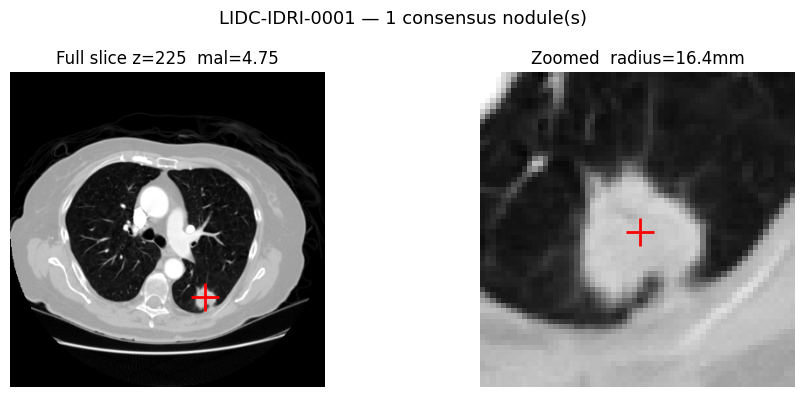

  Saved: C:\Users\Administrator\desktop\unet\annot_check_LIDC-IDRI-0001.png

LIDC-IDRI-0003
  consensus nodules : 3
  exclusion zones   : 4
  nodule 1: center=(188,287,302)  radius=15.5mm  malignancy=4.25
    vol value at center : 0.7107  (expect >0.5 for dense nodule)
    inside lung mask    : True  (expect True)
  nodule 2: center=(208,162,253)  radius=6.7mm  malignancy=3.25
    vol value at center : 0.6350  (expect >0.5 for dense nodule)
    inside lung mask    : True  (expect True)
  nodule 3: center=(210,180,181)  radius=7.5mm  malignancy=3.5
    vol value at center : 0.7129  (expect >0.5 for dense nodule)
    inside lung mask    : True  (expect True)


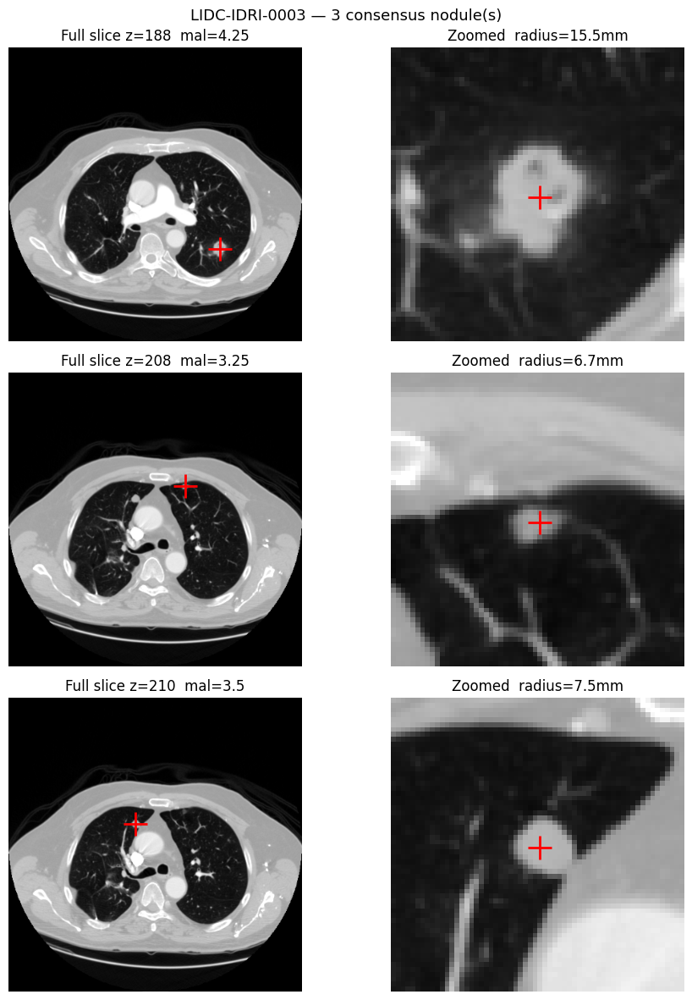

  Saved: C:\Users\Administrator\desktop\unet\annot_check_LIDC-IDRI-0003.png

LIDC-IDRI-0005
  consensus nodules : 2
  exclusion zones   : 3
  nodule 1: center=(195,264,84)  radius=2.9mm  malignancy=2.75
    vol value at center : 0.4079  (expect >0.5 for dense nodule)
    inside lung mask    : True  (expect True)
  nodule 2: center=(200,271,207)  radius=4.0mm  malignancy=2.75
    vol value at center : 0.5757  (expect >0.5 for dense nodule)
    inside lung mask    : True  (expect True)


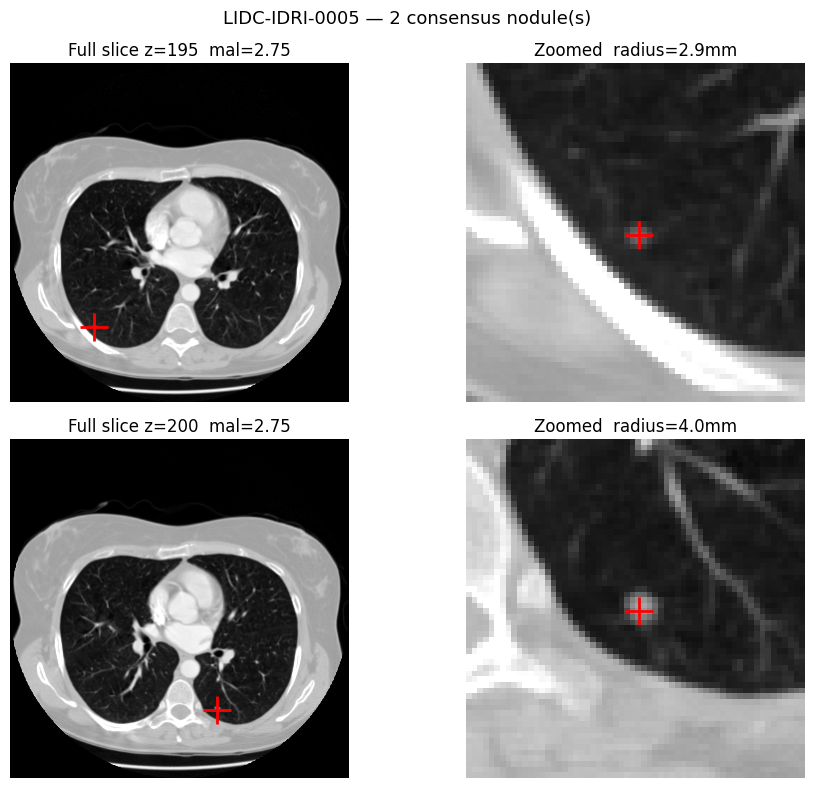

  Saved: C:\Users\Administrator\desktop\unet\annot_check_LIDC-IDRI-0005.png


In [22]:
# CELL 3-VERIFY — check annotations on 3 patients
# ============================================================
import json
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# check a few patients
check_pids = [
    "LIDC-IDRI-0001",  # known to have 1 consensus nodule
    "LIDC-IDRI-0003",  # known to have 3 consensus nodules
    "LIDC-IDRI-0005",  # known to have 2 consensus nodules
]

for pid in check_pids:
    ann_path = ANNOT_DIR / f"{pid}.json"
    with open(ann_path) as f:
        record = json.load(f)

    vol  = np.load(PREPROC_DIR / f"{pid}.npy")
    mask = np.load(MASK_DIR    / f"{pid}.npy")

    print(f"\n{pid}")
    print(f"  consensus nodules : {record['n_consensus_nodules']}")
    print(f"  exclusion zones   : {record['n_exclusion_zones']}")

    nodules = record["consensus_nodules"]
    if not nodules:
        print("  no consensus nodules — skipping visual")
        continue

    n = len(nodules)
    fig, axes = plt.subplots(n, 2, figsize=(10, 4*n))
    if n == 1:
        axes = [axes]
    fig.suptitle(f"{pid} — {n} consensus nodule(s)", fontsize=13)

    for i, nod in enumerate(nodules):
        z, y, x = nod["center_res"]
        r       = nod["radius_mm"]
        mal     = nod["malignancy"]

        print(f"  nodule {i+1}: center=({z},{y},{x})  "
              f"radius={r:.1f}mm  malignancy={mal}")
        print(f"    vol value at center : "
              f"{vol[z,y,x]:.4f}  (expect >0.5 for dense nodule)")
        print(f"    inside lung mask    : "
              f"{bool(mask[z,y,x])}  (expect True)")

        # full slice with crosshair
        axes[i][0].imshow(vol[z], cmap='gray', vmin=0, vmax=1)
        axes[i][0].plot(x, y, 'r+', markersize=20, markeredgewidth=2)
        axes[i][0].set_title(f"Full slice z={z}  mal={mal}")
        axes[i][0].axis('off')

        # zoomed nodule
        margin = 30
        D,H,W  = vol.shape
        y1,y2  = max(0,y-margin), min(H,y+margin)
        x1,x2  = max(0,x-margin), min(W,x+margin)
        axes[i][1].imshow(vol[z,y1:y2,x1:x2], cmap='gray', vmin=0, vmax=1)
        axes[i][1].plot(x-x1, y-y1, 'r+', markersize=20, markeredgewidth=2)
        axes[i][1].set_title(f"Zoomed  radius={r:.1f}mm")
        axes[i][1].axis('off')

    plt.tight_layout()
    out_path = OUT_ROOT / f"annot_check_{pid}.png"
    plt.savefig(out_path, dpi=90, bbox_inches='tight')
    plt.show()
    print(f"  Saved: {out_path}")

In [31]:
# CELL 4-FIX — regenerate positive patches with minimum sigma
# Only positives need to change — negatives stay as-is
# Runtime: ~2-3 min
# ============================================================
import json
import numpy as np
from scipy.ndimage import gaussian_filter
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

CLIENT_PATCH_DIR = PATCH_DIR / "client1"
POS_DIR = CLIENT_PATCH_DIR / "positives"

def make_gaussian_heatmap_fixed(patch_size, center, radius_mm,
                                 sigma_factor=GAUSSIAN_SIGMA_FACTOR,
                                 min_sigma=3.0):
    """
    Gaussian heatmap with minimum sigma to ensure learnable signal.
    min_sigma=3.0 means at least ~113 active voxels regardless of nodule size.
    """
    p      = patch_size
    sigma  = max(min_sigma, radius_mm / sigma_factor)
    heatmap = np.zeros((p, p, p), dtype=np.float32)

    cz, cy, cx = center
    if 0 <= cz < p and 0 <= cy < p and 0 <= cx < p:
        heatmap[cz, cy, cx] = 1.0

    heatmap = gaussian_filter(heatmap, sigma=sigma)

    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()

    return heatmap

def extract_patch(vol, center_z, center_y, center_x, patch_size):
    p    = patch_size // 2
    D, H, W = vol.shape
    z1,z2 = center_z-p, center_z+p
    y1,y2 = center_y-p, center_y+p
    x1,x2 = center_x-p, center_x+p
    pad_z0 = max(0,-z1);  pad_z1 = max(0,z2-D)
    pad_y0 = max(0,-y1);  pad_y1 = max(0,y2-H)
    pad_x0 = max(0,-x1);  pad_x1 = max(0,x2-W)
    z1c,z2c = max(0,z1), min(D,z2)
    y1c,y2c = max(0,y1), min(H,y2)
    x1c,x2c = max(0,x1), min(W,x2)
    crop = vol[z1c:z2c, y1c:y2c, x1c:x2c]
    patch = np.pad(crop, (
        (pad_z0,pad_z1),(pad_y0,pad_y1),(pad_x0,pad_x1)
    ), mode='constant', constant_values=0)
    return patch.astype(np.float32)

# load client 1 scans
import pylidc as pl
all_scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()
seen = {}
for s in all_scans:
    if s.patient_id not in seen:
        seen[s.patient_id] = s
client1_scans = list(seen.values())[:160]

p  = PATCH_SIZE
ph = p // 2
total_pos = 0

for scan in tqdm(client1_scans, desc="Regenerating positive patches"):
    pid = scan.patient_id

    with open(ANNOT_DIR / f"{pid}.json") as f:
        record = json.load(f)

    consensus = record["consensus_nodules"]
    if not consensus:
        continue

    vol = np.load(PREPROC_DIR / f"{pid}.npy")

    for i, nod in enumerate(consensus):
        z, y, x   = nod["center_res"]
        radius_mm = nod["radius_mm"]

        patch   = extract_patch(vol, z, y, x, p)
        heatmap = make_gaussian_heatmap_fixed(
            p,
            center=(ph, ph, ph),
            radius_mm=radius_mm,
            sigma_factor=GAUSSIAN_SIGMA_FACTOR,
            min_sigma=3.0
        )

        out = POS_DIR / f"{pid}_n{i:02d}.npz"
        np.savez_compressed(out,
                            vol=patch,
                            heatmap=heatmap,
                            center=np.array([z,y,x]),
                            radius=np.array([radius_mm]))
        total_pos += 1

print(f"\nRegenerated {total_pos} positive patches with fixed sigma")

# verify fix
print(f"\n{'File':<35} {'radius_mm':>10} {'sigma':>8} {'voxels>0.5':>12}")
print("-" * 68)
pos_files = sorted(POS_DIR.glob("*.npz"))
for f in pos_files[:10]:
    data    = np.load(f)
    heatmap = data['heatmap']
    radius  = float(data['radius'])
    sigma   = max(3.0, radius / GAUSSIAN_SIGMA_FACTOR)
    active  = int((heatmap > 0.5).sum())
    print(f"{f.name:<35} {radius:>10.1f} {sigma:>8.2f} {active:>12d}")

Regenerating positive patches: 100%|█████████████████████████████████████████████████| 160/160 [03:26<00:00,  1.29s/it]



Regenerated 291 positive patches with fixed sigma

File                                 radius_mm    sigma   voxels>0.5
--------------------------------------------------------------------
LIDC-IDRI-0001_n00.npz                    16.4     5.46         1141
LIDC-IDRI-0003_n00.npz                    15.5     5.17          949
LIDC-IDRI-0003_n01.npz                     6.7     3.00          179
LIDC-IDRI-0003_n02.npz                     7.5     3.00          179
LIDC-IDRI-0004_n00.npz                     3.4     3.00          179
LIDC-IDRI-0005_n00.npz                     2.9     3.00          179
LIDC-IDRI-0005_n01.npz                     4.0     3.00          179
LIDC-IDRI-0006_n00.npz                     4.4     3.00          179
LIDC-IDRI-0007_n00.npz                    17.2     5.74         1309
LIDC-IDRI-0008_n00.npz                     4.5     3.00          179


Positive patches : 291
Negative patches : 722
Neg/Pos ratio    : 2.48

Checking patch shapes and value ranges...
  POS LIDC-IDRI-0012_n00.npz: vol=(96, 96, 96) vol_range=[0.000,1.000] heatmap_peak=1.000
  POS LIDC-IDRI-0120_n01.npz: vol=(96, 96, 96) vol_range=[0.000,1.000] heatmap_peak=1.000
  POS LIDC-IDRI-0045_n04.npz: vol=(96, 96, 96) vol_range=[0.000,1.000] heatmap_peak=1.000
  POS LIDC-IDRI-0008_n00.npz: vol=(96, 96, 96) vol_range=[0.006,1.000] heatmap_peak=1.000
  POS LIDC-IDRI-0055_n00.npz: vol=(96, 96, 96) vol_range=[0.001,0.969] heatmap_peak=1.000
  NEG LIDC-IDRI-0053_neg003.npz: vol=(96, 96, 96) vol_range=[0.000,1.000] heatmap_peak=0.000
  NEG LIDC-IDRI-0030_neg002.npz: vol=(96, 96, 96) vol_range=[0.000,1.000] heatmap_peak=0.000
  NEG LIDC-IDRI-0012_neg008.npz: vol=(96, 96, 96) vol_range=[0.000,1.000] heatmap_peak=0.000
  NEG LIDC-IDRI-0069_neg002.npz: vol=(96, 96, 96) vol_range=[0.000,1.000] heatmap_peak=0.000
  NEG LIDC-IDRI-0129_neg008.npz: vol=(96, 96, 96) vol_range=[0.00

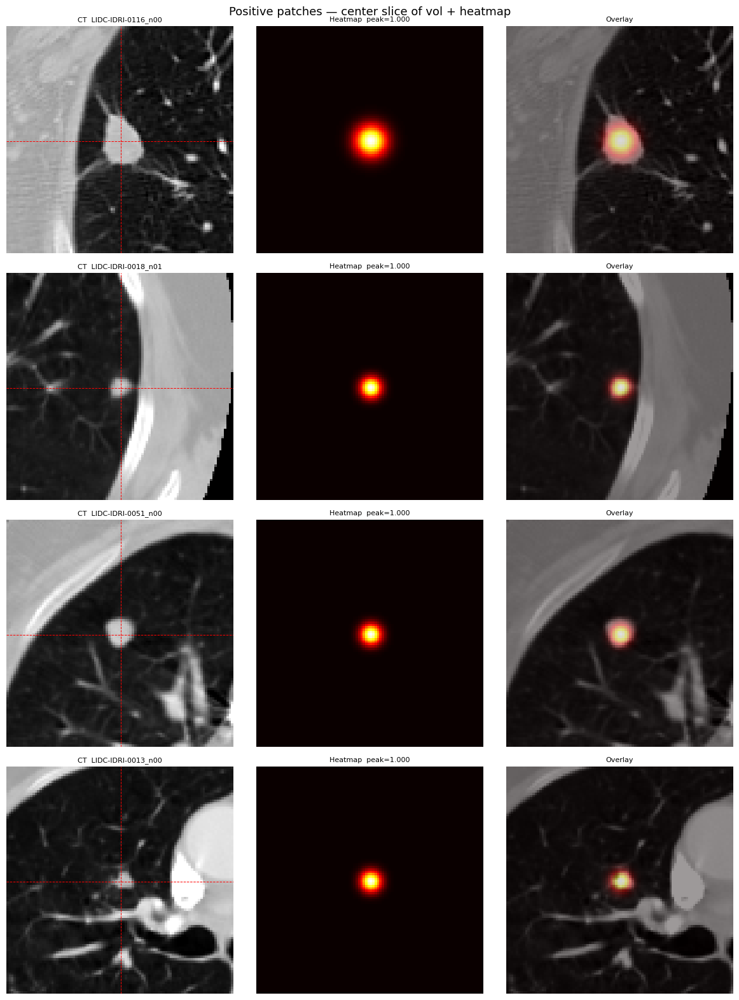

Visualizing 4 negative patches...


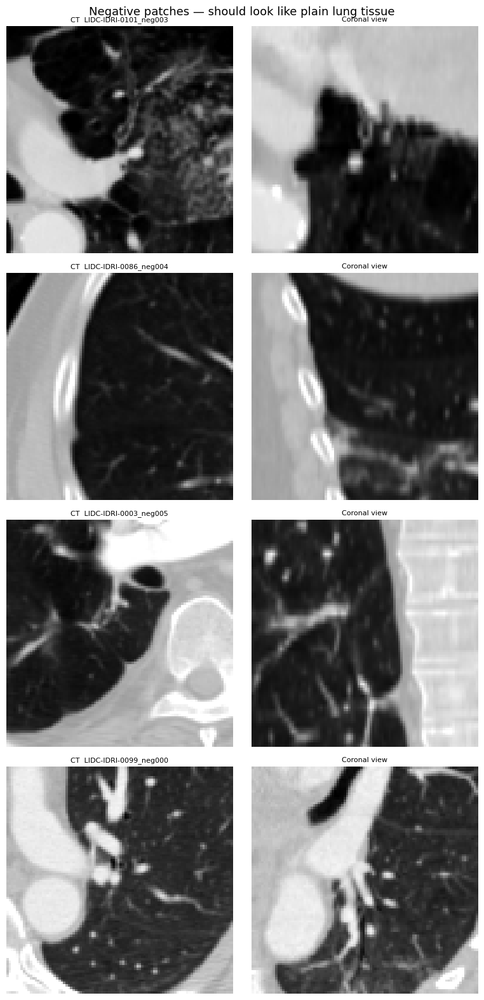

Done — check images look correct before training


In [32]:
# CELL 4-VERIFY — visual check on extracted patches
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import random

CLIENT_PATCH_DIR = PATCH_DIR / "client1"
POS_DIR = CLIENT_PATCH_DIR / "positives"
NEG_DIR = CLIENT_PATCH_DIR / "negatives"

pos_files = list(POS_DIR.glob("*.npz"))
neg_files = list(NEG_DIR.glob("*.npz"))

print(f"Positive patches : {len(pos_files)}")
print(f"Negative patches : {len(neg_files)}")
print(f"Neg/Pos ratio    : {len(neg_files)/max(len(pos_files),1):.2f}")

# ── check patch stats ─────────────────────────────────────────
print(f"\nChecking patch shapes and value ranges...")
sample_pos = random.sample(pos_files, min(5, len(pos_files)))
sample_neg = random.sample(neg_files, min(5, len(neg_files)))

for f in sample_pos:
    data = np.load(f)
    vol, heatmap = data['vol'], data['heatmap']
    print(f"  POS {f.name}: vol={vol.shape} "
          f"vol_range=[{vol.min():.3f},{vol.max():.3f}] "
          f"heatmap_peak={heatmap.max():.3f}")

for f in sample_neg:
    data = np.load(f)
    vol, heatmap = data['vol'], data['heatmap']
    print(f"  NEG {f.name}: vol={vol.shape} "
          f"vol_range=[{vol.min():.3f},{vol.max():.3f}] "
          f"heatmap_peak={heatmap.max():.3f}")

# ── visual check — 4 positives ────────────────────────────────
print(f"\nVisualizing 4 positive patches...")
show_pos = random.sample(pos_files, min(4, len(pos_files)))

fig, axes = plt.subplots(4, 3, figsize=(12, 16))
fig.suptitle("Positive patches — center slice of vol + heatmap",
             fontsize=13)

for row, f in enumerate(show_pos):
    data    = np.load(f)
    vol     = data['vol']      # (96,96,96)
    heatmap = data['heatmap']  # (96,96,96)
    mid     = vol.shape[0] // 2

    # CT slice
    axes[row,0].imshow(vol[mid], cmap='gray', vmin=0, vmax=1)
    axes[row,0].axhline(mid, color='red', linewidth=0.7, linestyle='--')
    axes[row,0].axvline(mid, color='red', linewidth=0.7, linestyle='--')
    axes[row,0].set_title(f"CT  {f.stem}", fontsize=8)
    axes[row,0].axis('off')

    # heatmap slice
    axes[row,1].imshow(heatmap[mid], cmap='hot', vmin=0, vmax=1)
    axes[row,1].set_title(f"Heatmap  peak={heatmap.max():.3f}", fontsize=8)
    axes[row,1].axis('off')

    # overlay
    axes[row,2].imshow(vol[mid], cmap='gray', vmin=0, vmax=1)
    axes[row,2].imshow(heatmap[mid], cmap='hot', alpha=0.4, vmin=0, vmax=1)
    axes[row,2].set_title("Overlay", fontsize=8)
    axes[row,2].axis('off')

plt.tight_layout()
plt.savefig(OUT_ROOT / "patch_check_positives.png", dpi=90,
            bbox_inches='tight')
plt.show()

# ── visual check — 4 negatives ────────────────────────────────
print(f"Visualizing 4 negative patches...")
show_neg = random.sample(neg_files, min(4, len(neg_files)))

fig, axes = plt.subplots(4, 2, figsize=(8, 16))
fig.suptitle("Negative patches — should look like plain lung tissue",
             fontsize=13)

for row, f in enumerate(show_neg):
    data = np.load(f)
    vol  = data['vol']
    mid  = vol.shape[0] // 2

    axes[row,0].imshow(vol[mid], cmap='gray', vmin=0, vmax=1)
    axes[row,0].set_title(f"CT  {f.stem}", fontsize=8)
    axes[row,0].axis('off')

    # show axial + coronal to confirm no nodule
    axes[row,1].imshow(vol[:, mid, :], cmap='gray', vmin=0, vmax=1)
    axes[row,1].set_title("Coronal view", fontsize=8)
    axes[row,1].axis('off')

plt.tight_layout()
plt.savefig(OUT_ROOT / "patch_check_negatives.png", dpi=90,
            bbox_inches='tight')
plt.show()
print("Done — check images look correct before training")

In [34]:
# quick check — confirm negatives are inside lung mask
import numpy as np
import random

CLIENT_PATCH_DIR = PATCH_DIR / "client1"
NEG_DIR = CLIENT_PATCH_DIR / "negatives"

neg_files = list(NEG_DIR.glob("*.npz"))
sample    = random.sample(neg_files, min(20, len(neg_files)))

outside_mask = 0
for f in sample:
    data = np.load(f)
    center = data['center']
    z, y, x = int(center[0]), int(center[1]), int(center[2])
    
    # correct pid extraction: LIDC-IDRI-0061_neg006 → LIDC-IDRI-0061
    # stem = LIDC-IDRI-0061_neg006
    # split on _neg → ['LIDC-IDRI-0061', '006']
    pid = f.stem.split('_neg')[0]
    
    mask_path = MASK_DIR / f"{pid}.npy"
    if not mask_path.exists():
        print(f"  ⚠ mask not found for {pid}")
        continue
    
    mask   = np.load(mask_path)
    in_mask = bool(mask[z, y, x])
    if not in_mask:
        outside_mask += 1
        print(f"  ⚠ {f.name}: center ({z},{y},{x}) OUTSIDE mask")

print(f"\nChecked      : {len(sample)} negative patches")
print(f"Outside mask : {outside_mask}")
print(f"Inside mask  : {len(sample) - outside_mask}")
if outside_mask == 0:
    print("✓ All negative centers confirmed inside lung mask")


Checked      : 20 negative patches
Outside mask : 0
Inside mask  : 20
✓ All negative centers confirmed inside lung mask


In [33]:
# check gaussian spread on positives
import numpy as np
from pathlib import Path
import json

CLIENT_PATCH_DIR = PATCH_DIR / "client1"
POS_DIR = CLIENT_PATCH_DIR / "positives"

pos_files = list(POS_DIR.glob("*.npz"))

print(f"{'File':<30} {'radius_mm':>10} {'sigma':>8} {'heatmap_area':>14}")
print("-" * 66)

for f in sorted(pos_files)[:10]:
    data   = np.load(f)
    heatmap = data['heatmap']
    radius  = float(data['radius'])
    sigma   = radius / GAUSSIAN_SIGMA_FACTOR

    # count voxels above 0.5 as "active" heatmap area
    active = (heatmap > 0.5).sum()

    print(f"{f.name:<30} {radius:>10.1f} {sigma:>8.2f} {active:>14d}")

File                            radius_mm    sigma   heatmap_area
------------------------------------------------------------------
LIDC-IDRI-0001_n00.npz               16.4     5.46           1141
LIDC-IDRI-0003_n00.npz               15.5     5.17            949
LIDC-IDRI-0003_n01.npz                6.7     2.22            179
LIDC-IDRI-0003_n02.npz                7.5     2.50            179
LIDC-IDRI-0004_n00.npz                3.4     1.14            179
LIDC-IDRI-0005_n00.npz                2.9     0.95            179
LIDC-IDRI-0005_n01.npz                4.0     1.32            179
LIDC-IDRI-0006_n00.npz                4.4     1.46            179
LIDC-IDRI-0007_n00.npz               17.2     5.74           1309
LIDC-IDRI-0008_n00.npz                4.5     1.52            179


Deleting 533 existing positive patches...
Deleted.



Extracting jittered patches: 100%|███████████████████████████████████████████████████| 160/160 [07:30<00:00,  2.81s/it]



Done.
  Centered patches : 291
  Jittered patches : 1164
  Total positives  : 1455
  Total negatives  : 1013
  Neg/Pos ratio    : 0.70

Jitter offset stats (mm):
  min  : 2.2mm
  max  : 32.4mm
  mean : 19.7mm

Key check:
  Max jitter       : 32.4mm
  Inference stride : 20mm
  Max inference offset (stride/2): 10mm
  ✓ Training covers inference distribution


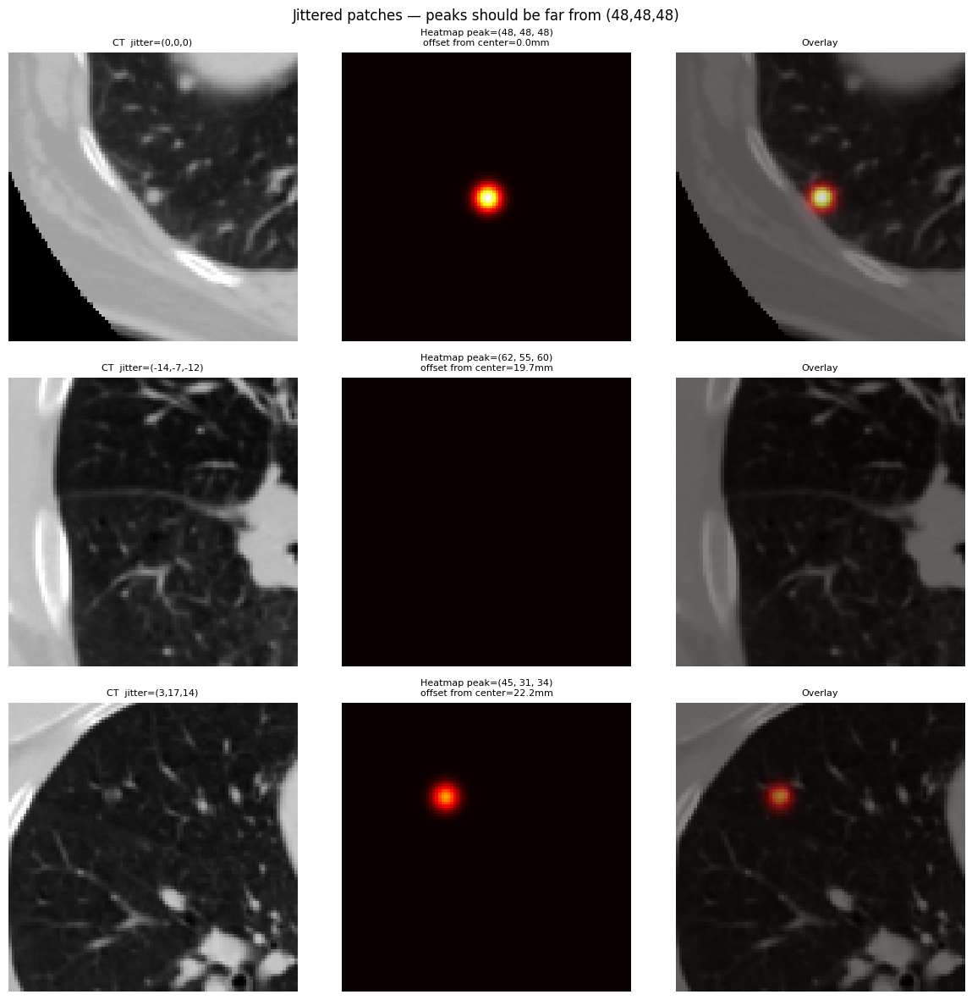

In [2]:
# CELL 4-JITTER — regenerate positives with proven jitter strategy
# jitter_range = max(nodule_radius, 20mm) capped at 40mm
# stride=20 at inference covers max 10mm offset — well within training range
# N_JITTERS=4: 1 centered + 4 jittered = 5 patches per nodule
# Runtime: ~8-10 min for 160 patients
# ============================================================
import json
import numpy as np
from scipy.ndimage import gaussian_filter
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

CLIENT_PATCH_DIR = PATCH_DIR / "client1"
POS_DIR = CLIENT_PATCH_DIR / "positives"

# ── delete existing positives ─────────────────────────────────
existing = list(POS_DIR.glob("*.npz"))
print(f"Deleting {len(existing)} existing positive patches...")
for f in existing:
    f.unlink()
print("Deleted.\n")

# ── helpers ───────────────────────────────────────────────────
def make_gaussian_heatmap_fixed(patch_size, center, radius_mm,
                                 sigma_factor=3, min_sigma=3.0):
    p      = patch_size
    sigma  = max(min_sigma, radius_mm / sigma_factor)
    heatmap = np.zeros((p, p, p), dtype=np.float32)
    cz = max(0, min(p-1, center[0]))
    cy = max(0, min(p-1, center[1]))
    cx = max(0, min(p-1, center[2]))
    heatmap[cz, cy, cx] = 1.0
    heatmap = gaussian_filter(heatmap, sigma=sigma)
    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()
    return heatmap

def extract_patch(vol, center_z, center_y, center_x, patch_size):
    p    = patch_size // 2
    D, H, W = vol.shape
    z1,z2 = center_z-p, center_z+p
    y1,y2 = center_y-p, center_y+p
    x1,x2 = center_x-p, center_x+p
    pad_z0 = max(0,-z1); pad_z1 = max(0,z2-D)
    pad_y0 = max(0,-y1); pad_y1 = max(0,y2-H)
    pad_x0 = max(0,-x1); pad_x1 = max(0,x2-W)
    z1c,z2c = max(0,z1), min(D,z2)
    y1c,y2c = max(0,y1), min(H,y2)
    x1c,x2c = max(0,x1), min(W,x2)
    crop = vol[z1c:z2c, y1c:y2c, x1c:x2c]
    patch = np.pad(crop, (
        (pad_z0,pad_z1),(pad_y0,pad_y1),(pad_x0,pad_x1)
    ), mode='constant', constant_values=0)
    return patch.astype(np.float32)

# ── load client 1 scans ───────────────────────────────────────
import pylidc as pl
all_scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()
seen = {}
for s in all_scans:
    if s.patient_id not in seen:
        seen[s.patient_id] = s
client1_scans = list(seen.values())[:160]

p  = PATCH_SIZE   # 96
ph = p // 2       # 48
np.random.seed(42)

total_pos      = 0
centered_count = 0
jittered_count = 0

# track jitter stats for verification
all_offsets = []

for scan in tqdm(client1_scans, desc="Extracting jittered patches"):
    pid = scan.patient_id

    with open(ANNOT_DIR / f"{pid}.json") as f:
        record = json.load(f)
    consensus = record["consensus_nodules"]
    if not consensus:
        continue

    vol = np.load(PREPROC_DIR / f"{pid}.npy")
    D, H, W = vol.shape

    for i, nod in enumerate(consensus):
        z, y, x   = nod["center_res"]
        radius_mm = nod["radius_mm"]

        # jitter range = max(radius_mm, 20) capped at 40
        # ensures minimum 20mm offset training coverage
        # which is > stride/2 = 10mm (inference max offset)
        jitter_range = int(np.clip(radius_mm, 20, 40))

        # 1 centered + N_JITTERS random offsets
        jitters = [(0, 0, 0)]
        for _ in range(N_JITTERS):
            jz = int(np.random.randint(-jitter_range, jitter_range+1))
            jy = int(np.random.randint(-jitter_range, jitter_range+1))
            jx = int(np.random.randint(-jitter_range, jitter_range+1))
            jitters.append((jz, jy, jx))

        for ji, (jz, jy, jx) in enumerate(jitters):
            # shift patch center by jitter
            patch_cz = z + jz
            patch_cy = y + jy
            patch_cx = x + jx

            patch = extract_patch(vol, patch_cz, patch_cy, patch_cx, p)

            # nodule appears at (ph-jz, ph-jy, ph-jx) in patch
            heatmap_center = (
                max(0, min(p-1, ph - jz)),
                max(0, min(p-1, ph - jy)),
                max(0, min(p-1, ph - jx))
            )

            heatmap = make_gaussian_heatmap_fixed(
                p,
                center=heatmap_center,
                radius_mm=radius_mm,
                sigma_factor=GAUSSIAN_SIGMA_FACTOR,
                min_sigma=3.0
            )

            out = POS_DIR / f"{pid}_n{i:02d}_j{ji:02d}.npz"
            np.savez_compressed(out,
                                vol=patch,
                                heatmap=heatmap,
                                center=np.array([z, y, x]),
                                radius=np.array([radius_mm]),
                                jitter=np.array([jz, jy, jx]))
            total_pos += 1
            if ji == 0:
                centered_count += 1
            else:
                jittered_count += 1
                offset = np.sqrt(jz**2 + jy**2 + jx**2)
                all_offsets.append(offset)

# ── summary ───────────────────────────────────────────────────
pos_files = list(POS_DIR.glob("*.npz"))
neg_files = list((CLIENT_PATCH_DIR / "negatives").glob("*.npz"))

print(f"\n{'='*45}")
print(f"Done.")
print(f"  Centered patches : {centered_count}")
print(f"  Jittered patches : {jittered_count}")
print(f"  Total positives  : {len(pos_files)}")
print(f"  Total negatives  : {len(neg_files)}")
print(f"  Neg/Pos ratio    : {len(neg_files)/max(len(pos_files),1):.2f}")

if all_offsets:
    print(f"\nJitter offset stats (mm):")
    print(f"  min  : {min(all_offsets):.1f}mm")
    print(f"  max  : {max(all_offsets):.1f}mm")
    print(f"  mean : {np.mean(all_offsets):.1f}mm")
    print(f"\nKey check:")
    print(f"  Max jitter       : {max(all_offsets):.1f}mm")
    print(f"  Inference stride : {STRIDE}mm")
    print(f"  Max inference offset (stride/2): {STRIDE//2}mm")
    if max(all_offsets) >= STRIDE//2:
        print(f"  ✓ Training covers inference distribution")
    else:
        print(f"  ⚠ Training may not cover inference distribution")

# ── visual sanity check ───────────────────────────────────────
import random
import matplotlib.pyplot as plt

sample_files = random.sample(pos_files, min(3, len(pos_files)))
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
fig.suptitle("Jittered patches — peaks should be far from (48,48,48)",
             fontsize=12)

for row, f in enumerate(sample_files):
    data   = np.load(f)
    vol_p  = data['vol']
    heat_p = data['heatmap']
    jitter = data['jitter']
    mid    = vol_p.shape[0] // 2
    peak   = np.unravel_index(heat_p.argmax(), heat_p.shape)
    offset = np.sqrt(sum((peak[i]-48)**2 for i in range(3)))

    axes[row,0].imshow(vol_p[mid], cmap='gray', vmin=0, vmax=1)
    axes[row,0].set_title(
        f"CT  jitter=({jitter[0]},{jitter[1]},{jitter[2]})", fontsize=8)
    axes[row,0].axis('off')

    axes[row,1].imshow(heat_p[mid], cmap='hot', vmin=0, vmax=1)
    axes[row,1].set_title(
        f"Heatmap peak={peak}\noffset from center={offset:.1f}mm", fontsize=8)
    axes[row,1].axis('off')

    axes[row,2].imshow(vol_p[mid], cmap='gray', vmin=0, vmax=1)
    axes[row,2].imshow(heat_p[mid], cmap='hot', alpha=0.5, vmin=0, vmax=1)
    axes[row,2].set_title("Overlay", fontsize=8)
    axes[row,2].axis('off')

plt.tight_layout()
plt.savefig(OUT_ROOT / "jitter_check_v2.png", dpi=90)
plt.show()


In [9]:
# CELL 4-TOPUP-FIXED
import json
import numpy as np
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

CLIENT_PATCH_DIR = PATCH_DIR / "client1"
POS_DIR = CLIENT_PATCH_DIR / "positives"
NEG_DIR = CLIENT_PATCH_DIR / "negatives"

pos_files = list(POS_DIR.glob("*.npz"))
neg_files = list(NEG_DIR.glob("*.npz"))

target_ratio = 2  # hardcode 2:1 here
target_negs  = len(pos_files) * target_ratio
need         = target_negs - len(neg_files)

print(f"Positives        : {len(pos_files)}")
print(f"Current negatives: {len(neg_files)}")
print(f"Target (2:1)     : {target_negs}")
print(f"Need to generate : {need}")

if need <= 0:
    print("Already at target ratio. Nothing to do.")
else:
    def extract_patch(vol, center_z, center_y, center_x, patch_size):
        p    = patch_size // 2
        D, H, W = vol.shape
        z1,z2 = center_z-p, center_z+p
        y1,y2 = center_y-p, center_y+p
        x1,x2 = center_x-p, center_x+p
        pad_z0 = max(0,-z1); pad_z1 = max(0,z2-D)
        pad_y0 = max(0,-y1); pad_y1 = max(0,y2-H)
        pad_x0 = max(0,-x1); pad_x1 = max(0,x2-W)
        z1c,z2c = max(0,z1), min(D,z2)
        y1c,y2c = max(0,y1), min(H,y2)
        x1c,x2c = max(0,x1), min(W,x2)
        crop = vol[z1c:z2c, y1c:y2c, x1c:x2c]
        patch = np.pad(crop, (
            (pad_z0,pad_z1),(pad_y0,pad_y1),(pad_x0,pad_x1)
        ), mode='constant', constant_values=0)
        return patch.astype(np.float32)

    def build_exclusion_mask(vol_shape, exclusion_zones, margin_voxels):
        D, H, W = vol_shape
        excl    = np.zeros((D, H, W), dtype=bool)
        for zone in exclusion_zones:
            z, y, x = zone["center_res"]
            r = int(zone["radius_mm"]) + margin_voxels
            excl[max(0,z-r):min(D,z+r),
                 max(0,y-r):min(H,y+r),
                 max(0,x-r):min(W,x+r)] = True
        return excl

    import pylidc as pl
    all_scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()
    seen = {}
    for s in all_scans:
        if s.patient_id not in seen:
            seen[s.patient_id] = s
    client1_scans = list(seen.values())[:160]

    p  = PATCH_SIZE
    ph = p // 2

    # distribute needed negatives evenly across patients
    per_patient = max(1, need // len(client1_scans))
    total_new   = 0

    # get existing neg count per patient
    existing_neg_pids = {}
    for f in neg_files:
        pid = f.stem.split('_neg')[0]
        existing_neg_pids[pid] = existing_neg_pids.get(pid, 0) + 1

    for scan in tqdm(client1_scans, desc="Generating negatives"):
        pid = scan.patient_id
        if total_new >= need:
            break

        with open(ANNOT_DIR / f"{pid}.json") as f:
            record = json.load(f)

        vol  = np.load(PREPROC_DIR / f"{pid}.npy")
        mask = np.load(MASK_DIR    / f"{pid}.npy")
        D, H, W = vol.shape

        excl_mask  = build_exclusion_mask(
            vol.shape, record["exclusion_zones"], MARGIN_VOXELS
        )
        valid_mask = (mask == 1) & ~excl_mask
        valid_mask[:ph,  :,    :  ] = False
        valid_mask[D-ph:,:,    :  ] = False
        valid_mask[:,  :ph,    :  ] = False
        valid_mask[:,  H-ph:,  :  ] = False
        valid_mask[:,  :,    :ph  ] = False
        valid_mask[:,  :,    W-ph:] = False

        valid_coords = np.argwhere(valid_mask)
        if len(valid_coords) == 0:
            continue

        n_sample = min(per_patient, len(valid_coords),
                       need - total_new)
        chosen   = np.random.choice(
            len(valid_coords), n_sample, replace=False
        )
        current  = existing_neg_pids.get(pid, 0)

        for j, idx in enumerate(chosen):
            z, y, x = valid_coords[idx]
            patch   = extract_patch(vol, z, y, x, p)
            heatmap = np.zeros((p, p, p), dtype=np.float32)
            out = NEG_DIR / f"{pid}_neg{current+j:04d}.npz"
            np.savez_compressed(out,
                                vol=patch,
                                heatmap=heatmap,
                                center=np.array([z,y,x]))
            total_new += 1

    neg_files_after = list(NEG_DIR.glob("*.npz"))
    print(f"\nNew negatives added : {total_new}")
    print(f"Total negatives now : {len(neg_files_after)}")
    print(f"Total positives     : {len(pos_files)}")
    print(f"Final ratio         : {len(neg_files_after)/len(pos_files):.2f}")

Positives        : 1455
Current negatives: 1013
Target (2:1)     : 2910
Need to generate : 1897


Generating negatives: 100%|██████████████████████████████████████████████████████████| 160/160 [10:09<00:00,  3.81s/it]


New negatives added : 1760
Total negatives now : 2773
Total positives     : 1455
Final ratio         : 1.91


In [10]:
# CELL 4-SPLIT — patient-level split, leak-proof version
# Patient assignments are fixed BEFORE looking at any patches
# ============================================================
import json
import random
from pathlib import Path

CLIENT_PATCH_DIR = PATCH_DIR / "client1"
POS_DIR = CLIENT_PATCH_DIR / "positives"
NEG_DIR = CLIENT_PATCH_DIR / "negatives"

# ── step 1: fix patient assignments from federation splits ────
# use the saved federation split so patient IDs never change
with open(OUT_ROOT / "federation_splits.json") as f:
    fed_splits = json.load(f)

client1_all_pids = sorted(fed_splits["client1_pids"])  # 160 patients, fixed

random.seed(42)
shuffled = client1_all_pids.copy()
random.shuffle(shuffled)

n_test = max(1, int(len(shuffled) * 0.15))  # 24
n_val  = max(1, int(len(shuffled) * 0.15))  # 24
n_trn  = len(shuffled) - n_val - n_test     # 112

tst_pids = set(shuffled[:n_test])
val_pids = set(shuffled[n_test:n_test+n_val])
trn_pids = set(shuffled[n_test+n_val:])

# ── step 2: verify zero overlap ───────────────────────────────
assert len(trn_pids & val_pids) == 0, "LEAKAGE: train/val overlap"
assert len(trn_pids & tst_pids) == 0, "LEAKAGE: train/test overlap"
assert len(val_pids & tst_pids) == 0, "LEAKAGE: val/test overlap"
assert len(trn_pids | val_pids | tst_pids) == 160, "Missing patients"
print("✓ Zero overlap confirmed between all three splits")

# ── step 3: assign patches by patient ID ──────────────────────
all_pos = list(POS_DIR.glob("*.npz"))
all_neg = list(NEG_DIR.glob("*.npz"))

# extract pid from filename
def get_pid(f):
    # handles both:
    # LIDC-IDRI-0001_n00.npz      → LIDC-IDRI-0001
    # LIDC-IDRI-0001_n00_j01.npz  → LIDC-IDRI-0001
    parts = f.stem.split('_n')
    return parts[0]

def get_pid_neg(f):
    return f.stem.split('_neg')[0]

# verify every patch belongs to a known patient
all_patch_pids = set(get_pid(f) for f in all_pos)
all_neg_pids   = set(get_pid_neg(f) for f in all_neg)
unknown_pos = all_patch_pids - set(client1_all_pids)
unknown_neg = all_neg_pids   - set(client1_all_pids)

if unknown_pos:
    print(f"⚠ Unknown PIDs in positives: {unknown_pos}")
if unknown_neg:
    print(f"⚠ Unknown PIDs in negatives: {unknown_neg}")

# assign patches
train_pos = [f for f in all_pos if get_pid(f)     in trn_pids]
train_neg = [f for f in all_neg if get_pid_neg(f) in trn_pids]
val_pos   = [f for f in all_pos if get_pid(f)     in val_pids]
val_neg   = [f for f in all_neg if get_pid_neg(f) in val_pids]
test_pos  = [f for f in all_pos if get_pid(f)     in tst_pids]
test_neg  = [f for f in all_neg if get_pid_neg(f) in tst_pids]

# ── step 4: final leak check at patch level ───────────────────
train_pids_in_patches = set(get_pid(f)     for f in train_pos)
val_pids_in_patches   = set(get_pid(f)     for f in val_pos)
test_pids_in_patches  = set(get_pid(f)     for f in test_pos)

assert len(train_pids_in_patches & val_pids_in_patches)  == 0, \
    "PATCH LEAKAGE: train/val"
assert len(train_pids_in_patches & test_pids_in_patches) == 0, \
    "PATCH LEAKAGE: train/test"
assert len(val_pids_in_patches   & test_pids_in_patches) == 0, \
    "PATCH LEAKAGE: val/test"
print("✓ Zero patch-level overlap confirmed")

# ── step 5: print summary ─────────────────────────────────────
print(f"\nPatient split:")
print(f"  Train : {len(trn_pids)} patients")
print(f"  Val   : {len(val_pids)} patients")
print(f"  Test  : {len(tst_pids)} patients (full CT inference only)")

print(f"\nPatch counts:")
print(f"  Train : {len(train_pos)} pos  {len(train_neg)} neg")
print(f"  Val   : {len(val_pos)} pos  {len(val_neg)} neg")
print(f"  Test  : {len(test_pos)} pos  {len(test_neg)} neg  "
      f"(not used in training)")

print(f"\nVal   PIDs: {sorted(val_pids)}")
print(f"Test  PIDs: {sorted(tst_pids)}")

# ── step 6: save manifest ─────────────────────────────────────
manifest = {
    "train_pos" : [str(f) for f in train_pos],
    "train_neg" : [str(f) for f in train_neg],
    "val_pos"   : [str(f) for f in val_pos],
    "val_neg"   : [str(f) for f in val_neg],
    "trn_pids"  : sorted(trn_pids),
    "val_pids"  : sorted(val_pids),
    "tst_pids"  : sorted(tst_pids),
}

with open(CLIENT_PATCH_DIR / "split_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print(f"\nManifest saved. Zero leakage guaranteed by assertions.")

✓ Zero overlap confirmed between all three splits
✓ Zero patch-level overlap confirmed

Patient split:
  Train : 112 patients
  Val   : 24 patients
  Test  : 24 patients (full CT inference only)

Patch counts:
  Train : 975 pos  1917 neg
  Val   : 220 pos  411 neg
  Test  : 260 pos  445 neg  (not used in training)

Val   PIDs: ['LIDC-IDRI-0003', 'LIDC-IDRI-0004', 'LIDC-IDRI-0015', 'LIDC-IDRI-0020', 'LIDC-IDRI-0033', 'LIDC-IDRI-0044', 'LIDC-IDRI-0050', 'LIDC-IDRI-0054', 'LIDC-IDRI-0055', 'LIDC-IDRI-0064', 'LIDC-IDRI-0066', 'LIDC-IDRI-0068', 'LIDC-IDRI-0076', 'LIDC-IDRI-0077', 'LIDC-IDRI-0093', 'LIDC-IDRI-0098', 'LIDC-IDRI-0102', 'LIDC-IDRI-0112', 'LIDC-IDRI-0124', 'LIDC-IDRI-0128', 'LIDC-IDRI-0139', 'LIDC-IDRI-0143', 'LIDC-IDRI-0156', 'LIDC-IDRI-0157']
Test  PIDs: ['LIDC-IDRI-0001', 'LIDC-IDRI-0012', 'LIDC-IDRI-0018', 'LIDC-IDRI-0019', 'LIDC-IDRI-0031', 'LIDC-IDRI-0039', 'LIDC-IDRI-0043', 'LIDC-IDRI-0053', 'LIDC-IDRI-0062', 'LIDC-IDRI-0067', 'LIDC-IDRI-0073', 'LIDC-IDRI-0086', 'LIDC-IDR

Test patients (full CT inference): 24
Train set:
  Dataset: 975 pos  1917 neg  total=2892
Val set:
  Dataset: 220 pos  411 neg  total=631
Test patients (held out): 24

Device          : cuda
Model parameters: 22,578,273

Starting training — 30 epochs
 Epoch      Train        Val           LR
---------------------------------------------
                                                            
  Ep 01 | train=1.3339  val=0.9756  lr=0.000028 ★
                                                            
  Ep 02 | train=0.8436  val=0.7741  lr=0.000046 ★
                                                            
  Ep 03 | train=0.6888  val=0.6346  lr=0.000064 ★
                                                            
  Ep 04 | train=0.5545  val=0.4859  lr=0.000082 ★
                                                            
  Ep 05 | train=0.4392  val=0.3803  lr=0.000100 ★
                                                            
  Ep 06 | train=0.3315  val=0.2901  lr=0.0001

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



                                                            
  Ep 24 | train=0.1204  val=0.1259  lr=0.000014
                                                            
  Ep 25 | train=0.1204  val=0.1245  lr=0.000010
                                                            
  Ep 26 | train=0.1188  val=0.1232  lr=0.000006
                                                            
  Ep 27 | train=0.1182  val=0.1243  lr=0.000004
                                                            
  Ep 28 | train=0.1184  val=0.1244  lr=0.000002

Early stopping at epoch 28


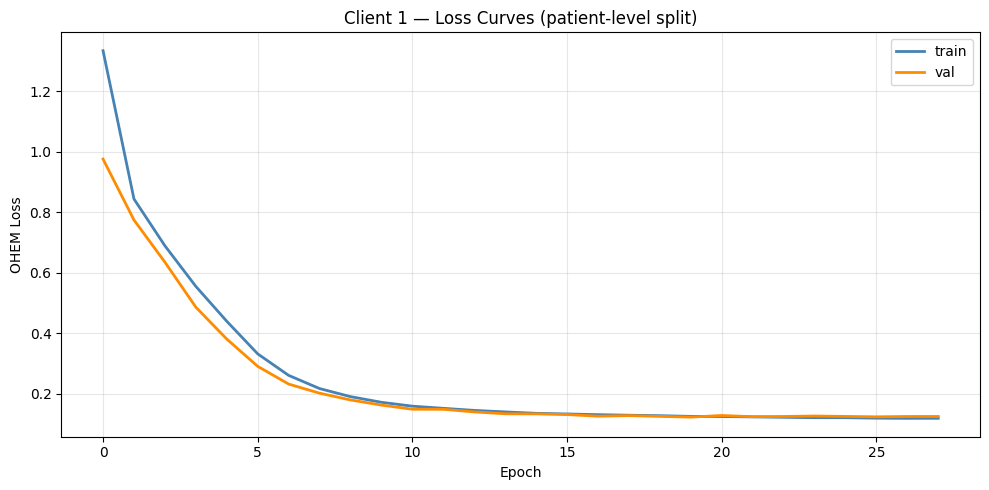


Best val loss : 0.1223
Weights       : C:\Users\Administrator\desktop\unet\weights\client1_best.pt
Test patients : ['LIDC-IDRI-0001', 'LIDC-IDRI-0012', 'LIDC-IDRI-0018', 'LIDC-IDRI-0019', 'LIDC-IDRI-0031', 'LIDC-IDRI-0039', 'LIDC-IDRI-0043', 'LIDC-IDRI-0053', 'LIDC-IDRI-0062', 'LIDC-IDRI-0067', 'LIDC-IDRI-0073', 'LIDC-IDRI-0086', 'LIDC-IDRI-0090', 'LIDC-IDRI-0095', 'LIDC-IDRI-0097', 'LIDC-IDRI-0105', 'LIDC-IDRI-0121', 'LIDC-IDRI-0123', 'LIDC-IDRI-0132', 'LIDC-IDRI-0134', 'LIDC-IDRI-0137', 'LIDC-IDRI-0141', 'LIDC-IDRI-0144', 'LIDC-IDRI-0152']


In [15]:
# CELL 5 — UNET TRAINING (patient-level split from manifest)
# ============================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
from pathlib import Path
import random
import json
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# ── UNet building blocks ──────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool = nn.MaxPool3d(2)
        self.conv = DoubleConv3D(in_ch, out_ch)
    def forward(self, x):
        return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up   = nn.ConvTranspose3d(in_ch, out_ch, 2, stride=2)
        self.conv = DoubleConv3D(in_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)

class UNet3D(nn.Module):
    def __init__(self, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1       = DoubleConv3D(1,    f)
        self.enc2       = Down(f,    f*2)
        self.enc3       = Down(f*2,  f*4)
        self.enc4       = Down(f*4,  f*8)
        self.bottleneck = Down(f*8,  f*16)
        self.dec4       = Up(f*16,   f*8)
        self.dec3       = Up(f*8,    f*4)
        self.dec2       = Up(f*4,    f*2)
        self.dec1       = Up(f*2,    f)
        self.head       = nn.Conv3d(f, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        b  = self.bottleneck(e4)
        d4 = self.dec4(b,  e4)
        d3 = self.dec3(d4, e3)
        d2 = self.dec2(d3, e2)
        d1 = self.dec1(d2, e1)
        return torch.sigmoid(self.head(d1))

# ── OHEM Loss ─────────────────────────────────────────────────
class OHEMLoss(nn.Module):
    def __init__(self, neg_pos_ratio=3, min_negatives=1000):
        super().__init__()
        self.neg_pos_ratio = neg_pos_ratio
        self.min_negatives = min_negatives

    def forward(self, pred, target):
        batch_loss = 0.0
        for i in range(pred.shape[0]):
            p = pred[i, 0]
            t = target[i, 0]
            pos_mask = t > 0.01
            neg_mask = ~pos_mask
            if pos_mask.sum() > 0:
                pos_loss = F.binary_cross_entropy(
                    p[pos_mask], t[pos_mask], reduction='mean'
                )
            else:
                pos_loss = torch.tensor(0.0, device=pred.device)
            n_pos = max(int(pos_mask.sum().item()), 1)
            n_neg = min(
                int(neg_mask.sum().item()),
                max(self.min_negatives, n_pos * self.neg_pos_ratio)
            )
            neg_losses = F.binary_cross_entropy(
                p[neg_mask],
                torch.zeros(neg_mask.sum(), device=pred.device),
                reduction='none'
            )
            hard_neg_loss = neg_losses.topk(n_neg).values.mean()
            batch_loss += pos_loss + hard_neg_loss
        return batch_loss / pred.shape[0]

# ── Dataset ───────────────────────────────────────────────────
class PatchDataset(Dataset):
    def __init__(self, pos_files, neg_files, augment=False):
        self.augment = augment
        self.items   = (
            [(str(f), 1) for f in pos_files] +
            [(str(f), 0) for f in neg_files]
        )
        random.shuffle(self.items)
        print(f"  Dataset: {len(pos_files)} pos  "
              f"{len(neg_files)} neg  total={len(self.items)}")

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        path, _ = self.items[idx]
        data    = np.load(path)
        vol     = data['vol'].astype(np.float32)
        heatmap = data['heatmap'].astype(np.float32)
        if self.augment:
            for ax in range(3):
                if random.random() > 0.5:
                    vol     = np.flip(vol,     axis=ax).copy()
                    heatmap = np.flip(heatmap, axis=ax).copy()
            k = random.randint(0, 3)
            vol     = np.rot90(vol,     k=k, axes=(1,2)).copy()
            heatmap = np.rot90(heatmap, k=k, axes=(1,2)).copy()
        return (
            torch.from_numpy(vol).unsqueeze(0),
            torch.from_numpy(heatmap).unsqueeze(0)
        )

# ── load split manifest ───────────────────────────────────────
CLIENT_PATCH_DIR = PATCH_DIR / "client1"
with open(CLIENT_PATCH_DIR / "split_manifest.json") as f:
    manifest = json.load(f)

train_pos = [Path(p) for p in manifest["train_pos"]]
train_neg = [Path(p) for p in manifest["train_neg"]]
val_pos   = [Path(p) for p in manifest["val_pos"]]
val_neg   = [Path(p) for p in manifest["val_neg"]]
# test patients use full CT inference — no patches in manifest
tst_pids  = manifest["tst_pids"]
print(f"Test patients (full CT inference): {len(tst_pids)}")
tst_pids  = manifest["tst_pids"]

print("Train set:")
train_ds = PatchDataset(train_pos, train_neg, augment=True)
print("Val set:")
val_ds   = PatchDataset(val_pos,   val_neg,   augment=False)
print(f"Test patients (held out): {len(tst_pids)}")

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0, pin_memory=True
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)

# ── model ─────────────────────────────────────────────────────
DEVICE    = 'cuda' if torch.cuda.is_available() else 'cpu'
model     = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
criterion = OHEMLoss(neg_pos_ratio=3, min_negatives=1000)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR

warmup    = LinearLR(optimizer, start_factor=0.1,
                     end_factor=1.0, total_iters=5)
cosine    = CosineAnnealingLR(optimizer, T_max=N_EPOCHS-5)
scheduler = SequentialLR(optimizer,
                          schedulers=[warmup, cosine],
                          milestones=[5])

n_params = sum(p.numel() for p in model.parameters()
               if p.requires_grad)
print(f"\nDevice          : {DEVICE}")
print(f"Model parameters: {n_params:,}")

# ── training loop ─────────────────────────────────────────────
print(f"\nStarting training — {N_EPOCHS} epochs")
print(f"{'Epoch':>6} {'Train':>10} {'Val':>10} {'LR':>12}")
print("-" * 45)

train_losses = []
val_losses   = []
best_val     = float('inf')
patience_cnt = 0
PATIENCE     = 8

for epoch in range(1, N_EPOCHS + 1):
    # train
    model.train()
    t_loss = 0.0
    n_batches = len(train_loader)
    for batch_idx, (vol, heatmap) in enumerate(train_loader):
        vol     = vol.to(DEVICE)
        heatmap = heatmap.to(DEVICE)
        optimizer.zero_grad()
        pred = model(vol)
        loss = criterion(pred, heatmap)
        loss.backward()
        optimizer.step()
        t_loss += loss.item()
        print(f"\r  Ep {epoch:02d} "
              f"[{batch_idx+1:03d}/{n_batches:03d}] "
              f"loss={loss.item():.4f}",
              end="", flush=True)
    t_loss /= n_batches
    scheduler.step()

    # validate
    model.eval()
    v_loss = 0.0
    with torch.no_grad():
        for vol, heatmap in val_loader:
            vol     = vol.to(DEVICE)
            heatmap = heatmap.to(DEVICE)
            pred    = model(vol)
            v_loss += criterion(pred, heatmap).item()
    v_loss /= len(val_loader)

    train_losses.append(t_loss)
    val_losses.append(v_loss)
    lr_now = optimizer.param_groups[0]['lr']

    star = ""
    if v_loss < best_val:
        best_val     = v_loss
        patience_cnt = 0
        torch.save(model.state_dict(),
                   WEIGHTS_DIR / "client1_best.pt")
        star = " ★"
    else:
        patience_cnt += 1

    print(f"\r{'':60}")
    print(f"  Ep {epoch:02d} | "
          f"train={t_loss:.4f}  val={v_loss:.4f}  "
          f"lr={lr_now:.6f}{star}",
          flush=True)

    if patience_cnt >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}")
        break

# save
torch.save(model.state_dict(), WEIGHTS_DIR / "client1_final.pt")

# loss plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_losses, label='train', color='steelblue',  linewidth=2)
ax.plot(val_losses,   label='val',   color='darkorange', linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('OHEM Loss')
ax.set_title('Client 1 — Loss Curves (patient-level split)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(LOG_DIR / "client1_loss_v2.png", dpi=100)
plt.show()

print(f"\nBest val loss : {best_val:.4f}")
print(f"Weights       : {WEIGHTS_DIR / 'client1_best.pt'}")
print(f"Test patients : {tst_pids}")

In [ ]:
# CELL 5 — UNET TRAINING (Jitter-Aware Fine-Tuning old one)
# ============================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
from pathlib import Path
import random
import json
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# --- Model Components (Same as your architecture) ---
class DoubleConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.block(x)

class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool = nn.MaxPool3d(2)
        self.conv = DoubleConv3D(in_ch, out_ch)
    def forward(self, x): return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up   = nn.ConvTranspose3d(in_ch, out_ch, 2, stride=2)
        self.conv = DoubleConv3D(in_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)

class UNet3D(nn.Module):
    def __init__(self, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1 = DoubleConv3D(1, f)
        self.enc2 = Down(f, f*2)
        self.enc3 = Down(f*2, f*4)
        self.enc4 = Down(f*4, f*8)
        self.bottleneck = Down(f*8, f*16)
        self.dec4 = Up(f*16, f*8)
        self.dec3 = Up(f*8, f*4)
        self.dec2 = Up(f*4, f*2)
        self.dec1 = Up(f*2, f)
        self.head = nn.Conv3d(f, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x); e2 = self.enc2(e1); e3 = self.enc3(e2); e4 = self.enc4(e3)
        b  = self.bottleneck(e4)
        d4 = self.dec4(b, e4); d3 = self.dec3(d4, e3); d2 = self.dec2(d3, e2); d1 = self.dec1(d2, e1)
        return torch.sigmoid(self.head(d1))

class OHEMLoss(nn.Module):
    def __init__(self, neg_pos_ratio=3, min_negatives=1000):
        super().__init__()
        self.neg_pos_ratio = neg_pos_ratio
        self.min_negatives = min_negatives

    def forward(self, pred, target):
        batch_loss = 0.0
        for i in range(pred.shape[0]):
            p, t = pred[i, 0], target[i, 0]
            pos_mask = t > 0.01
            neg_mask = ~pos_mask
            pos_loss = F.binary_cross_entropy(p[pos_mask], t[pos_mask]) if pos_mask.sum() > 0 else torch.tensor(0.0, device=pred.device)
            n_pos = max(int(pos_mask.sum().item()), 1)
            n_neg = min(int(neg_mask.sum().item()), max(self.min_negatives, n_pos * self.neg_pos_ratio))
            neg_losses = F.binary_cross_entropy(p[neg_mask], torch.zeros(neg_mask.sum(), device=pred.device), reduction='none')
            hard_neg_loss = neg_losses.topk(n_neg).values.mean()
            batch_loss += pos_loss + hard_neg_loss
        return batch_loss / pred.shape[0]

# --- Dataset with On-the-Fly Jitter (Optional but Recommended) ---
class PatchDataset(Dataset):
    def __init__(self, pos_files, neg_files, augment=False):
        self.augment = augment
        self.items = ([(str(f), 1) for f in pos_files] + [(str(f), 0) for f in neg_files])
        random.shuffle(self.items)

    def __len__(self): return len(self.items)

    def __getitem__(self, idx):
        path, label = self.items[idx]
        data = np.load(path)
        vol, heatmap = data['vol'].astype(np.float32), data['heatmap'].astype(np.float32)
        
        if self.augment:
            # Spatial Flips/Rotations
            for ax in range(3):
                if random.random() > 0.5:
                    vol, heatmap = np.flip(vol, axis=ax).copy(), np.flip(heatmap, axis=ax).copy()
            k = random.randint(0, 3)
            vol, heatmap = np.rot90(vol, k=k, axes=(1,2)).copy(), np.rot90(heatmap, k=k, axes=(1,2)).copy()
            
            # Internal Jitter (Shift) if patches allow it
            if random.random() > 0.5:
                shift = np.random.randint(-2, 3, size=3) # Small 2-pixel jitter
                vol = np.roll(vol, shift=shift, axis=(0,1,2))
                heatmap = np.roll(heatmap, shift=shift, axis=(0,1,2))
                
        return torch.from_numpy(vol).unsqueeze(0), torch.from_numpy(heatmap).unsqueeze(0)

# --- Configuration & Initialization ---
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
model = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)

# CRITICAL: LOAD THE "NO-JITTER" WEIGHTS
PREV_WEIGHTS = WEIGHTS_DIR / "client1_best_v1_no_jitter.pt"
if PREV_WEIGHTS.exists():
    print(f"Initializing with pre-trained weights: {PREV_WEIGHTS}")
    model.load_state_dict(torch.load(PREV_WEIGHTS, map_location=DEVICE))
else:
    print("Warning: Previous weights not found. Starting from random.")

# Lower LR for fine-tuning
FINE_TUNE_LR = LR * 0.5 
optimizer = torch.optim.Adam(model.parameters(), lr=FINE_TUNE_LR)
criterion = OHEMLoss()

# Scheduler with Warmup
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR
warmup = LinearLR(optimizer, start_factor=0.1, end_factor=1.0, total_iters=5)
cosine = CosineAnnealingLR(optimizer, T_max=N_EPOCHS-5)
scheduler = SequentialLR(optimizer, schedulers=[warmup, cosine], milestones=[5])

# --- Training Loop (Standard) ---
# [Insert your training loop here, it remains the same as your provided code]

# ── training loop ─────────────────────────────────────────────
print(f"\nStarting training — {N_EPOCHS} epochs")
print(f"{'Epoch':>6} {'Train':>10} {'Val':>10} {'LR':>12}")
print("-" * 45)

train_losses = []
val_losses   = []
best_val     = float('inf')
patience_cnt = 0
PATIENCE     = 8

for epoch in range(1, N_EPOCHS + 1):
    # train
    model.train()
    t_loss = 0.0
    n_batches = len(train_loader)
    for batch_idx, (vol, heatmap) in enumerate(train_loader):
        vol     = vol.to(DEVICE)
        heatmap = heatmap.to(DEVICE)
        optimizer.zero_grad()
        pred = model(vol)
        loss = criterion(pred, heatmap)
        loss.backward()
        optimizer.step()
        t_loss += loss.item()
        print(f"\r  Ep {epoch:02d} "
              f"[{batch_idx+1:03d}/{n_batches:03d}] "
              f"loss={loss.item():.4f}",
              end="", flush=True)
    t_loss /= n_batches
    scheduler.step()

    # validate
    model.eval()
    v_loss = 0.0
    with torch.no_grad():
        for vol, heatmap in val_loader:
            vol     = vol.to(DEVICE)
            heatmap = heatmap.to(DEVICE)
            pred    = model(vol)
            v_loss += criterion(pred, heatmap).item()
    v_loss /= len(val_loader)

    train_losses.append(t_loss)
    val_losses.append(v_loss)
    lr_now = optimizer.param_groups[0]['lr']

    star = ""
    if v_loss < best_val:
        best_val     = v_loss
        patience_cnt = 0
        torch.save(model.state_dict(),
                   WEIGHTS_DIR / "client1_best.pt")
        star = " ★"
    else:
        patience_cnt += 1

    print(f"\r{'':60}")
    print(f"  Ep {epoch:02d} | "
          f"train={t_loss:.4f}  val={v_loss:.4f}  "
          f"lr={lr_now:.6f}{star}",
          flush=True)

    if patience_cnt >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}")
        break

# save
torch.save(model.state_dict(), WEIGHTS_DIR / "client1_final.pt")

# loss plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_losses, label='train', color='steelblue',  linewidth=2)
ax.plot(val_losses,   label='val',   color='darkorange', linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('OHEM Loss')
ax.set_title('Client 1 — Loss Curves (patient-level split)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(LOG_DIR / "client1_loss_v2.png", dpi=100)
plt.show()

print(f"\nBest val loss : {best_val:.4f}")
print(f"Weights       : {WEIGHTS_DIR / 'client1_best.pt'}")
print(f"Test patients : {tst_pids}")

Model loaded: C:\Users\Administrator\desktop\unet\weights\client1_best.pt
Device      : cuda
Stride      : 20mm
Test patients: 24

Running inference...
Threshold   : 0.05
Min dist NMS: 6mm
Stride      : 20mm  (max nodule offset = 10mm)



Inference:   4%|███                                                                     | 1/24 [00:32<12:21, 32.23s/it]

  LIDC-IDRI-0001: GT= 1  det=  4  TP= 1  FP=  3  FN= 0


Inference:   8%|██████                                                                  | 2/24 [01:12<13:39, 37.25s/it]

  LIDC-IDRI-0012: GT= 9  det= 12  TP= 8  FP=  4  FN= 1


...

  LIDC-IDRI-0141: GT= 4  det=  2  TP= 2  FP=  0  FN= 2


Inference:  96%|████████████████████████████████████████████████████████████████████   | 23/24 [14:39<00:39, 39.10s/it]

  LIDC-IDRI-0144: GT= 4  det=  9  TP= 4  FP=  5  FN= 0


Inference: 100%|███████████████████████████████████████████████████████████████████████| 24/24 [15:33<00:00, 38.91s/it]

  LIDC-IDRI-0152: GT= 1  det=  3  TP= 1  FP=  2  FN= 0

RESULTS AT THRESHOLD 0.05
Patients        : 24
Total GT nodules: 52
TP              : 41
FP              : 51
FN              : 11
TN              : N/A (not meaningful in detection)
Sensitivity     : 0.788
Precision       : 0.446
F1              : 0.569
FP/scan         : 2.12

CPM : 0.489
Sensitivity at standard FP/scan points:
  0.125 FP/scan → 0.077
  0.250 FP/scan → 0.154
  0.500 FP/scan → 0.346
  1.000 FP/scan → 0.500
  2.000 FP/scan → 0.769
  4.000 FP/scan → 0.788
  8.000 FP/scan → 0.788


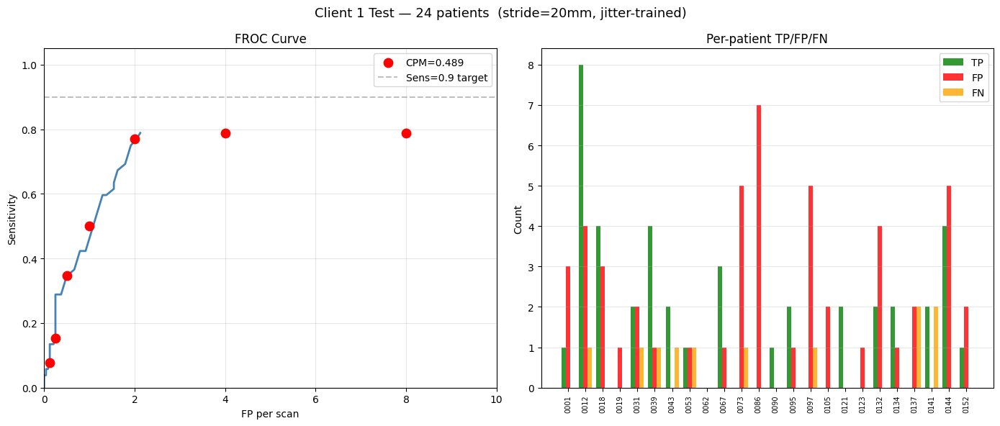


Results saved: C:\Users\Administrator\desktop\unet\logs\client1_test_results_v2.json
FROC plot    : C:\Users\Administrator\desktop\unet\logs\client1_test_froc_v2.png


In [18]:
# CELL 6 — SLIDING WINDOW INFERENCE + FULL EVALUATION #mean heat
# Uses STRIDE from Cell 0 config (currently 20mm)
# Run after Cell 5 training completes
# ============================================================
import torch
import numpy as np
import json
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import maximum_filter
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

# ── load model ────────────────────────────────────────────────
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
model  = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
model.load_state_dict(torch.load(
    WEIGHTS_DIR / "client1_best.pt", map_location=DEVICE
))
model.eval()
print(f"Model loaded: {WEIGHTS_DIR / 'client1_best.pt'}")
print(f"Device      : {DEVICE}")
print(f"Stride      : {STRIDE}mm")

# ── load test patient IDs ─────────────────────────────────────
CLIENT_PATCH_DIR = PATCH_DIR / "client1"
with open(CLIENT_PATCH_DIR / "split_manifest.json") as f:
    manifest = json.load(f)
tst_pids = manifest["tst_pids"]
print(f"Test patients: {len(tst_pids)}")

# ── functions ─────────────────────────────────────────────────
def sliding_window_inference(model, vol, mask, patch_size,
                              stride, device):
    D, H, W  = vol.shape
    p        = patch_size
    heatmap  = np.zeros((D, H, W), dtype=np.float32)
    count    = np.zeros((D, H, W), dtype=np.float32)

    coords = np.argwhere(mask > 0)
    if len(coords) == 0:
        return heatmap

    z1 = max(0,   coords[:,0].min() - p//4)
    y1 = max(0,   coords[:,1].min() - p//4)
    x1 = max(0,   coords[:,2].min() - p//4)
    z2 = min(D,   coords[:,0].max() + p//4)
    y2 = min(H,   coords[:,1].max() + p//4)
    x2 = min(W,   coords[:,2].max() + p//4)

    model.eval()
    with torch.no_grad():
        for zw in range(z1, z2-p+1, stride):
            for yw in range(y1, y2-p+1, stride):
                for xw in range(x1, x2-p+1, stride):
                    patch = vol[zw:zw+p, yw:yw+p, xw:xw+p]
                    if patch.shape != (p, p, p):
                        continue
                    if mask[zw:zw+p, yw:yw+p, xw:xw+p].mean() < 0.05:
                        continue
                    t    = torch.from_numpy(patch).unsqueeze(0).unsqueeze(0).float().to(device)
                    pred = model(t).squeeze().cpu().numpy()
                    heatmap[zw:zw+p, yw:yw+p, xw:xw+p] += pred
                    count[zw:zw+p,   yw:yw+p, xw:xw+p] += 1

    count   = np.maximum(count, 1)
    heatmap = heatmap / count
    return heatmap

def heatmap_to_detections(heatmap, threshold=0.3, min_distance_mm=6):
    neighborhood = np.ones((min_distance_mm,)*3)
    local_max    = maximum_filter(heatmap,
                                   footprint=neighborhood) == heatmap
    local_max    = local_max & (heatmap > threshold)
    coords       = np.argwhere(local_max)
    if len(coords) == 0:
        return []
    scores = heatmap[local_max]
    order  = np.argsort(scores)[::-1]
    return [(int(coords[i,0]), int(coords[i,1]),
             int(coords[i,2]), float(scores[i]))
            for i in order]

def match_detections_to_gt(detections, gt_nodules):
    matched_gt = set()
    tp_list    = []
    fp_list    = []

    for det in detections:
        dz, dy, dx, score = det
        best_dist    = float('inf')
        best_gt_idx  = -1

        for gi, nod in enumerate(gt_nodules):
            if gi in matched_gt:
                continue
            gz, gy, gx = nod["center_res"]
            radius_mm  = nod["radius_mm"]
            dist = np.sqrt((dz-gz)**2 + (dy-gy)**2 + (dx-gx)**2)
            thresh = max(radius_mm, 10.0)
            if dist < thresh and dist < best_dist:
                best_dist   = dist
                best_gt_idx = gi

        if best_gt_idx >= 0:
            tp_list.append({
                "det"     : det,
                "gt"      : gt_nodules[best_gt_idx],
                "dist_mm" : best_dist
            })
            matched_gt.add(best_gt_idx)
        else:
            fp_list.append({"det": det})

    fn_list = [{"gt": nod} for gi, nod in enumerate(gt_nodules)
               if gi not in matched_gt]

    return tp_list, fp_list, fn_list

# ── run inference ─────────────────────────────────────────────
THRESHOLD   = 0.05
MIN_DIST_MM = 6

print(f"\nRunning inference...")
print(f"Threshold   : {THRESHOLD}")
print(f"Min dist NMS: {MIN_DIST_MM}mm")
print(f"Stride      : {STRIDE}mm  (max nodule offset = {STRIDE//2}mm)\n")

all_results = []
all_scores  = []
total_gt    = 0

for pid in tqdm(tst_pids, desc="Inference"):
    vol  = np.load(PREPROC_DIR / f"{pid}.npy")
    mask = np.load(MASK_DIR    / f"{pid}.npy")

    with open(ANNOT_DIR / f"{pid}.json") as f:
        record = json.load(f)
    gt_nodules = record["consensus_nodules"]
    total_gt  += len(gt_nodules)

    heatmap = sliding_window_inference(
        model, vol, mask,
        patch_size=PATCH_SIZE,
        stride=STRIDE,
        device=DEVICE
    )

    detections = heatmap_to_detections(
        heatmap,
        threshold=THRESHOLD,
        min_distance_mm=MIN_DIST_MM
    )

    tp_list, fp_list, fn_list = match_detections_to_gt(
        detections, gt_nodules
    )

    all_results.append({
        "pid"       : pid,
        "gt_nodules": len(gt_nodules),
        "detections": len(detections),
        "tp"        : len(tp_list),
        "fp"        : len(fp_list),
        "fn"        : len(fn_list),
        "tp_list"   : tp_list,
        "fp_list"   : fp_list,
        "fn_list"   : fn_list,
    })

    for item in tp_list:
        all_scores.append((item["det"][3], 1))
    for item in fp_list:
        all_scores.append((item["det"][3], 0))

    print(f"  {pid}: GT={len(gt_nodules):2d}  "
          f"det={len(detections):3d}  "
          f"TP={len(tp_list):2d}  "
          f"FP={len(fp_list):3d}  "
          f"FN={len(fn_list):2d}")

# ── aggregate metrics ─────────────────────────────────────────
total_tp = sum(r["tp"] for r in all_results)
total_fp = sum(r["fp"] for r in all_results)
total_fn = sum(r["fn"] for r in all_results)
n_scans  = len(tst_pids)

sensitivity = total_tp / max(total_tp + total_fn, 1)
precision   = total_tp / max(total_tp + total_fp, 1)
f1          = 2 * precision * sensitivity / max(precision + sensitivity, 1e-6)
fp_per_scan = total_fp / n_scans

print(f"\n{'='*50}")
print(f"RESULTS AT THRESHOLD {THRESHOLD}")
print(f"{'='*50}")
print(f"Patients        : {n_scans}")
print(f"Total GT nodules: {total_gt}")
print(f"TP              : {total_tp}")
print(f"FP              : {total_fp}")
print(f"FN              : {total_fn}")
print(f"TN              : N/A (not meaningful in detection)")
print(f"Sensitivity     : {sensitivity:.3f}")
print(f"Precision       : {precision:.3f}")
print(f"F1              : {f1:.3f}")
print(f"FP/scan         : {fp_per_scan:.2f}")

# ── FROC curve ────────────────────────────────────────────────
if len(all_scores) > 0:
    all_scores.sort(key=lambda x: x[0], reverse=True)
    scores_arr = np.array([s[0] for s in all_scores])
    labels_arr = np.array([s[1] for s in all_scores])

    sensitivities = []
    fp_per_scans  = []

    for thresh in np.linspace(0.95, 0.01, 500):
        keep   = scores_arr >= thresh
        tp_t   = labels_arr[keep].sum()
        fp_t   = (1 - labels_arr[keep]).sum()
        sensitivities.append(float(tp_t / max(total_gt, 1)))
        fp_per_scans.append(float(fp_t / n_scans))

    # CPM at 7 standard points
    cpm_fp_points     = [0.125, 0.25, 0.5, 1, 2, 4, 8]
    cpm_sensitivities = []
    for target_fp in cpm_fp_points:
        diffs = [abs(fp - target_fp) for fp in fp_per_scans]
        idx   = np.argmin(diffs)
        cpm_sensitivities.append(sensitivities[idx])
    cpm = np.mean(cpm_sensitivities)

    print(f"\nCPM : {cpm:.3f}")
    print(f"Sensitivity at standard FP/scan points:")
    for fp_pt, sens in zip(cpm_fp_points, cpm_sensitivities):
        print(f"  {fp_pt:5.3f} FP/scan → {sens:.3f}")

    # plots
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle(f"Client 1 Test — {n_scans} patients  "
                 f"(stride={STRIDE}mm, jitter-trained)",
                 fontsize=13)

    axes[0].plot(fp_per_scans, sensitivities,
                 color='steelblue', linewidth=2)
    axes[0].scatter(cpm_fp_points, cpm_sensitivities,
                    color='red', zorder=5, s=80,
                    label=f'CPM={cpm:.3f}')
    axes[0].axhline(0.9, color='gray', linestyle='--',
                    alpha=0.5, label='Sens=0.9 target')
    axes[0].set_xlabel('FP per scan')
    axes[0].set_ylabel('Sensitivity')
    axes[0].set_title('FROC Curve')
    axes[0].set_xlim(0, 10)
    axes[0].set_ylim(0, 1.05)
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    pids_short = [r["pid"].replace("LIDC-IDRI-","") for r in all_results]
    x = np.arange(len(all_results))
    w = 0.25
    axes[1].bar(x-w, [r["tp"] for r in all_results],
                w, label='TP', color='green',  alpha=0.8)
    axes[1].bar(x,   [r["fp"] for r in all_results],
                w, label='FP', color='red',    alpha=0.8)
    axes[1].bar(x+w, [r["fn"] for r in all_results],
                w, label='FN', color='orange', alpha=0.8)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(pids_short, rotation=90, fontsize=7)
    axes[1].set_ylabel('Count')
    axes[1].set_title('Per-patient TP/FP/FN')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.savefig(LOG_DIR / "client1_test_froc_v2.png",
                dpi=100, bbox_inches='tight')
    plt.show()

else:
    print("\nNo detections made — lower THRESHOLD in Cell 0")

# ── save results ──────────────────────────────────────────────
results_summary = {
    "stride"       : STRIDE,
    "threshold"    : THRESHOLD,
    "n_patients"   : n_scans,
    "total_gt"     : total_gt,
    "total_tp"     : total_tp,
    "total_fp"     : total_fp,
    "total_fn"     : total_fn,
    "sensitivity"  : round(sensitivity, 4),
    "precision"    : round(precision,   4),
    "f1"           : round(f1,          4),
    "fp_per_scan"  : round(fp_per_scan, 4),
    "cpm"          : round(cpm if len(all_scores) > 0 else 0, 4),
    "per_patient"  : [
        {k: v for k, v in r.items()
         if k not in ("tp_list","fp_list","fn_list")}
        for r in all_results
    ]
}

with open(LOG_DIR / "client1_test_results_v2.json", "w") as f:
    json.dump(results_summary, f, indent=2)

print(f"\nResults saved: {LOG_DIR / 'client1_test_results_v2.json'}")
print(f"FROC plot    : {LOG_DIR / 'client1_test_froc_v2.png'}")

Running max heatmap on LIDC-IDRI-0001...

Max heatmap:
  global max        : 0.7447
  value at GT center: 0.7379
  max in 20mm of GT : 0.7447


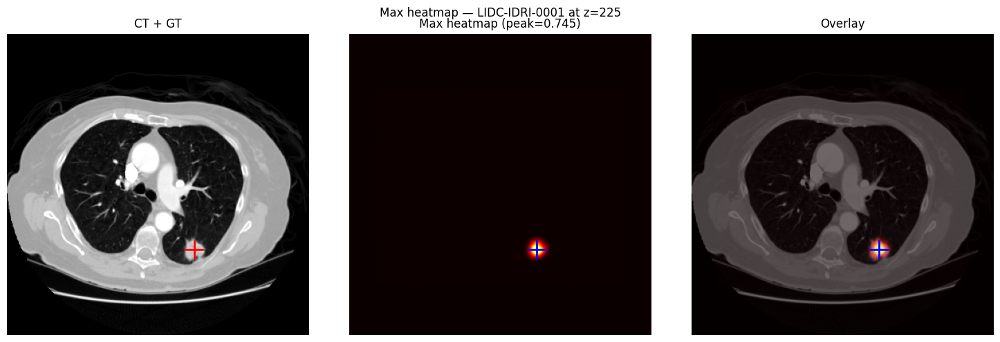

In [19]:
# compare average vs max heatmap on LIDC-IDRI-0001
pid  = "LIDC-IDRI-0001"
vol  = np.load(PREPROC_DIR / f"{pid}.npy")
mask = np.load(MASK_DIR    / f"{pid}.npy")

with open(ANNOT_DIR / f"{pid}.json") as f:
    record = json.load(f)
nod      = record["consensus_nodules"][0]
gz,gy,gx = nod["center_res"]

def sliding_window_max(model, vol, mask, patch_size, stride, device):
    """Max aggregation instead of average."""
    D, H, W  = vol.shape
    p        = patch_size
    heatmap  = np.zeros((D, H, W), dtype=np.float32)

    coords = np.argwhere(mask > 0)
    z1 = max(0, coords[:,0].min() - p//4)
    y1 = max(0, coords[:,1].min() - p//4)
    x1 = max(0, coords[:,2].min() - p//4)
    z2 = min(D, coords[:,0].max() + p//4)
    y2 = min(H, coords[:,1].max() + p//4)
    x2 = min(W, coords[:,2].max() + p//4)

    model.eval()
    with torch.no_grad():
        for zw in range(z1, z2-p+1, stride):
            for yw in range(y1, y2-p+1, stride):
                for xw in range(x1, x2-p+1, stride):
                    patch = vol[zw:zw+p, yw:yw+p, xw:xw+p]
                    if patch.shape != (p,p,p):
                        continue
                    if mask[zw:zw+p,yw:yw+p,xw:xw+p].mean() < 0.05:
                        continue
                    t    = torch.from_numpy(patch).unsqueeze(0).unsqueeze(0).float().to(device)
                    pred = model(t).squeeze().cpu().numpy()
                    heatmap[zw:zw+p, yw:yw+p, xw:xw+p] = np.maximum(
                        heatmap[zw:zw+p, yw:yw+p, xw:xw+p], pred
                    )
    return heatmap

print("Running max heatmap on LIDC-IDRI-0001...")
heatmap_max = sliding_window_max(
    model, vol, mask,
    patch_size=PATCH_SIZE,
    stride=STRIDE,
    device=DEVICE
)

print(f"\nMax heatmap:")
print(f"  global max        : {heatmap_max.max():.4f}")
print(f"  value at GT center: {heatmap_max[gz,gy,gx]:.4f}")
region = heatmap_max[max(0,gz-20):gz+20,
                     max(0,gy-20):gy+20,
                     max(0,gx-20):gx+20]
print(f"  max in 20mm of GT : {region.max():.4f}")

# visualize
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15,5))
fig.suptitle(f"Max heatmap — {pid} at z={gz}")
axes[0].imshow(vol[gz], cmap='gray', vmin=0, vmax=1)
axes[0].plot(gx, gy, 'r+', markersize=20, markeredgewidth=2)
axes[0].set_title("CT + GT")
axes[0].axis('off')
axes[1].imshow(heatmap_max[gz], cmap='hot', vmin=0, vmax=heatmap_max.max())
axes[1].plot(gx, gy, 'b+', markersize=20, markeredgewidth=2)
axes[1].set_title(f"Max heatmap (peak={heatmap_max.max():.3f})")
axes[1].axis('off')
axes[2].imshow(vol[gz], cmap='gray', vmin=0, vmax=1)
axes[2].imshow(heatmap_max[gz], cmap='hot', alpha=0.6,
               vmin=0, vmax=heatmap_max.max())
axes[2].plot(gx, gy, 'b+', markersize=20, markeredgewidth=2)
axes[2].set_title("Overlay")
axes[2].axis('off')
plt.tight_layout()
plt.savefig(LOG_DIR / "heatmap_max_check.png", dpi=90)
plt.show()

TP analysis (41 true positives):
  Distance to GT center:
    min  : 0.0mm
    max  : 13.0mm
    mean : 2.3mm
    median: 1.4mm
  Distance bins:
    < 3mm  : 31
    3-6mm  : 8
    6-10mm : 1
    >10mm  : 1

TP scores  : min=0.051  max=0.154  mean=0.083
FP scores  : min=0.051  max=0.130  mean=0.074

FN analysis (11 missed nodules):
  Radii of missed nodules:
    3.0mm  ← small
    3.1mm  ← small
    3.4mm  ← small
    4.1mm  ← small
    6.3mm  ← medium
    7.5mm  ← medium
    9.3mm  ← medium
    9.7mm  ← medium
    9.8mm  ← medium
    10.8mm  ← large
    15.7mm  ← large


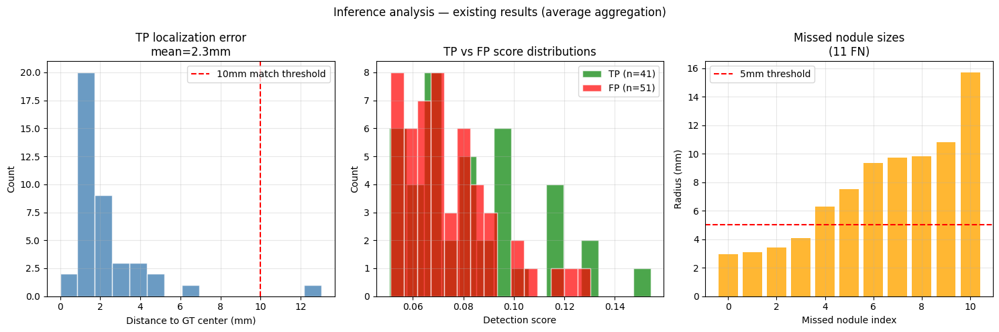


Per-patient detail:
PID                    GT   TP   FP   FN   Sens  Avg TP dist
------------------------------------------------------------
  LIDC-IDRI-0001        1    1    3    0   1.00          4.5
  LIDC-IDRI-0012        9    8    4    1   0.89          1.7
  LIDC-IDRI-0018        4    4    3    0   1.00          1.2
  LIDC-IDRI-0019        0    0    1    0   0.00          nan
  LIDC-IDRI-0031        3    2    2    1   0.67          1.0
  LIDC-IDRI-0039        5    4    1    1   0.80          1.5
  LIDC-IDRI-0043        3    2    0    1   0.67          1.9
  LIDC-IDRI-0053        2    1    1    1   0.50          6.4
  LIDC-IDRI-0062        0    0    0    0   0.00          nan
  LIDC-IDRI-0067        3    3    1    0   1.00          1.7
  LIDC-IDRI-0073        1    0    5    1   0.00          nan
  LIDC-IDRI-0086        0    0    7    0   0.00          nan
  LIDC-IDRI-0090        1    1    0    0   1.00          1.4
  LIDC-IDRI-0095        2    2    1    0   1.00          7.0
  L

In [20]:
# ANALYZE EXISTING INFERENCE RESULTS
# how far off are our TPs from GT centers?
# what are FP scores vs TP scores?
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

# ── TP distance analysis ──────────────────────────────────────
tp_distances = []
tp_scores    = []
fp_scores    = []
fn_radii     = []

for r in all_results:
    for item in r["tp_list"]:
        tp_distances.append(item["dist_mm"])
        tp_scores.append(item["det"][3])
    for item in r["fp_list"]:
        fp_scores.append(item["det"][3])
    for item in r["fn_list"]:
        fn_radii.append(item["gt"]["radius_mm"])

print(f"TP analysis ({len(tp_distances)} true positives):")
print(f"  Distance to GT center:")
print(f"    min  : {min(tp_distances):.1f}mm")
print(f"    max  : {max(tp_distances):.1f}mm")
print(f"    mean : {np.mean(tp_distances):.1f}mm")
print(f"    median: {np.median(tp_distances):.1f}mm")
print(f"  Distance bins:")
print(f"    < 3mm  : {sum(d<3  for d in tp_distances)}")
print(f"    3-6mm  : {sum(3<=d<6  for d in tp_distances)}")
print(f"    6-10mm : {sum(6<=d<10 for d in tp_distances)}")
print(f"    >10mm  : {sum(d>=10   for d in tp_distances)}")

print(f"\nTP scores  : min={min(tp_scores):.3f}  "
      f"max={max(tp_scores):.3f}  "
      f"mean={np.mean(tp_scores):.3f}")
print(f"FP scores  : min={min(fp_scores):.3f}  "
      f"max={max(fp_scores):.3f}  "
      f"mean={np.mean(fp_scores):.3f}")

print(f"\nFN analysis ({len(fn_radii)} missed nodules):")
print(f"  Radii of missed nodules:")
for r in sorted(fn_radii):
    print(f"    {r:.1f}mm  ← {'small' if r<5 else 'medium' if r<10 else 'large'}")

# ── score distribution plot ───────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Inference analysis — existing results (average aggregation)",
             fontsize=12)

axes[0].hist(tp_distances, bins=15, color='steelblue',
             edgecolor='white', alpha=0.8)
axes[0].axvline(10, color='red', linestyle='--',
                label='10mm match threshold')
axes[0].set_xlabel('Distance to GT center (mm)')
axes[0].set_ylabel('Count')
axes[0].set_title(f'TP localization error\nmean={np.mean(tp_distances):.1f}mm')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(tp_scores, bins=15, color='green',
             edgecolor='white', alpha=0.7, label=f'TP (n={len(tp_scores)})')
axes[1].hist(fp_scores, bins=15, color='red',
             edgecolor='white', alpha=0.7, label=f'FP (n={len(fp_scores)})')
axes[1].set_xlabel('Detection score')
axes[1].set_ylabel('Count')
axes[1].set_title('TP vs FP score distributions')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].bar(range(len(fn_radii)), sorted(fn_radii),
            color='orange', alpha=0.8)
axes[2].axhline(5, color='red', linestyle='--', label='5mm threshold')
axes[2].set_xlabel('Missed nodule index')
axes[2].set_ylabel('Radius (mm)')
axes[2].set_title(f'Missed nodule sizes\n({len(fn_radii)} FN)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(LOG_DIR / "inference_analysis.png", dpi=90,
            bbox_inches='tight')
plt.show()

# ── per patient detail ────────────────────────────────────────
print(f"\nPer-patient detail:")
print(f"{'PID':<20} {'GT':>4} {'TP':>4} {'FP':>4} {'FN':>4} "
      f"{'Sens':>6} {'Avg TP dist':>12}")
print("-" * 60)
for r in all_results:
    sens = r["tp"] / max(r["gt_nodules"], 1)
    avg_dist = np.mean([x["dist_mm"] for x in r["tp_list"]]) \
               if r["tp_list"] else float('nan')
    print(f"  {r['pid']:<18} {r['gt_nodules']:>4} {r['tp']:>4} "
          f"{r['fp']:>4} {r['fn']:>4} {sens:>6.2f} "
          f"{avg_dist:>12.1f}")

In [21]:
# test: does score improve as we center the window more on the nodule?
pid  = "LIDC-IDRI-0001"
vol  = np.load(PREPROC_DIR / f"{pid}.npy")

with open(ANNOT_DIR / f"{pid}.json") as f:
    record = json.load(f)
nod      = record["consensus_nodules"][0]
gz,gy,gx = nod["center_res"]

p  = PATCH_SIZE
ph = p // 2

print(f"Nodule at ({gz},{gy},{gx})")
print(f"\n{'Offset':>8} {'Pred at nodule':>16} {'Pred at center':>16} {'Peak':>8}")
print("-" * 55)

offsets = [0, 5, 10, 15, 20, 25, 30]
for offset in offsets:
    # shift patch center by offset in z only for simplicity
    patch = vol[
        max(0, gz-ph+offset):max(0, gz-ph+offset)+p,
        max(0, gy-ph):max(0, gy-ph)+p,
        max(0, gx-ph):max(0, gx-ph)+p
    ]
    if patch.shape != (p,p,p):
        continue

    with torch.no_grad():
        t    = torch.from_numpy(patch).unsqueeze(0).unsqueeze(0).float().to(DEVICE)
        pred = model(t).squeeze().cpu().numpy()

    # nodule is at (ph-offset, ph, ph) in this patch
    nod_z = max(0, min(p-1, ph-offset))
    pred_at_nodule = pred[nod_z, ph, ph]
    pred_at_center = pred[ph, ph, ph]
    peak           = pred.max()

    print(f"{offset:>8}mm  {pred_at_nodule:>16.4f}  "
          f"{pred_at_center:>16.4f}  {peak:>8.4f}")

Nodule at (225,257,223)

  Offset   Pred at nodule   Pred at center     Peak
-------------------------------------------------------
       0mm            0.7933            0.7933    0.8094
       5mm            0.7317            0.6873    0.7692
      10mm            0.6917            0.2200    0.7038
      15mm            0.7611            0.0196    0.7695
      20mm            0.6751            0.0047    0.7225
      25mm            0.0187            0.0047    0.2141
      30mm            0.0047            0.0047    0.0054


Model loaded: C:\Users\Administrator\desktop\unet\weights\client1_best.pt
Device      : cuda
Stride      : 20mm
Test patients: 24

Running inference...
Threshold      : 0.3
Min dist NMS   : 6mm
Stride         : 20mm
Aggregation    : MAX



Inference:   4%|███                                                                     | 1/24 [00:45<17:23, 45.36s/it]

  LIDC-IDRI-0001: GT= 1  det=  3  TP= 1  FP=  2  FN= 0


Inference:   8%|██████                                                                  | 2/24 [01:26<15:43, 42.89s/it]

  LIDC-IDRI-0012: GT= 9  det= 13  TP= 8  FP=  5  FN= 1


...

  LIDC-IDRI-0141: GT= 4  det=  4  TP= 3  FP=  1  FN= 1


Inference:  96%|████████████████████████████████████████████████████████████████████   | 23/24 [14:42<00:38, 38.53s/it]

  LIDC-IDRI-0144: GT= 4  det=  8  TP= 4  FP=  4  FN= 0


Inference: 100%|███████████████████████████████████████████████████████████████████████| 24/24 [15:36<00:00, 39.01s/it]

  LIDC-IDRI-0152: GT= 1  det=  3  TP= 1  FP=  2  FN= 0

RESULTS AT THRESHOLD 0.3
Patients        : 24
Total GT nodules: 52
TP              : 48
FP              : 86
FN              : 4
TN              : N/A (not meaningful in detection)
Sensitivity     : 0.923
Precision       : 0.358
F1              : 0.516
FP/scan         : 3.58

CPM : 0.690
Sensitivity at standard FP/scan points:
  0.125 FP/scan → 0.327
  0.250 FP/scan → 0.462
  0.500 FP/scan → 0.538
  1.000 FP/scan → 0.808
  2.000 FP/scan → 0.846
  4.000 FP/scan → 0.923
  8.000 FP/scan → 0.923


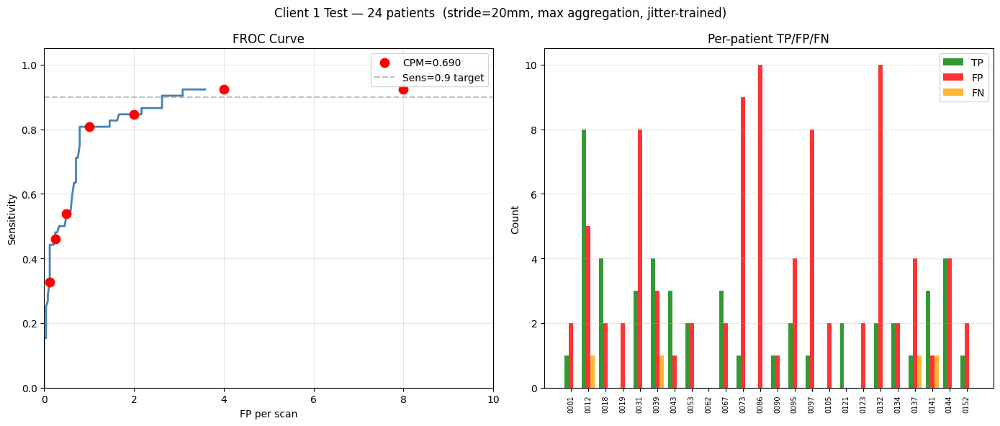


Results saved : C:\Users\Administrator\desktop\unet\logs\client1_test_results_v3.json
FROC plot     : C:\Users\Administrator\desktop\unet\logs\client1_test_froc_v3.png
all_results saved : C:\Users\Administrator\desktop\unet\logs\all_results.pkl
all_scores saved  : C:\Users\Administrator\desktop\unet\logs\all_scores.pkl


In [2]:
# CELL 6 — SLIDING WINDOW INFERENCE + FULL EVALUATION (MAX AGGREGATION)
# Uses STRIDE from Cell 0 config (currently 20mm)
# Max aggregation instead of average — preserves true peak values
# ============================================================
import torch
import numpy as np
import json
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import maximum_filter
from tqdm import tqdm
import warnings
import pickle
warnings.filterwarnings("ignore")

# ── load model ────────────────────────────────────────────────
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
model  = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
model.load_state_dict(torch.load(
    WEIGHTS_DIR / "client1_best.pt", map_location=DEVICE
))
model.eval()
print(f"Model loaded: {WEIGHTS_DIR / 'client1_best.pt'}")
print(f"Device      : {DEVICE}")
print(f"Stride      : {STRIDE}mm")

# ── load test patient IDs ─────────────────────────────────────
CLIENT_PATCH_DIR = PATCH_DIR / "client1"
with open(CLIENT_PATCH_DIR / "split_manifest.json") as f:
    manifest = json.load(f)
tst_pids = manifest["tst_pids"]
print(f"Test patients: {len(tst_pids)}")

# ── functions ─────────────────────────────────────────────────
def sliding_window_inference(model, vol, mask, patch_size,
                              stride, device):
    """
    Max aggregation — keeps highest prediction at each voxel
    across all overlapping windows. Preserves true peak values
    instead of diluting them by averaging.
    """
    D, H, W  = vol.shape
    p        = patch_size
    heatmap  = np.zeros((D, H, W), dtype=np.float32)

    coords = np.argwhere(mask > 0)
    if len(coords) == 0:
        return heatmap

    z1 = max(0,   coords[:,0].min() - p//4)
    y1 = max(0,   coords[:,1].min() - p//4)
    x1 = max(0,   coords[:,2].min() - p//4)
    z2 = min(D,   coords[:,0].max() + p//4)
    y2 = min(H,   coords[:,1].max() + p//4)
    x2 = min(W,   coords[:,2].max() + p//4)

    model.eval()
    with torch.no_grad():
        for zw in range(z1, z2-p+1, stride):
            for yw in range(y1, y2-p+1, stride):
                for xw in range(x1, x2-p+1, stride):
                    patch = vol[zw:zw+p, yw:yw+p, xw:xw+p]
                    if patch.shape != (p, p, p):
                        continue
                    if mask[zw:zw+p, yw:yw+p, xw:xw+p].mean() < 0.05:
                        continue
                    t    = torch.from_numpy(patch).unsqueeze(0).unsqueeze(0).float().to(device)
                    pred = model(t).squeeze().cpu().numpy()
                    heatmap[zw:zw+p, yw:yw+p, xw:xw+p] = np.maximum(
                        heatmap[zw:zw+p, yw:yw+p, xw:xw+p], pred
                    )
    return heatmap

def heatmap_to_detections(heatmap, threshold=0.3, min_distance_mm=6):
    neighborhood = np.ones((min_distance_mm,)*3)
    local_max    = maximum_filter(heatmap,
                                   footprint=neighborhood) == heatmap
    local_max    = local_max & (heatmap > threshold)
    coords       = np.argwhere(local_max)
    if len(coords) == 0:
        return []
    scores = heatmap[local_max]
    order  = np.argsort(scores)[::-1]
    return [(int(coords[i,0]), int(coords[i,1]),
             int(coords[i,2]), float(scores[i]))
            for i in order]

def match_detections_to_gt(detections, gt_nodules):
    matched_gt = set()
    tp_list    = []
    fp_list    = []

    for det in detections:
        dz, dy, dx, score = det
        best_dist    = float('inf')
        best_gt_idx  = -1

        for gi, nod in enumerate(gt_nodules):
            if gi in matched_gt:
                continue
            gz, gy, gx = nod["center_res"]
            radius_mm  = nod["radius_mm"]
            dist = np.sqrt((dz-gz)**2 + (dy-gy)**2 + (dx-gx)**2)
            thresh = max(radius_mm, 10.0)
            if dist < thresh and dist < best_dist:
                best_dist   = dist
                best_gt_idx = gi

        if best_gt_idx >= 0:
            tp_list.append({
                "det"     : det,
                "gt"      : gt_nodules[best_gt_idx],
                "dist_mm" : best_dist
            })
            matched_gt.add(best_gt_idx)
        else:
            fp_list.append({"det": det})

    fn_list = [{"gt": nod} for gi, nod in enumerate(gt_nodules)
               if gi not in matched_gt]

    return tp_list, fp_list, fn_list

# ── run inference ─────────────────────────────────────────────
THRESHOLD   = 0.3
MIN_DIST_MM = 6

print(f"\nRunning inference...")
print(f"Threshold      : {THRESHOLD}")
print(f"Min dist NMS   : {MIN_DIST_MM}mm")
print(f"Stride         : {STRIDE}mm")
print(f"Aggregation    : MAX\n")

all_results = []
all_scores  = []
total_gt    = 0

for pid in tqdm(tst_pids, desc="Inference"):
    vol  = np.load(PREPROC_DIR / f"{pid}.npy")
    mask = np.load(MASK_DIR    / f"{pid}.npy")

    with open(ANNOT_DIR / f"{pid}.json") as f:
        record = json.load(f)
    gt_nodules = record["consensus_nodules"]
    total_gt  += len(gt_nodules)

    heatmap = sliding_window_inference(
        model, vol, mask,
        patch_size=PATCH_SIZE,
        stride=STRIDE,
        device=DEVICE
    )

    detections = heatmap_to_detections(
        heatmap,
        threshold=THRESHOLD,
        min_distance_mm=MIN_DIST_MM
    )

    tp_list, fp_list, fn_list = match_detections_to_gt(
        detections, gt_nodules
    )

    all_results.append({
        "pid"       : pid,
        "gt_nodules": len(gt_nodules),
        "detections": len(detections),
        "tp"        : len(tp_list),
        "fp"        : len(fp_list),
        "fn"        : len(fn_list),
        "tp_list"   : tp_list,
        "fp_list"   : fp_list,
        "fn_list"   : fn_list,
    })

    for item in tp_list:
        all_scores.append((item["det"][3], 1))
    for item in fp_list:
        all_scores.append((item["det"][3], 0))

    print(f"  {pid}: GT={len(gt_nodules):2d}  "
          f"det={len(detections):3d}  "
          f"TP={len(tp_list):2d}  "
          f"FP={len(fp_list):3d}  "
          f"FN={len(fn_list):2d}")

# ── aggregate metrics ─────────────────────────────────────────
total_tp = sum(r["tp"] for r in all_results)
total_fp = sum(r["fp"] for r in all_results)
total_fn = sum(r["fn"] for r in all_results)
n_scans  = len(tst_pids)

sensitivity = total_tp / max(total_tp + total_fn, 1)
precision   = total_tp / max(total_tp + total_fp, 1)
f1          = 2 * precision * sensitivity / max(precision + sensitivity, 1e-6)
fp_per_scan = total_fp / n_scans

print(f"\n{'='*50}")
print(f"RESULTS AT THRESHOLD {THRESHOLD}")
print(f"{'='*50}")
print(f"Patients        : {n_scans}")
print(f"Total GT nodules: {total_gt}")
print(f"TP              : {total_tp}")
print(f"FP              : {total_fp}")
print(f"FN              : {total_fn}")
print(f"TN              : N/A (not meaningful in detection)")
print(f"Sensitivity     : {sensitivity:.3f}")
print(f"Precision       : {precision:.3f}")
print(f"F1              : {f1:.3f}")
print(f"FP/scan         : {fp_per_scan:.2f}")

# ── FROC curve ────────────────────────────────────────────────
if len(all_scores) > 0:
    all_scores.sort(key=lambda x: x[0], reverse=True)
    scores_arr = np.array([s[0] for s in all_scores])
    labels_arr = np.array([s[1] for s in all_scores])

    sensitivities = []
    fp_per_scans  = []

    for thresh in np.linspace(0.95, 0.01, 500):
        keep   = scores_arr >= thresh
        tp_t   = labels_arr[keep].sum()
        fp_t   = (1 - labels_arr[keep]).sum()
        sensitivities.append(float(tp_t / max(total_gt, 1)))
        fp_per_scans.append(float(fp_t / n_scans))

    # CPM at 7 standard points
    cpm_fp_points     = [0.125, 0.25, 0.5, 1, 2, 4, 8]
    cpm_sensitivities = []
    for target_fp in cpm_fp_points:
        diffs = [abs(fp - target_fp) for fp in fp_per_scans]
        idx   = np.argmin(diffs)
        cpm_sensitivities.append(sensitivities[idx])
    cpm = np.mean(cpm_sensitivities)

    print(f"\nCPM : {cpm:.3f}")
    print(f"Sensitivity at standard FP/scan points:")
    for fp_pt, sens in zip(cpm_fp_points, cpm_sensitivities):
        print(f"  {fp_pt:5.3f} FP/scan → {sens:.3f}")

    # ── plots ─────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle(
        f"Client 1 Test — {n_scans} patients  "
        f"(stride={STRIDE}mm, max aggregation, jitter-trained)",
        fontsize=12
    )

    axes[0].plot(fp_per_scans, sensitivities,
                 color='steelblue', linewidth=2)
    axes[0].scatter(cpm_fp_points, cpm_sensitivities,
                    color='red', zorder=5, s=80,
                    label=f'CPM={cpm:.3f}')
    axes[0].axhline(0.9, color='gray', linestyle='--',
                    alpha=0.5, label='Sens=0.9 target')
    axes[0].set_xlabel('FP per scan')
    axes[0].set_ylabel('Sensitivity')
    axes[0].set_title('FROC Curve')
    axes[0].set_xlim(0, 10)
    axes[0].set_ylim(0, 1.05)
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    pids_short = [r["pid"].replace("LIDC-IDRI-","") for r in all_results]
    x = np.arange(len(all_results))
    w = 0.25
    axes[1].bar(x-w, [r["tp"] for r in all_results],
                w, label='TP', color='green',  alpha=0.8)
    axes[1].bar(x,   [r["fp"] for r in all_results],
                w, label='FP', color='red',    alpha=0.8)
    axes[1].bar(x+w, [r["fn"] for r in all_results],
                w, label='FN', color='orange', alpha=0.8)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(pids_short, rotation=90, fontsize=7)
    axes[1].set_ylabel('Count')
    axes[1].set_title('Per-patient TP/FP/FN')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.savefig(LOG_DIR / "client1_test_froc_v3.png",
                dpi=100, bbox_inches='tight')
    plt.show()

else:
    print("\nNo detections — lower THRESHOLD")

# ── save results ──────────────────────────────────────────────
results_summary = {
    "stride"        : STRIDE,
    "threshold"     : THRESHOLD,
    "aggregation"   : "max",
    "n_patients"    : n_scans,
    "total_gt"      : total_gt,
    "total_tp"      : total_tp,
    "total_fp"      : total_fp,
    "total_fn"      : total_fn,
    "sensitivity"   : round(sensitivity, 4),
    "precision"     : round(precision,   4),
    "f1"            : round(f1,          4),
    "fp_per_scan"   : round(fp_per_scan, 4),
    "cpm"           : round(cpm if len(all_scores) > 0 else 0, 4),
    "per_patient"   : [
        {k: v for k, v in r.items()
         if k not in ("tp_list","fp_list","fn_list")}
        for r in all_results
    ]
}

with open(LOG_DIR / "client1_test_results_v3.json", "w") as f:
    json.dump(results_summary, f, indent=2)

print(f"\nResults saved : {LOG_DIR / 'client1_test_results_v3.json'}")
print(f"FROC plot     : {LOG_DIR / 'client1_test_froc_v3.png'}")
# ── save all_results to disk ──────────────────────────────────
with open(LOG_DIR / "all_results.pkl", "wb") as f:
    pickle.dump(all_results, f)
with open(LOG_DIR / "all_scores.pkl", "wb") as f:
    pickle.dump(all_scores, f)
print(f"all_results saved : {LOG_DIR / 'all_results.pkl'}")
print(f"all_scores saved  : {LOG_DIR / 'all_scores.pkl'}")


Type  PID                           Det pos   Pass1   Pass2   GT dist  Nearest win dist
-------------------------------------------------------------------------------------
TP    LIDC-IDRI-0001       (226,258,222)   0.745   0.795       1.7mm           11.6mm
FP    LIDC-IDRI-0001       (101,134,284)   0.582   0.645       N/A            7.1mm
FP    LIDC-IDRI-0001       (235,208,157)   0.498   0.670       N/A            5.5mm
TP    LIDC-IDRI-0012       (178,148,233)   0.767   0.771       1.0mm           16.8mm
TP    LIDC-IDRI-0012       (195,140,268)   0.727   0.691       1.0mm            8.3mm
TP    LIDC-IDRI-0012       (166,160,271)   0.697   0.703       2.0mm            7.5mm
TP    LIDC-IDRI-0012       (160,219,287)   0.685   0.723       1.0mm            8.6mm
TP    LIDC-IDRI-0012       (132,160,289)   0.683   0.729       1.0mm            6.7mm
TP    LIDC-IDRI-0012       (197,144,249)   0.671   0.647       1.4mm           11.9mm
TP    LIDC-IDRI-0012       (112,153,101)   0.646   0.74

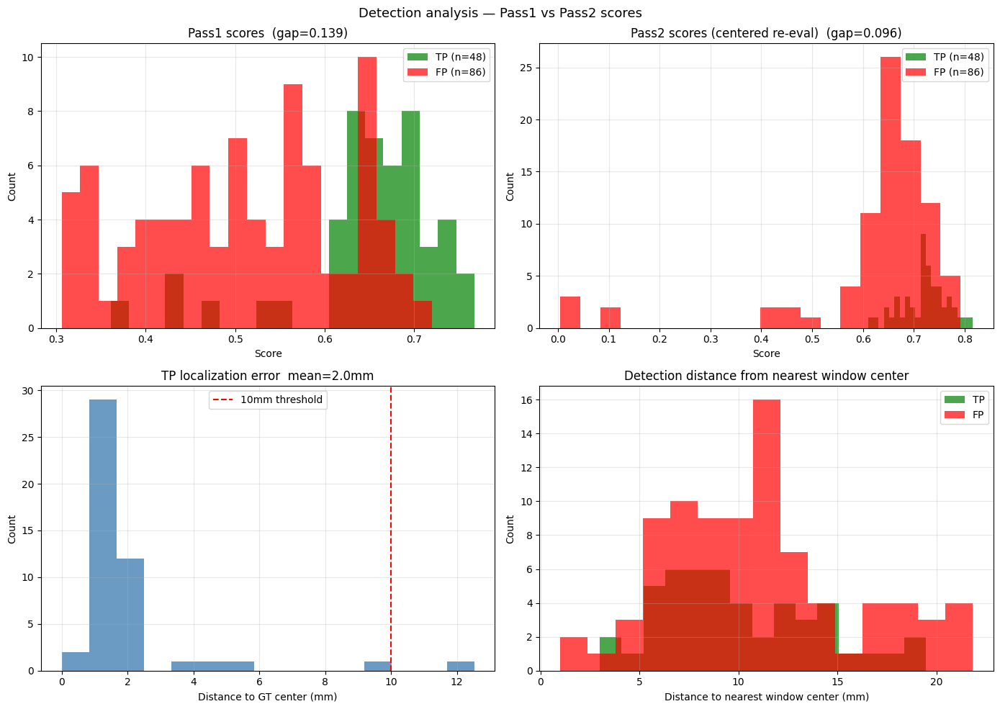

In [3]:
# CELL 6-ANALYSIS — heatmap max locations, distances, pass2 scores
# Run after Cell 6 — uses all_results from memory or disk
# ============================================================
import torch
import numpy as np
import matplotlib.pyplot as plt
import pickle
from pathlib import Path

# reload if needed
if 'all_results' not in dir():
    with open(LOG_DIR / "all_results.pkl", "rb") as f:
        all_results = pickle.load(f)
    print(f"Loaded {len(all_results)} patient results")

p  = PATCH_SIZE
ph = p // 2

# ── per-detection analysis ────────────────────────────────────
print(f"\n{'Type':<5} {'PID':<20} {'Det pos':>16} "
      f"{'Pass1':>7} {'Pass2':>7} {'GT dist':>9} "
      f"{'Nearest win dist':>17}")
print("-" * 85)

all_tp_pass1 = []
all_tp_pass2 = []
all_fp_pass1 = []
all_fp_pass2 = []
all_tp_gt_dists = []
all_tp_win_dists = []
all_fp_win_dists = []

for r in all_results:
    pid  = r["pid"]
    vol  = np.load(PREPROC_DIR / f"{pid}.npy")
    mask = np.load(MASK_DIR    / f"{pid}.npy")
    D, H, W = vol.shape

    with open(ANNOT_DIR / f"{pid}.json") as f:
        record = json.load(f)

    # rebuild window centers for this patient
    coords = np.argwhere(mask > 0)
    z1 = max(0, coords[:,0].min() - p//4)
    y1 = max(0, coords[:,1].min() - p//4)
    x1 = max(0, coords[:,2].min() - p//4)
    z2 = min(D, coords[:,0].max() + p//4)
    y2 = min(H, coords[:,1].max() + p//4)
    x2 = min(W, coords[:,2].max() + p//4)

    z_centers = [zw+ph for zw in range(z1, z2-p+1, STRIDE)]
    y_centers = [yw+ph for yw in range(y1, y2-p+1, STRIDE)]
    x_centers = [xw+ph for xw in range(x1, x2-p+1, STRIDE)]

    def nearest_win_dist(dz, dy, dx):
        nz = min(z_centers, key=lambda c: abs(c-dz))
        ny = min(y_centers, key=lambda c: abs(c-dy))
        nx = min(x_centers, key=lambda c: abs(c-dx))
        return float(np.sqrt((dz-nz)**2+(dy-ny)**2+(dx-nx)**2))

    def pass2(dz, dy, dx):
        zw = max(0, min(D-p, dz-ph))
        yw = max(0, min(H-p, dy-ph))
        xw = max(0, min(W-p, dx-ph))
        patch = vol[zw:zw+p, yw:yw+p, xw:xw+p]
        if patch.shape != (p,p,p):
            return 0.0
        with torch.no_grad():
            t    = torch.from_numpy(patch).unsqueeze(0).unsqueeze(0).float().to(DEVICE)
            pred = model(t).squeeze().cpu().numpy()
        return float(pred[ph,ph,ph])

    # TPs
    for item in r["tp_list"]:
        dz, dy, dx, s1 = item["det"]
        s2   = pass2(dz, dy, dx)
        wdist = nearest_win_dist(dz, dy, dx)
        gdist = item["dist_mm"]
        all_tp_pass1.append(s1)
        all_tp_pass2.append(s2)
        all_tp_gt_dists.append(gdist)
        all_tp_win_dists.append(wdist)
        print(f"{'TP':<5} {pid:<20} ({dz:3d},{dy:3d},{dx:3d}) "
              f"{s1:>7.3f} {s2:>7.3f} {gdist:>9.1f}mm "
              f"{wdist:>14.1f}mm")

    # FPs
    for item in r["fp_list"]:
        dz, dy, dx, s1 = item["det"]
        s2    = pass2(dz, dy, dx)
        wdist = nearest_win_dist(dz, dy, dx)
        all_fp_pass1.append(s1)
        all_fp_pass2.append(s2)
        all_fp_win_dists.append(wdist)
        print(f"{'FP':<5} {pid:<20} ({dz:3d},{dy:3d},{dx:3d}) "
              f"{s1:>7.3f} {s2:>7.3f} {'N/A':>9} "
              f"{wdist:>14.1f}mm")

# ── summary stats ─────────────────────────────────────────────
print(f"\n{'='*60}")
print(f"SUMMARY")
print(f"{'='*60}")
print(f"\nTP ({len(all_tp_pass1)} detections):")
print(f"  Pass1 score : mean={np.mean(all_tp_pass1):.3f}  "
      f"min={min(all_tp_pass1):.3f}  max={max(all_tp_pass1):.3f}")
print(f"  Pass2 score : mean={np.mean(all_tp_pass2):.3f}  "
      f"min={min(all_tp_pass2):.3f}  max={max(all_tp_pass2):.3f}")
print(f"  GT dist     : mean={np.mean(all_tp_gt_dists):.1f}mm  "
      f"max={max(all_tp_gt_dists):.1f}mm")
print(f"  Win dist    : mean={np.mean(all_tp_win_dists):.1f}mm  "
      f"max={max(all_tp_win_dists):.1f}mm")

print(f"\nFP ({len(all_fp_pass1)} detections):")
print(f"  Pass1 score : mean={np.mean(all_fp_pass1):.3f}  "
      f"min={min(all_fp_pass1):.3f}  max={max(all_fp_pass1):.3f}")
print(f"  Pass2 score : mean={np.mean(all_fp_pass2):.3f}  "
      f"min={min(all_fp_pass2):.3f}  max={max(all_fp_pass2):.3f}")
print(f"  Win dist    : mean={np.mean(all_fp_win_dists):.1f}mm  "
      f"max={max(all_fp_win_dists):.1f}mm")

print(f"\nPass2 TP vs FP gap: "
      f"{np.mean(all_tp_pass2)-np.mean(all_fp_pass2):.3f}")
print(f"Pass1 TP vs FP gap: "
      f"{np.mean(all_tp_pass1)-np.mean(all_fp_pass1):.3f}")

# ── find optimal pass2 threshold ─────────────────────────────
print(f"\nPass2 threshold sweep:")
print(f"{'Thresh':>8} {'TP kept':>8} {'FP kept':>8} "
      f"{'Sens':>7} {'Prec':>7}")
print("-" * 45)

total_gt_count = sum(r["gt_nodules"] for r in all_results)
for thresh in np.arange(0.1, 0.9, 0.05):
    tp_kept = sum(1 for s in all_tp_pass2 if s >= thresh)
    fp_kept = sum(1 for s in all_fp_pass2 if s >= thresh)
    fn      = total_gt_count - tp_kept
    sens    = tp_kept / max(total_gt_count, 1)
    prec    = tp_kept / max(tp_kept + fp_kept, 1)
    print(f"{thresh:>8.2f} {tp_kept:>8} {fp_kept:>8} "
          f"{sens:>7.3f} {prec:>7.3f}")

# ── plots ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Detection analysis — Pass1 vs Pass2 scores", fontsize=13)

# pass1 score distribution
axes[0,0].hist(all_tp_pass1, bins=20, color='green',
               alpha=0.7, label=f'TP (n={len(all_tp_pass1)})')
axes[0,0].hist(all_fp_pass1, bins=20, color='red',
               alpha=0.7, label=f'FP (n={len(all_fp_pass1)})')
axes[0,0].set_xlabel('Score')
axes[0,0].set_ylabel('Count')
axes[0,0].set_title(f'Pass1 scores  '
                     f'(gap={np.mean(all_tp_pass1)-np.mean(all_fp_pass1):.3f})')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# pass2 score distribution
axes[0,1].hist(all_tp_pass2, bins=20, color='green',
               alpha=0.7, label=f'TP (n={len(all_tp_pass2)})')
axes[0,1].hist(all_fp_pass2, bins=20, color='red',
               alpha=0.7, label=f'FP (n={len(all_fp_pass2)})')
axes[0,1].set_xlabel('Score')
axes[0,1].set_ylabel('Count')
axes[0,1].set_title(f'Pass2 scores (centered re-eval)  '
                     f'(gap={np.mean(all_tp_pass2)-np.mean(all_fp_pass2):.3f})')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# TP GT distance distribution
axes[1,0].hist(all_tp_gt_dists, bins=15, color='steelblue',
               alpha=0.8)
axes[1,0].axvline(10, color='red', linestyle='--',
                   label='10mm threshold')
axes[1,0].set_xlabel('Distance to GT center (mm)')
axes[1,0].set_ylabel('Count')
axes[1,0].set_title(f'TP localization error  '
                     f'mean={np.mean(all_tp_gt_dists):.1f}mm')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# window distance distribution for TPs vs FPs
axes[1,1].hist(all_tp_win_dists, bins=15, color='green',
               alpha=0.7, label='TP')
axes[1,1].hist(all_fp_win_dists, bins=15, color='red',
               alpha=0.7, label='FP')
axes[1,1].set_xlabel('Distance to nearest window center (mm)')
axes[1,1].set_ylabel('Count')
axes[1,1].set_title('Detection distance from nearest window center')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(LOG_DIR / "detection_analysis.png", dpi=90,
            bbox_inches='tight')
plt.show()

In [23]:
# analyze max aggregation results
import numpy as np
import matplotlib.pyplot as plt

tp_distances = []
tp_scores    = []
fp_scores    = []
fn_radii     = []

for r in all_results:
    for item in r["tp_list"]:
        tp_distances.append(item["dist_mm"])
        tp_scores.append(item["det"][3])
    for item in r["fp_list"]:
        fp_scores.append(item["det"][3])
    for item in r["fn_list"]:
        fn_radii.append(item["gt"]["radius_mm"])

print(f"TP scores: min={min(tp_scores):.3f}  "
      f"max={max(tp_scores):.3f}  "
      f"mean={np.mean(tp_scores):.3f}")
print(f"FP scores: min={min(fp_scores):.3f}  "
      f"max={max(fp_scores):.3f}  "
      f"mean={np.mean(fp_scores):.3f}")
print(f"Gap: {np.mean(tp_scores)-np.mean(fp_scores):.3f}")

print(f"\nTP distances: mean={np.mean(tp_distances):.1f}mm  "
      f"max={max(tp_distances):.1f}mm")

print(f"\nMissed nodules ({len(fn_radii)} FN):")
for r in sorted(fn_radii):
    print(f"  {r:.1f}mm")

# find optimal threshold
print(f"\nThreshold sweep:")
print(f"{'Thresh':>8} {'TP':>5} {'FP':>5} {'FN':>5} "
      f"{'Sens':>7} {'Prec':>7} {'FP/scan':>8}")
print("-" * 50)

all_det_scores = [(s, 1) for s in tp_scores] + \
                 [(s, 0) for s in fp_scores]
all_det_scores.sort(key=lambda x: x[0], reverse=True)
scores_arr = np.array([s[0] for s in all_det_scores])
labels_arr = np.array([s[1] for s in all_det_scores])
total_gt   = 52
n_scans    = 24

for thresh in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    keep  = scores_arr >= thresh
    tp_t  = int(labels_arr[keep].sum())
    fp_t  = int((1-labels_arr[keep]).sum())
    fn_t  = total_gt - tp_t
    sens  = tp_t / total_gt
    prec  = tp_t / max(tp_t+fp_t, 1)
    fps   = fp_t / n_scans
    print(f"{thresh:>8.1f} {tp_t:>5} {fp_t:>5} {fn_t:>5} "
          f"{sens:>7.3f} {prec:>7.3f} {fps:>8.2f}")

TP scores: min=0.361  max=0.767  mean=0.650
FP scores: min=0.306  max=0.720  mean=0.511
Gap: 0.139

TP distances: mean=2.0mm  max=12.5mm

Missed nodules (4 FN):
  3.1mm
  3.4mm
  4.1mm
  15.7mm

Threshold sweep:
  Thresh    TP    FP    FN    Sens    Prec  FP/scan
--------------------------------------------------
     0.1    48    86     4   0.923   0.358     3.58
     0.2    48    86     4   0.923   0.358     3.58
     0.3    48    86     4   0.923   0.358     3.58
     0.4    47    69     5   0.904   0.405     2.88
     0.5    44    47     8   0.846   0.484     1.96
     0.6    42    21    10   0.808   0.667     0.88
     0.7    11     1    41   0.212   0.917     0.04
     0.8     0     0    52   0.000   0.000     0.00


Model loaded — Device: cuda
Loaded 24 patient results

Selected patients: ['LIDC-IDRI-0043', 'LIDC-IDRI-0086', 'LIDC-IDRI-0141']

Processing LIDC-IDRI-0043...
  Heatmap: max=0.673  saved to heatmap_LIDC-IDRI-0043.npy


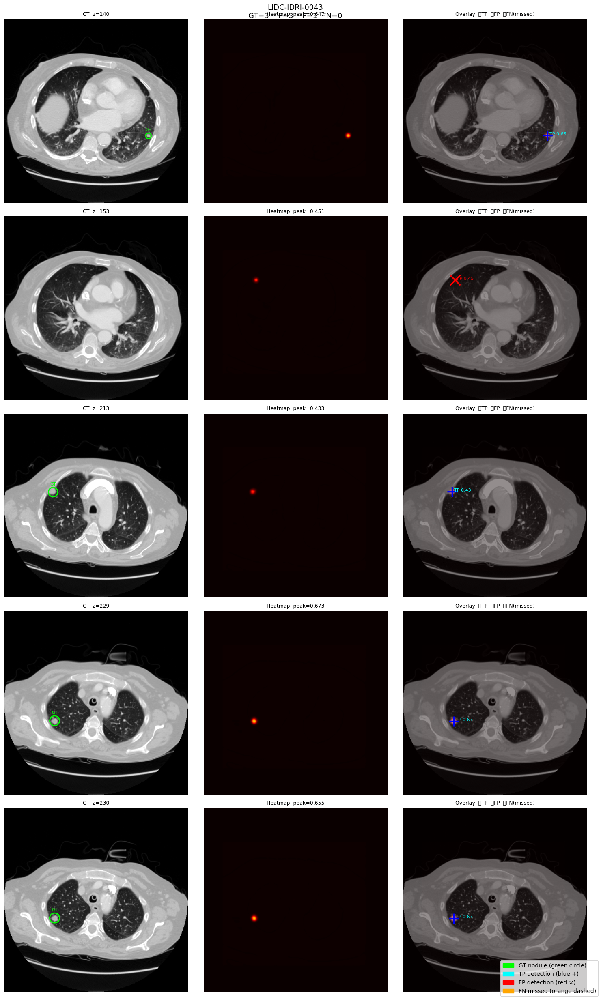

  Saved: C:\Users\Administrator\desktop\unet\logs\visual_LIDC-IDRI-0043.png

Processing LIDC-IDRI-0086...
  Heatmap: max=0.666  saved to heatmap_LIDC-IDRI-0086.npy


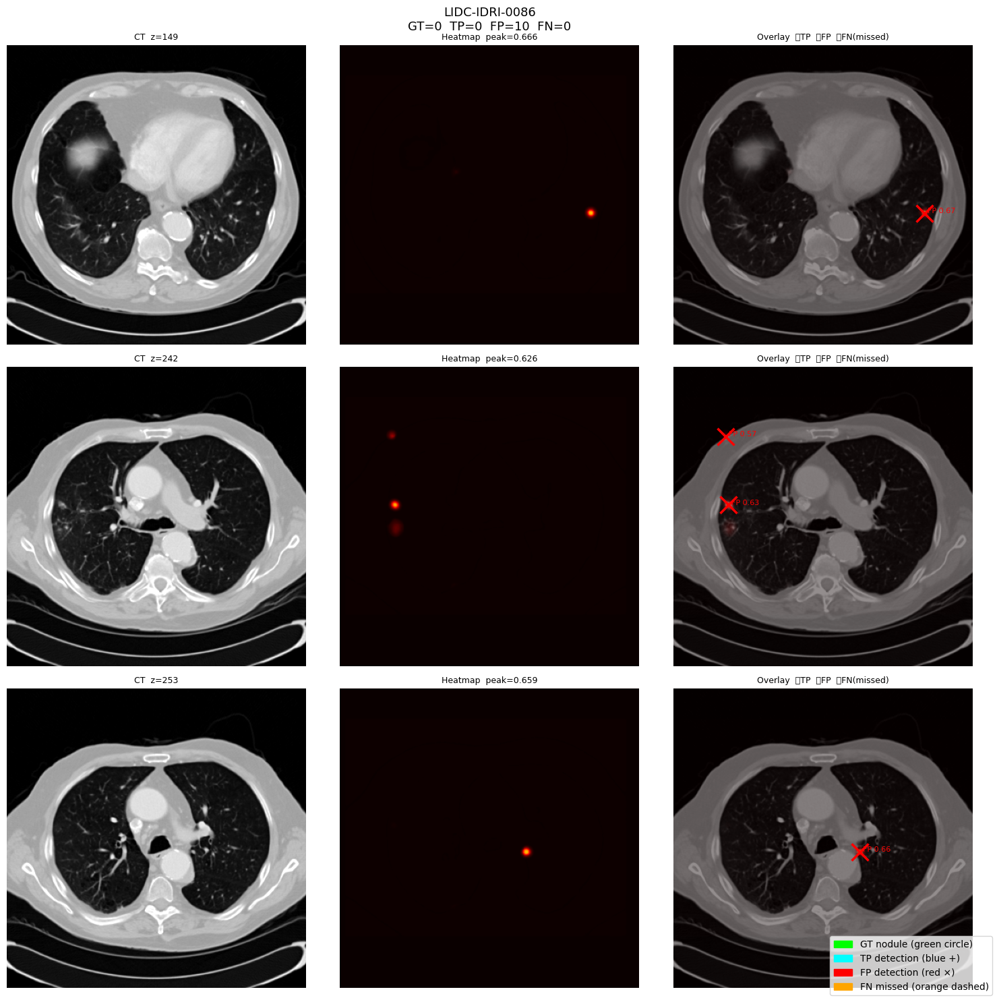

  Saved: C:\Users\Administrator\desktop\unet\logs\visual_LIDC-IDRI-0086.png

Processing LIDC-IDRI-0141...
  Heatmap: max=0.723  saved to heatmap_LIDC-IDRI-0141.npy


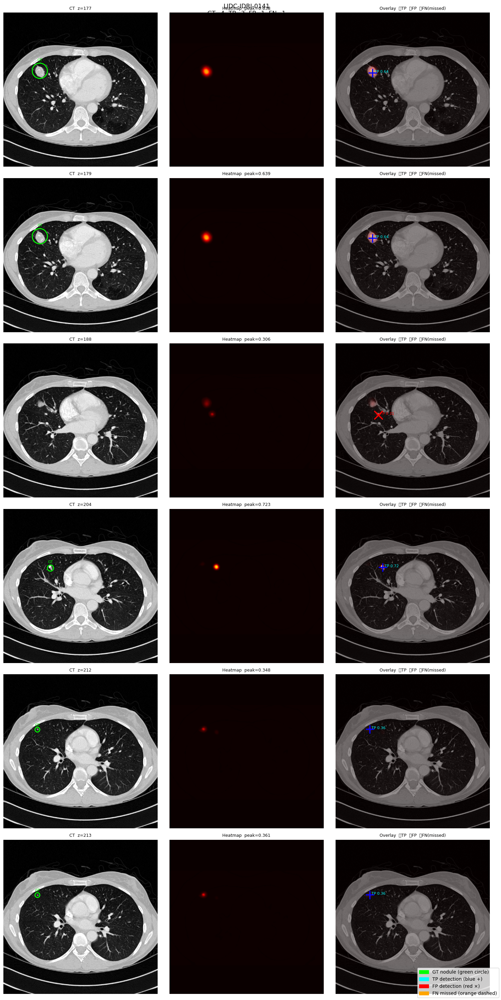

  Saved: C:\Users\Administrator\desktop\unet\logs\visual_LIDC-IDRI-0141.png

All done.


In [5]:
# CELL 6-VISUAL — heatmap overlay on selected test CT slices
# Recomputes heatmap only for selected patients
# ============================================================
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pickle
import json
from pathlib import Path

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# ── UNet definition ───────────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.block(x)

class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool = nn.MaxPool3d(2)
        self.conv = DoubleConv3D(in_ch, out_ch)
    def forward(self, x): return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up   = nn.ConvTranspose3d(in_ch, out_ch, 2, stride=2)
        self.conv = DoubleConv3D(in_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)

class UNet3D(nn.Module):
    def __init__(self, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1       = DoubleConv3D(1,   f)
        self.enc2       = Down(f,   f*2)
        self.enc3       = Down(f*2, f*4)
        self.enc4       = Down(f*4, f*8)
        self.bottleneck = Down(f*8, f*16)
        self.dec4       = Up(f*16, f*8)
        self.dec3       = Up(f*8,  f*4)
        self.dec2       = Up(f*4,  f*2)
        self.dec1       = Up(f*2,  f)
        self.head       = nn.Conv3d(f, 1, 1)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        b  = self.bottleneck(e4)
        d4 = self.dec4(b,  e4)
        d3 = self.dec3(d4, e3)
        d2 = self.dec2(d3, e2)
        d1 = self.dec1(d2, e1)
        return torch.sigmoid(self.head(d1))

# ── load model ────────────────────────────────────────────────
model = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
model.load_state_dict(torch.load(
    WEIGHTS_DIR / "client1_best.pt", map_location=DEVICE
))
model.eval()
print(f"Model loaded — Device: {DEVICE}")

# ── load results ──────────────────────────────────────────────
with open(LOG_DIR / "all_results.pkl", "rb") as f:
    all_results = pickle.load(f)
print(f"Loaded {len(all_results)} patient results")

# ── pick 3 patients manually — one clean, one FP-heavy, one FN
# change these to any pids you want to visualize
selected = [
    "LIDC-IDRI-0043",   # GT=3 TP=3 FP=1 FN=0 — clean detection
    "LIDC-IDRI-0086",   # GT=0 TP=0 FP=10     — worst FP case
    "LIDC-IDRI-0141",   # GT=4 TP=3 FP=1 FN=1 — has a miss
]
print(f"\nSelected patients: {selected}")

# ── sliding window (max aggregation) ─────────────────────────
def compute_heatmap(model, vol, mask, patch_size, stride, device):
    D, H, W  = vol.shape
    p        = patch_size
    heatmap  = np.zeros((D, H, W), dtype=np.float32)
    coords   = np.argwhere(mask > 0)
    if len(coords) == 0:
        return heatmap
    z1 = max(0, coords[:,0].min() - p//4)
    y1 = max(0, coords[:,1].min() - p//4)
    x1 = max(0, coords[:,2].min() - p//4)
    z2 = min(D, coords[:,0].max() + p//4)
    y2 = min(H, coords[:,1].max() + p//4)
    x2 = min(W, coords[:,2].max() + p//4)
    model.eval()
    with torch.no_grad():
        for zw in range(z1, z2-p+1, stride):
            for yw in range(y1, y2-p+1, stride):
                for xw in range(x1, x2-p+1, stride):
                    patch = vol[zw:zw+p, yw:yw+p, xw:xw+p]
                    if patch.shape != (p,p,p):
                        continue
                    if mask[zw:zw+p,yw:yw+p,xw:xw+p].mean() < 0.05:
                        continue
                    t    = torch.from_numpy(patch).unsqueeze(0).unsqueeze(0).float().to(device)
                    pred = model(t).squeeze().cpu().numpy()
                    heatmap[zw:zw+p,yw:yw+p,xw:xw+p] = np.maximum(
                        heatmap[zw:zw+p,yw:yw+p,xw:xw+p], pred
                    )
    return heatmap

# ── visualize ─────────────────────────────────────────────────
for pid in selected:
    print(f"\nProcessing {pid}...")

    vol  = np.load(PREPROC_DIR / f"{pid}.npy")
    mask = np.load(MASK_DIR    / f"{pid}.npy")

    with open(ANNOT_DIR / f"{pid}.json") as f:
        record = json.load(f)
    gt_nodules = record["consensus_nodules"]

    r = next(x for x in all_results if x["pid"] == pid)

    # compute heatmap for this patient only
    heatmap = compute_heatmap(
        model, vol, mask,
        patch_size=PATCH_SIZE,
        stride=STRIDE,
        device=DEVICE
    )

    # save heatmap for future use
    np.save(LOG_DIR / f"heatmap_{pid}.npy", heatmap)
    print(f"  Heatmap: max={heatmap.max():.3f}  "
          f"saved to heatmap_{pid}.npy")

    # collect slices to show
    show_slices = set()
    for nod in gt_nodules:
        show_slices.add(nod["center_res"][0])
    for item in r["tp_list"]:
        show_slices.add(item["det"][0])
    for item in r["fp_list"][:3]:  # max 3 FP slices
        show_slices.add(item["det"][0])
    for item in r["fn_list"]:
        show_slices.add(item["gt"]["center_res"][0])
    show_slices = sorted(show_slices)[:6]

    if not show_slices:
        show_slices = [vol.shape[0]//2]

    n = len(show_slices)
    fig, axes = plt.subplots(n, 3, figsize=(15, 5*n))
    if n == 1:
        axes = [axes]
    fig.suptitle(
        f"{pid}\nGT={r['gt_nodules']}  "
        f"TP={r['tp']}  FP={r['fp']}  FN={r['fn']}",
        fontsize=13
    )

    for row, z in enumerate(show_slices):
        ct_sl   = vol[z]
        heat_sl = heatmap[z]

        # col 0 — CT + GT circles
        axes[row][0].imshow(ct_sl, cmap='gray', vmin=0, vmax=1)
        for nod in gt_nodules:
            gz, gy, gx = nod["center_res"]
            if abs(gz-z) <= 5:
                c = plt.Circle((gx,gy), max(5,nod["radius_mm"]),
                                color='lime', fill=False, linewidth=2)
                axes[row][0].add_patch(c)
                axes[row][0].text(gx, gy-nod["radius_mm"]-4,
                                   'GT', color='lime',
                                   fontsize=8, ha='center')
        axes[row][0].set_title(f"CT  z={z}", fontsize=9)
        axes[row][0].axis('off')

        # col 1 — heatmap only
        axes[row][1].imshow(heat_sl, cmap='hot', vmin=0, vmax=1)
        axes[row][1].set_title(
            f"Heatmap  peak={heat_sl.max():.3f}", fontsize=9)
        axes[row][1].axis('off')

        # col 2 — overlay + detections
        axes[row][2].imshow(ct_sl, cmap='gray', vmin=0, vmax=1)
        axes[row][2].imshow(heat_sl, cmap='hot',
                             alpha=0.45, vmin=0, vmax=1)

        # TPs — blue cross
        for item in r["tp_list"]:
            dz,dy,dx,sc = item["det"]
            if abs(dz-z) <= 5:
                axes[row][2].plot(dx, dy, 'b+',
                                   markersize=18,
                                   markeredgewidth=2.5)
                axes[row][2].text(dx+4, dy,
                                   f'TP {sc:.2f}',
                                   color='cyan', fontsize=8)

        # FPs — red X
        for item in r["fp_list"]:
            dz,dy,dx,sc = item["det"]
            if abs(dz-z) <= 5:
                axes[row][2].plot(dx, dy, 'rx',
                                   markersize=18,
                                   markeredgewidth=2.5)
                axes[row][2].text(dx+4, dy,
                                   f'FP {sc:.2f}',
                                   color='red', fontsize=8)

        # FNs — orange dashed circle
        for item in r["fn_list"]:
            gz,gy,gx = item["gt"]["center_res"]
            r_mm     = item["gt"]["radius_mm"]
            if abs(gz-z) <= 5:
                c = plt.Circle((gx,gy), max(5,r_mm),
                                color='orange', fill=False,
                                linewidth=2, linestyle='--')
                axes[row][2].add_patch(c)
                axes[row][2].text(gx, gy-r_mm-4,
                                   'FN', color='orange',
                                   fontsize=8, ha='center')

        axes[row][2].set_title("Overlay  "
                                "🔵TP  🔴FP  🟠FN(missed)",
                                fontsize=9)
        axes[row][2].axis('off')

    # legend
    legend_elements = [
        mpatches.Patch(color='lime',   label='GT nodule (green circle)'),
        mpatches.Patch(color='cyan',   label='TP detection (blue +)'),
        mpatches.Patch(color='red',    label='FP detection (red ×)'),
        mpatches.Patch(color='orange', label='FN missed (orange dashed)'),
    ]
    fig.legend(handles=legend_elements,
               loc='lower right', fontsize=10)

    plt.tight_layout()
    out = LOG_DIR / f"visual_{pid}.png"
    plt.savefig(out, dpi=100, bbox_inches='tight')
    plt.show()
    print(f"  Saved: {out}")

print("\nAll done.")


Device: cuda
Stage 1 model loaded: client1_best.pt (jitter trained)
Stage 2 model loaded: client1_best_v1_no_jitter.pt (centered)
Test patients: 24

Stage 1: sliding window inference...
Threshold : 0.3  Stride : 20mm  NMS : 6mm



Stage 1:   4%|███                                                                       | 1/24 [00:31<12:08, 31.67s/it]

  LIDC-IDRI-0001: GT= 1  det=  3  TP= 1  FP=  2  FN= 0


Stage 1:   8%|██████▏                                                                   | 2/24 [01:12<13:29, 36.79s/it]

  LIDC-IDRI-0012: GT= 9  det= 13  TP= 8  FP=  5  FN= 1


...

  LIDC-IDRI-0141: GT= 4  det=  4  TP= 3  FP=  1  FN= 1


Stage 1:  96%|█████████████████████████████████████████████████████████████████████▉   | 23/24 [14:13<00:37, 37.91s/it]

  LIDC-IDRI-0144: GT= 4  det=  8  TP= 4  FP=  4  FN= 0


Stage 1: 100%|█████████████████████████████████████████████████████████████████████████| 24/24 [15:05<00:00, 37.74s/it]


  LIDC-IDRI-0152: GT= 1  det=  3  TP= 1  FP=  2  FN= 0

all_results saved.

STAGE 1 RESULTS (sliding window, threshold=0.3)
Patients        : 24
Total GT nodules: 52
TP=48  FP=86  FN=4
Sensitivity : 0.923
Precision   : 0.358
F1          : 0.516
FP/scan     : 3.58

STAGE 2 ANALYSIS (old centered model pass2)
Pass1  TP mean=0.650  FP mean=0.511  gap=0.139
Pass2  TP mean=0.876  FP mean=0.747  gap=0.129

Pass2 threshold sweep (old centered model):
  Thresh  TP kept  FP kept    Sens    Prec  FP/scan
--------------------------------------------------
    0.10       48       80   0.923   0.375     3.33 ★
    0.15       48       80   0.923   0.375     3.33
    0.20       48       80   0.923   0.375     3.33
    0.25       48       80   0.923   0.375     3.33
    0.30       48       80   0.923   0.375     3.33
    0.35       48       79   0.923   0.378     3.29 ★
    0.40       48       78   0.923   0.381     3.25 ★
    0.45       48       78   0.923   0.381     3.25
    0.50       48       77 

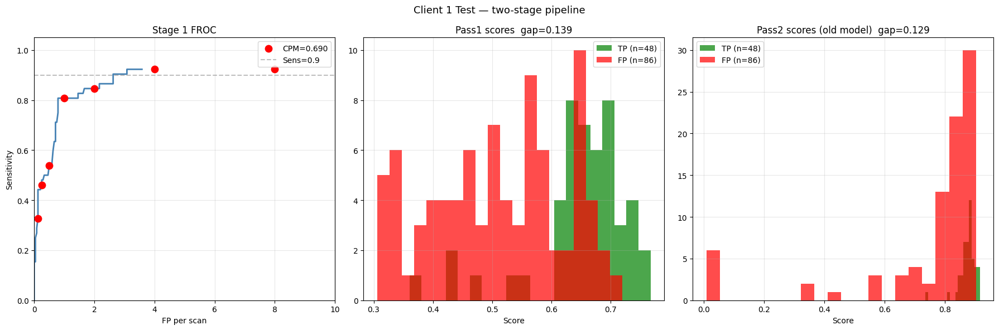


Results saved : C:\Users\Administrator\desktop\unet\logs\client1_test_results_v4.json
Plot saved    : C:\Users\Administrator\desktop\unet\logs\two_stage_analysis.png
Raw results   : C:\Users\Administrator\desktop\unet\logs\all_results.pkl


In [4]:
# CELL 6 — SLIDING WINDOW INFERENCE + FULL EVALUATION (MAX AGGREGATION)
# + TWO-STAGE: Pass2 using old centered model for FP reduction
# ============================================================
import torch
import torch.nn as nn
import numpy as np
import json
import pickle
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import maximum_filter
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

# ── UNet definition ───────────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool = nn.MaxPool3d(2)
        self.conv = DoubleConv3D(in_ch, out_ch)
    def forward(self, x):
        return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up   = nn.ConvTranspose3d(in_ch, out_ch, 2, stride=2)
        self.conv = DoubleConv3D(in_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)

class UNet3D(nn.Module):
    def __init__(self, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1       = DoubleConv3D(1,   f)
        self.enc2       = Down(f,   f*2)
        self.enc3       = Down(f*2, f*4)
        self.enc4       = Down(f*4, f*8)
        self.bottleneck = Down(f*8, f*16)
        self.dec4       = Up(f*16, f*8)
        self.dec3       = Up(f*8,  f*4)
        self.dec2       = Up(f*4,  f*2)
        self.dec1       = Up(f*2,  f)
        self.head       = nn.Conv3d(f, 1, 1)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        b  = self.bottleneck(e4)
        d4 = self.dec4(b,  e4)
        d3 = self.dec3(d4, e3)
        d2 = self.dec2(d3, e2)
        d1 = self.dec1(d2, e1)
        return torch.sigmoid(self.head(d1))

# ── load models ───────────────────────────────────────────────
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {DEVICE}")

# Stage 1 model — jitter trained, sliding window
model = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
model.load_state_dict(torch.load(
    WEIGHTS_DIR / "client1_best.pt", map_location=DEVICE
))
model.eval()
print(f"Stage 1 model loaded: client1_best.pt (jitter trained)")

# Stage 2 model — centered trained, pass2 FP reduction
model_old = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
model_old.load_state_dict(torch.load(
    WEIGHTS_DIR / "client1_best_v1_no_jitter.pt",
    map_location=DEVICE
))
model_old.eval()
print(f"Stage 2 model loaded: client1_best_v1_no_jitter.pt (centered)")

# ── load test patient IDs ─────────────────────────────────────
CLIENT_PATCH_DIR = PATCH_DIR / "client1"
with open(CLIENT_PATCH_DIR / "split_manifest.json") as f:
    manifest = json.load(f)
tst_pids = manifest["tst_pids"]
print(f"Test patients: {len(tst_pids)}")

# ── helper functions ──────────────────────────────────────────
def sliding_window_inference(model, vol, mask, patch_size,
                              stride, device):
    D, H, W  = vol.shape
    p        = patch_size
    heatmap  = np.zeros((D, H, W), dtype=np.float32)

    coords = np.argwhere(mask > 0)
    if len(coords) == 0:
        return heatmap

    z1 = max(0, coords[:,0].min() - p//4)
    y1 = max(0, coords[:,1].min() - p//4)
    x1 = max(0, coords[:,2].min() - p//4)
    z2 = min(D, coords[:,0].max() + p//4)
    y2 = min(H, coords[:,1].max() + p//4)
    x2 = min(W, coords[:,2].max() + p//4)

    model.eval()
    with torch.no_grad():
        for zw in range(z1, z2-p+1, stride):
            for yw in range(y1, y2-p+1, stride):
                for xw in range(x1, x2-p+1, stride):
                    patch = vol[zw:zw+p, yw:yw+p, xw:xw+p]
                    if patch.shape != (p, p, p):
                        continue
                    if mask[zw:zw+p, yw:yw+p, xw:xw+p].mean() < 0.05:
                        continue
                    t    = torch.from_numpy(patch).unsqueeze(0).unsqueeze(0).float().to(device)
                    pred = model(t).squeeze().cpu().numpy()
                    heatmap[zw:zw+p, yw:yw+p, xw:xw+p] = np.maximum(
                        heatmap[zw:zw+p, yw:yw+p, xw:xw+p], pred
                    )
    return heatmap

def heatmap_to_detections(heatmap, threshold=0.3, min_distance_mm=6):
    neighborhood = np.ones((min_distance_mm,)*3)
    local_max    = maximum_filter(heatmap,
                                   footprint=neighborhood) == heatmap
    local_max    = local_max & (heatmap > threshold)
    coords       = np.argwhere(local_max)
    if len(coords) == 0:
        return []
    scores = heatmap[local_max]
    order  = np.argsort(scores)[::-1]
    return [(int(coords[i,0]), int(coords[i,1]),
             int(coords[i,2]), float(scores[i]))
            for i in order]

def pass2_score(model, vol, dz, dy, dx, patch_size, device):
    """Center a patch exactly on detection and get UNet prediction at center."""
    p  = patch_size
    ph = p // 2
    D, H, W = vol.shape
    zw = max(0, min(D-p, dz-ph))
    yw = max(0, min(H-p, dy-ph))
    xw = max(0, min(W-p, dx-ph))
    patch = vol[zw:zw+p, yw:yw+p, xw:xw+p]
    if patch.shape != (p,p,p):
        return 0.0
    with torch.no_grad():
        t    = torch.from_numpy(patch).unsqueeze(0).unsqueeze(0).float().to(device)
        pred = model(t).squeeze().cpu().numpy()
    return float(pred[ph,ph,ph])

def match_detections_to_gt(detections, gt_nodules):
    matched_gt = set()
    tp_list    = []
    fp_list    = []

    for det in detections:
        dz, dy, dx, score = det
        best_dist   = float('inf')
        best_gt_idx = -1

        for gi, nod in enumerate(gt_nodules):
            if gi in matched_gt:
                continue
            gz, gy, gx = nod["center_res"]
            radius_mm  = nod["radius_mm"]
            dist = np.sqrt((dz-gz)**2 + (dy-gy)**2 + (dx-gx)**2)
            thresh = max(radius_mm, 10.0)
            if dist < thresh and dist < best_dist:
                best_dist   = dist
                best_gt_idx = gi

        if best_gt_idx >= 0:
            tp_list.append({
                "det"     : det,
                "gt"      : gt_nodules[best_gt_idx],
                "dist_mm" : best_dist
            })
            matched_gt.add(best_gt_idx)
        else:
            fp_list.append({"det": det})

    fn_list = [{"gt": nod} for gi, nod in enumerate(gt_nodules)
               if gi not in matched_gt]

    return tp_list, fp_list, fn_list

# ── run inference ─────────────────────────────────────────────
THRESHOLD   = 0.3
MIN_DIST_MM = 6

print(f"\nStage 1: sliding window inference...")
print(f"Threshold : {THRESHOLD}  Stride : {STRIDE}mm  NMS : {MIN_DIST_MM}mm\n")

all_results = []
all_scores  = []
total_gt    = 0

for pid in tqdm(tst_pids, desc="Stage 1"):
    vol  = np.load(PREPROC_DIR / f"{pid}.npy")
    mask = np.load(MASK_DIR    / f"{pid}.npy")

    with open(ANNOT_DIR / f"{pid}.json") as f:
        record = json.load(f)
    gt_nodules = record["consensus_nodules"]
    total_gt  += len(gt_nodules)

    # stage 1 — sliding window heatmap
    heatmap = sliding_window_inference(
        model, vol, mask,
        patch_size=PATCH_SIZE,
        stride=STRIDE,
        device=DEVICE
    )

    detections = heatmap_to_detections(
        heatmap,
        threshold=THRESHOLD,
        min_distance_mm=MIN_DIST_MM
    )

    # stage 2 — centered re-evaluation with old model
    detections_pass2 = []
    for det in detections:
        dz, dy, dx, s1 = det
        s2 = pass2_score(model_old, vol, dz, dy, dx,
                         PATCH_SIZE, DEVICE)
        detections_pass2.append((dz, dy, dx, s1, s2))

    # match using pass1 score for GT matching
    tp_list, fp_list, fn_list = match_detections_to_gt(
        [(dz,dy,dx,s1) for dz,dy,dx,s1,s2 in detections_pass2],
        gt_nodules
    )

    # attach pass2 scores to results
    for item in tp_list:
        dz,dy,dx,s1 = item["det"]
        s2 = next((d[4] for d in detections_pass2
                   if d[0]==dz and d[1]==dy and d[2]==dx), 0.0)
        item["pass2_score"] = s2

    for item in fp_list:
        dz,dy,dx,s1 = item["det"]
        s2 = next((d[4] for d in detections_pass2
                   if d[0]==dz and d[1]==dy and d[2]==dx), 0.0)
        item["pass2_score"] = s2

    all_results.append({
        "pid"       : pid,
        "gt_nodules": len(gt_nodules),
        "detections": len(detections),
        "tp"        : len(tp_list),
        "fp"        : len(fp_list),
        "fn"        : len(fn_list),
        "tp_list"   : tp_list,
        "fp_list"   : fp_list,
        "fn_list"   : fn_list,
    })

    for item in tp_list:
        all_scores.append((item["det"][3], 1))
    for item in fp_list:
        all_scores.append((item["det"][3], 0))

    print(f"  {pid}: GT={len(gt_nodules):2d}  "
          f"det={len(detections):3d}  "
          f"TP={len(tp_list):2d}  FP={len(fp_list):3d}  "
          f"FN={len(fn_list):2d}")

# ── save immediately ──────────────────────────────────────────
with open(LOG_DIR / "all_results.pkl", "wb") as f:
    pickle.dump(all_results, f)
with open(LOG_DIR / "all_scores.pkl", "wb") as f:
    pickle.dump(all_scores, f)
print(f"\nall_results saved.")

# ── stage 1 aggregate metrics ─────────────────────────────────
total_tp = sum(r["tp"] for r in all_results)
total_fp = sum(r["fp"] for r in all_results)
total_fn = sum(r["fn"] for r in all_results)
n_scans  = len(tst_pids)

sensitivity = total_tp / max(total_tp + total_fn, 1)
precision   = total_tp / max(total_tp + total_fp, 1)
f1          = 2*precision*sensitivity / max(precision+sensitivity, 1e-6)
fp_per_scan = total_fp / n_scans

print(f"\n{'='*50}")
print(f"STAGE 1 RESULTS (sliding window, threshold={THRESHOLD})")
print(f"{'='*50}")
print(f"Patients        : {n_scans}")
print(f"Total GT nodules: {total_gt}")
print(f"TP={total_tp}  FP={total_fp}  FN={total_fn}")
print(f"Sensitivity : {sensitivity:.3f}")
print(f"Precision   : {precision:.3f}")
print(f"F1          : {f1:.3f}")
print(f"FP/scan     : {fp_per_scan:.2f}")

# ── stage 2 analysis — pass2 score separation ─────────────────
tp_s1 = [item["det"][3]       for r in all_results
                               for item in r["tp_list"]]
fp_s1 = [item["det"][3]       for r in all_results
                               for item in r["fp_list"]]
tp_s2 = [item["pass2_score"]  for r in all_results
                               for item in r["tp_list"]]
fp_s2 = [item["pass2_score"]  for r in all_results
                               for item in r["fp_list"]]

print(f"\n{'='*50}")
print(f"STAGE 2 ANALYSIS (old centered model pass2)")
print(f"{'='*50}")
print(f"Pass1  TP mean={np.mean(tp_s1):.3f}  "
      f"FP mean={np.mean(fp_s1):.3f}  "
      f"gap={np.mean(tp_s1)-np.mean(fp_s1):.3f}")
print(f"Pass2  TP mean={np.mean(tp_s2):.3f}  "
      f"FP mean={np.mean(fp_s2):.3f}  "
      f"gap={np.mean(tp_s2)-np.mean(fp_s2):.3f}")

print(f"\nPass2 threshold sweep (old centered model):")
print(f"{'Thresh':>8} {'TP kept':>8} {'FP kept':>8} "
      f"{'Sens':>7} {'Prec':>7} {'FP/scan':>8}")
print("-" * 50)
best_f1    = 0
best_thresh = 0
for thresh in np.arange(0.10, 0.95, 0.05):
    tp_k = sum(1 for s in tp_s2 if s >= thresh)
    fp_k = sum(1 for s in fp_s2 if s >= thresh)
    fn_k = total_gt - tp_k
    sens = tp_k / max(total_gt, 1)
    prec = tp_k / max(tp_k+fp_k, 1)
    fps  = fp_k / n_scans
    f1_t = 2*prec*sens / max(prec+sens, 1e-6)
    star = " ★" if f1_t > best_f1 else ""
    if f1_t > best_f1:
        best_f1     = f1_t
        best_thresh = thresh
    print(f"{thresh:>8.2f} {tp_k:>8} {fp_k:>8} "
          f"{sens:>7.3f} {prec:>7.3f} {fps:>8.2f}{star}")

print(f"\nBest Pass2 threshold: {best_thresh:.2f}  F1={best_f1:.3f}")

# ── FROC on stage 1 ───────────────────────────────────────────
if len(all_scores) > 0:
    all_scores.sort(key=lambda x: x[0], reverse=True)
    scores_arr = np.array([s[0] for s in all_scores])
    labels_arr = np.array([s[1] for s in all_scores])

    sensitivities = []
    fp_per_scans  = []
    for thresh in np.linspace(0.95, 0.01, 500):
        keep = scores_arr >= thresh
        tp_t = labels_arr[keep].sum()
        fp_t = (1-labels_arr[keep]).sum()
        sensitivities.append(float(tp_t / max(total_gt, 1)))
        fp_per_scans.append(float(fp_t / n_scans))

    cpm_fp_points     = [0.125, 0.25, 0.5, 1, 2, 4, 8]
    cpm_sensitivities = []
    for target_fp in cpm_fp_points:
        diffs = [abs(fp-target_fp) for fp in fp_per_scans]
        cpm_sensitivities.append(sensitivities[np.argmin(diffs)])
    cpm = np.mean(cpm_sensitivities)

    print(f"\nStage 1 CPM : {cpm:.3f}")
    for fp_pt, sens in zip(cpm_fp_points, cpm_sensitivities):
        print(f"  {fp_pt:5.3f} FP/scan → {sens:.3f}")

# ── plots ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(f"Client 1 Test — two-stage pipeline", fontsize=13)

# FROC
if len(all_scores) > 0:
    axes[0].plot(fp_per_scans, sensitivities,
                 color='steelblue', linewidth=2)
    axes[0].scatter(cpm_fp_points, cpm_sensitivities,
                    color='red', zorder=5, s=80,
                    label=f'CPM={cpm:.3f}')
    axes[0].axhline(0.9, color='gray', linestyle='--',
                    alpha=0.5, label='Sens=0.9')
    axes[0].set_xlabel('FP per scan')
    axes[0].set_ylabel('Sensitivity')
    axes[0].set_title('Stage 1 FROC')
    axes[0].set_xlim(0, 10)
    axes[0].set_ylim(0, 1.05)
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

# pass1 score distribution
axes[1].hist(tp_s1, bins=20, color='green', alpha=0.7,
             label=f'TP (n={len(tp_s1)})')
axes[1].hist(fp_s1, bins=20, color='red',   alpha=0.7,
             label=f'FP (n={len(fp_s1)})')
axes[1].set_xlabel('Score')
axes[1].set_title(f'Pass1 scores  gap={np.mean(tp_s1)-np.mean(fp_s1):.3f}')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# pass2 score distribution
axes[2].hist(tp_s2, bins=20, color='green', alpha=0.7,
             label=f'TP (n={len(tp_s2)})')
axes[2].hist(fp_s2, bins=20, color='red',   alpha=0.7,
             label=f'FP (n={len(fp_s2)})')
axes[2].set_xlabel('Score')
axes[2].set_title(f'Pass2 scores (old model)  '
                   f'gap={np.mean(tp_s2)-np.mean(fp_s2):.3f}')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(LOG_DIR / "two_stage_analysis.png", dpi=90,
            bbox_inches='tight')
plt.show()

# ── save results ──────────────────────────────────────────────
results_summary = {
    "stride"        : STRIDE,
    "threshold"     : THRESHOLD,
    "aggregation"   : "max",
    "n_patients"    : n_scans,
    "total_gt"      : total_gt,
    "total_tp"      : total_tp,
    "total_fp"      : total_fp,
    "total_fn"      : total_fn,
    "sensitivity"   : round(sensitivity, 4),
    "precision"     : round(precision,   4),
    "f1"            : round(f1,          4),
    "fp_per_scan"   : round(fp_per_scan, 4),
    "cpm"           : round(cpm if len(all_scores)>0 else 0, 4),
    "pass1_tp_mean" : round(float(np.mean(tp_s1)), 4),
    "pass1_fp_mean" : round(float(np.mean(fp_s1)), 4),
    "pass2_tp_mean" : round(float(np.mean(tp_s2)), 4),
    "pass2_fp_mean" : round(float(np.mean(fp_s2)), 4),
    "per_patient"   : [
        {k: v for k, v in r.items()
         if k not in ("tp_list","fp_list","fn_list")}
        for r in all_results
    ]
}

with open(LOG_DIR / "client1_test_results_v4.json", "w") as f:
    json.dump(results_summary, f, indent=2)

print(f"\nResults saved : {LOG_DIR / 'client1_test_results_v4.json'}")
print(f"Plot saved    : {LOG_DIR / 'two_stage_analysis.png'}")
print(f"Raw results   : {LOG_DIR / 'all_results.pkl'}")

Old centered model loaded
Device: cuda

Type  PID                           Det pos   Pass1   Pass2   GT dist   Win dist
--------------------------------------------------------------------------------
TP    LIDC-IDRI-0001       (226,258,222)   0.745   0.916     1.7mm     11.6mm
FP    LIDC-IDRI-0001       (101,134,284)   0.582   0.843     N/A      7.1mm
FP    LIDC-IDRI-0001       (235,208,157)   0.498   0.860     N/A      5.5mm
TP    LIDC-IDRI-0012       (178,148,233)   0.767   0.864     1.0mm     16.8mm
TP    LIDC-IDRI-0012       (195,140,268)   0.727   0.881     1.0mm      8.3mm
TP    LIDC-IDRI-0012       (166,160,271)   0.697   0.888     2.0mm      7.5mm
TP    LIDC-IDRI-0012       (160,219,287)   0.685   0.896     1.0mm      8.6mm
TP    LIDC-IDRI-0012       (132,160,289)   0.683   0.884     1.0mm      6.7mm
TP    LIDC-IDRI-0012       (197,144,249)   0.671   0.896     1.4mm     11.9mm
TP    LIDC-IDRI-0012       (112,153,101)   0.646   0.872     1.0mm      7.1mm
TP    LIDC-IDRI-0012  

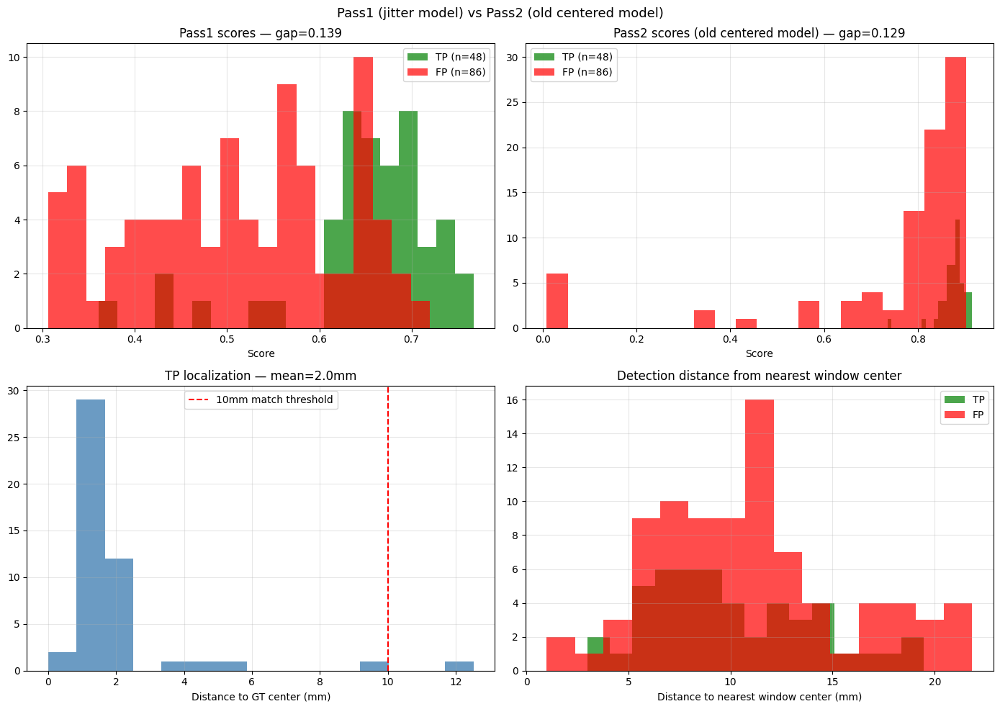


Analysis saved: C:\Users\Administrator\desktop\unet\logs\detection_analysis_v2.json
Plot saved    : C:\Users\Administrator\desktop\unet\logs\detection_analysis_v2.png


In [5]:
# CELL 6-ANALYSIS — pass1 vs pass2 (old centered model) analysis
# saves to detection_analysis_v2.png and detection_analysis_v2.json
# ============================================================
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import pickle
import json
from pathlib import Path

# ── UNet definition ───────────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool = nn.MaxPool3d(2)
        self.conv = DoubleConv3D(in_ch, out_ch)
    def forward(self, x):
        return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up   = nn.ConvTranspose3d(in_ch, out_ch, 2, stride=2)
        self.conv = DoubleConv3D(in_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)

class UNet3D(nn.Module):
    def __init__(self, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1       = DoubleConv3D(1,   f)
        self.enc2       = Down(f,   f*2)
        self.enc3       = Down(f*2, f*4)
        self.enc4       = Down(f*4, f*8)
        self.bottleneck = Down(f*8, f*16)
        self.dec4       = Up(f*16, f*8)
        self.dec3       = Up(f*8,  f*4)
        self.dec2       = Up(f*4,  f*2)
        self.dec1       = Up(f*2,  f)
        self.head       = nn.Conv3d(f, 1, 1)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        b  = self.bottleneck(e4)
        d4 = self.dec4(b,  e4)
        d3 = self.dec3(d4, e3)
        d2 = self.dec2(d3, e2)
        d1 = self.dec1(d2, e1)
        return torch.sigmoid(self.head(d1))

# ── load old centered model ───────────────────────────────────
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
model_old = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
model_old.load_state_dict(torch.load(
    WEIGHTS_DIR / "client1_best_v1_no_jitter.pt",
    map_location=DEVICE
))
model_old.eval()
print(f"Old centered model loaded")
print(f"Device: {DEVICE}")

# ── load all_results ──────────────────────────────────────────
if 'all_results' not in dir():
    with open(LOG_DIR / "all_results.pkl", "rb") as f:
        all_results = pickle.load(f)
    print(f"Loaded {len(all_results)} patient results from disk")

p  = PATCH_SIZE
ph = p // 2

# ── per-detection analysis ────────────────────────────────────
print(f"\n{'Type':<5} {'PID':<20} {'Det pos':>16} "
      f"{'Pass1':>7} {'Pass2':>7} {'GT dist':>9} "
      f"{'Win dist':>10}")
print("-" * 80)

all_tp_pass1    = []
all_tp_pass2    = []
all_fp_pass1    = []
all_fp_pass2    = []
all_tp_gt_dists = []
all_tp_win_dists = []
all_fp_win_dists = []

for r in all_results:
    pid  = r["pid"]
    vol  = np.load(PREPROC_DIR / f"{pid}.npy")
    mask = np.load(MASK_DIR    / f"{pid}.npy")
    D, H, W = vol.shape

    # rebuild window centers
    coords = np.argwhere(mask > 0)
    z1 = max(0, coords[:,0].min() - p//4)
    y1 = max(0, coords[:,1].min() - p//4)
    x1 = max(0, coords[:,2].min() - p//4)
    z2 = min(D, coords[:,0].max() + p//4)
    y2 = min(H, coords[:,1].max() + p//4)
    x2 = min(W, coords[:,2].max() + p//4)

    z_centers = [zw+ph for zw in range(z1, z2-p+1, STRIDE)]
    y_centers = [yw+ph for yw in range(y1, y2-p+1, STRIDE)]
    x_centers = [xw+ph for xw in range(x1, x2-p+1, STRIDE)]

    def nearest_win_dist(dz, dy, dx):
        nz = min(z_centers, key=lambda c: abs(c-dz))
        ny = min(y_centers, key=lambda c: abs(c-dy))
        nx = min(x_centers, key=lambda c: abs(c-dx))
        return float(np.sqrt((dz-nz)**2+(dy-ny)**2+(dx-nx)**2))

    def pass2_old(dz, dy, dx):
        """Center patch on detection, run OLD centered model."""
        zw = max(0, min(D-p, dz-ph))
        yw = max(0, min(H-p, dy-ph))
        xw = max(0, min(W-p, dx-ph))
        patch = vol[zw:zw+p, yw:yw+p, xw:xw+p]
        if patch.shape != (p,p,p):
            return 0.0
        with torch.no_grad():
            t    = torch.from_numpy(patch).unsqueeze(0).unsqueeze(0).float().to(DEVICE)
            pred = model_old(t).squeeze().cpu().numpy()
        return float(pred[ph,ph,ph])

    # TPs
    for item in r["tp_list"]:
        dz, dy, dx, s1 = item["det"]
        s2    = pass2_old(dz, dy, dx)
        wdist = nearest_win_dist(dz, dy, dx)
        gdist = item["dist_mm"]
        all_tp_pass1.append(s1)
        all_tp_pass2.append(s2)
        all_tp_gt_dists.append(gdist)
        all_tp_win_dists.append(wdist)
        print(f"{'TP':<5} {pid:<20} ({dz:3d},{dy:3d},{dx:3d}) "
              f"{s1:>7.3f} {s2:>7.3f} {gdist:>7.1f}mm "
              f"{wdist:>8.1f}mm")

    # FPs
    for item in r["fp_list"]:
        dz, dy, dx, s1 = item["det"]
        s2    = pass2_old(dz, dy, dx)
        wdist = nearest_win_dist(dz, dy, dx)
        all_fp_pass1.append(s1)
        all_fp_pass2.append(s2)
        all_fp_win_dists.append(wdist)
        print(f"{'FP':<5} {pid:<20} ({dz:3d},{dy:3d},{dx:3d}) "
              f"{s1:>7.3f} {s2:>7.3f} {'N/A':>7} "
              f"{wdist:>8.1f}mm")

# ── summary ───────────────────────────────────────────────────
print(f"\n{'='*60}")
print(f"SUMMARY")
print(f"{'='*60}")
print(f"\nTP ({len(all_tp_pass1)} detections):")
print(f"  Pass1: mean={np.mean(all_tp_pass1):.3f}  "
      f"min={min(all_tp_pass1):.3f}  max={max(all_tp_pass1):.3f}")
print(f"  Pass2: mean={np.mean(all_tp_pass2):.3f}  "
      f"min={min(all_tp_pass2):.3f}  max={max(all_tp_pass2):.3f}")
print(f"  GT dist  : mean={np.mean(all_tp_gt_dists):.1f}mm  "
      f"max={max(all_tp_gt_dists):.1f}mm")
print(f"  Win dist : mean={np.mean(all_tp_win_dists):.1f}mm  "
      f"max={max(all_tp_win_dists):.1f}mm")

print(f"\nFP ({len(all_fp_pass1)} detections):")
print(f"  Pass1: mean={np.mean(all_fp_pass1):.3f}  "
      f"min={min(all_fp_pass1):.3f}  max={max(all_fp_pass1):.3f}")
print(f"  Pass2: mean={np.mean(all_fp_pass2):.3f}  "
      f"min={min(all_fp_pass2):.3f}  max={max(all_fp_pass2):.3f}")
print(f"  Win dist : mean={np.mean(all_fp_win_dists):.1f}mm  "
      f"max={max(all_fp_win_dists):.1f}mm")

p1_gap = np.mean(all_tp_pass1) - np.mean(all_fp_pass1)
p2_gap = np.mean(all_tp_pass2) - np.mean(all_fp_pass2)
print(f"\nPass1 gap : {p1_gap:.3f}")
print(f"Pass2 gap : {p2_gap:.3f}")
if p2_gap > p1_gap:
    print(f"✓ Pass2 (old model) improves separation by "
          f"{p2_gap-p1_gap:.3f}")
else:
    print(f"✗ Pass2 (old model) does NOT improve separation")

# ── pass2 threshold sweep ─────────────────────────────────────
print(f"\nPass2 threshold sweep (old centered model):")
print(f"{'Thresh':>8} {'TP kept':>8} {'FP kept':>8} "
      f"{'Sens':>7} {'Prec':>7} {'FP/scan':>8} {'F1':>7}")
print("-" * 58)

total_gt = sum(r["gt_nodules"] for r in all_results)
n_scans  = len(all_results)
best_f1  = 0
best_row = None

for thresh in np.arange(0.10, 0.95, 0.05):
    tp_k = sum(1 for s in all_tp_pass2 if s >= thresh)
    fp_k = sum(1 for s in all_fp_pass2 if s >= thresh)
    sens = tp_k / max(total_gt, 1)
    prec = tp_k / max(tp_k+fp_k, 1)
    fps  = fp_k / n_scans
    f1_t = 2*prec*sens / max(prec+sens, 1e-6)
    star = " ★" if f1_t > best_f1 else ""
    if f1_t > best_f1:
        best_f1  = f1_t
        best_row = (thresh, tp_k, fp_k, sens, prec, fps, f1_t)
    print(f"{thresh:>8.2f} {tp_k:>8} {fp_k:>8} "
          f"{sens:>7.3f} {prec:>7.3f} {fps:>8.2f} "
          f"{f1_t:>7.3f}{star}")

print(f"\nBest F1={best_f1:.3f} at threshold={best_row[0]:.2f}")
print(f"  → TP={best_row[1]}  FP={best_row[2]}  "
      f"Sens={best_row[3]:.3f}  Prec={best_row[4]:.3f}  "
      f"FP/scan={best_row[5]:.2f}")

# ── plots ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Pass1 (jitter model) vs Pass2 (old centered model)",
             fontsize=13)

axes[0,0].hist(all_tp_pass1, bins=20, color='green',
               alpha=0.7, label=f'TP (n={len(all_tp_pass1)})')
axes[0,0].hist(all_fp_pass1, bins=20, color='red',
               alpha=0.7, label=f'FP (n={len(all_fp_pass1)})')
axes[0,0].set_xlabel('Score')
axes[0,0].set_title(f'Pass1 scores — gap={p1_gap:.3f}')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

axes[0,1].hist(all_tp_pass2, bins=20, color='green',
               alpha=0.7, label=f'TP (n={len(all_tp_pass2)})')
axes[0,1].hist(all_fp_pass2, bins=20, color='red',
               alpha=0.7, label=f'FP (n={len(all_fp_pass2)})')
axes[0,1].set_xlabel('Score')
axes[0,1].set_title(f'Pass2 scores (old centered model) — gap={p2_gap:.3f}')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

axes[1,0].hist(all_tp_gt_dists, bins=15, color='steelblue',
               alpha=0.8)
axes[1,0].axvline(10, color='red', linestyle='--',
                   label='10mm match threshold')
axes[1,0].set_xlabel('Distance to GT center (mm)')
axes[1,0].set_title(f'TP localization — mean={np.mean(all_tp_gt_dists):.1f}mm')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

axes[1,1].hist(all_tp_win_dists, bins=15, color='green',
               alpha=0.7, label='TP')
axes[1,1].hist(all_fp_win_dists, bins=15, color='red',
               alpha=0.7, label='FP')
axes[1,1].set_xlabel('Distance to nearest window center (mm)')
axes[1,1].set_title('Detection distance from nearest window center')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(LOG_DIR / "detection_analysis_v2.png",
            dpi=90, bbox_inches='tight')
plt.show()

# ── save analysis results ─────────────────────────────────────
analysis = {
    "tp_count"       : len(all_tp_pass1),
    "fp_count"       : len(all_fp_pass1),
    "pass1_tp_mean"  : round(float(np.mean(all_tp_pass1)), 4),
    "pass1_fp_mean"  : round(float(np.mean(all_fp_pass1)), 4),
    "pass1_gap"      : round(float(p1_gap), 4),
    "pass2_tp_mean"  : round(float(np.mean(all_tp_pass2)), 4),
    "pass2_fp_mean"  : round(float(np.mean(all_fp_pass2)), 4),
    "pass2_gap"      : round(float(p2_gap), 4),
    "tp_gt_dist_mean": round(float(np.mean(all_tp_gt_dists)), 2),
    "tp_gt_dist_max" : round(float(max(all_tp_gt_dists)), 2),
    "best_pass2_thresh": round(float(best_row[0]), 2),
    "best_pass2_f1"    : round(float(best_f1), 4),
    "best_pass2_sens"  : round(float(best_row[3]), 4),
    "best_pass2_prec"  : round(float(best_row[4]), 4),
    "best_pass2_fp_per_scan": round(float(best_row[5]), 4),
}

with open(LOG_DIR / "detection_analysis_v2.json", "w") as f:
    json.dump(analysis, f, indent=2)

print(f"\nAnalysis saved: {LOG_DIR / 'detection_analysis_v2.json'}")
print(f"Plot saved    : {LOG_DIR / 'detection_analysis_v2.png'}")

In [6]:
# check if FPs overlap with ambiguous nodules (1-2 radiologist annotations)
import pickle
import json
import numpy as np

with open(LOG_DIR / "all_results.pkl", "rb") as f:
    all_results = pickle.load(f)

print(f"Checking FPs against ambiguous annotations...")
print(f"(annotations with 1-2 radiologists, below our MIN_CONSENSUS=3)\n")

fp_is_ambiguous    = 0
fp_is_clean        = 0
fp_ambiguous_list  = []

for r in all_results:
    pid = r["pid"]

    with open(ANNOT_DIR / f"{pid}.json") as f:
        record = json.load(f)

    consensus  = record["consensus_nodules"]   # ≥3 rads
    exclusions = record["exclusion_zones"]      # ALL annotations

    # ambiguous = in exclusion zones but NOT in consensus
    consensus_centers = [
        tuple(n["center_res"]) for n in consensus
    ]

    ambiguous = [
        e for e in exclusions
        if tuple(e["center_res"]) not in consensus_centers
    ]

    for item in r["fp_list"]:
        dz, dy, dx, score = item["det"]

        matched_ambiguous = False
        for amb in ambiguous:
            gz, gy, gx = amb["center_res"]
            radius_mm  = amb["radius_mm"]
            dist = np.sqrt((dz-gz)**2+(dy-gy)**2+(dx-gx)**2)
            if dist <= max(radius_mm, 10.0):
                matched_ambiguous = True
                fp_ambiguous_list.append({
                    "pid"      : pid,
                    "det"      : (dz,dy,dx,score),
                    "amb_center": (gz,gy,gx),
                    "radius_mm": radius_mm,
                    "dist_mm"  : dist,
                })
                break

        if matched_ambiguous:
            fp_is_ambiguous += 1
        else:
            fp_is_clean += 1

total_fp = fp_is_ambiguous + fp_is_clean
print(f"Total FPs              : {total_fp}")
print(f"FPs matching ambiguous : {fp_is_ambiguous} "
      f"({100*fp_is_ambiguous/max(total_fp,1):.1f}%)")
print(f"FPs truly clean        : {fp_is_clean} "
      f"({100*fp_is_clean/max(total_fp,1):.1f}%)")

print(f"\nFPs that match ambiguous annotations:")
print(f"{'PID':<20} {'Det pos':>16} {'Amb center':>14} "
      f"{'Dist':>7} {'Radius':>8} {'Score':>7}")
print("-" * 75)
for item in fp_ambiguous_list:
    dz,dy,dx,sc = item["det"]
    gz,gy,gx    = item["amb_center"]
    print(f"{item['pid']:<20} ({dz:3d},{dy:3d},{dx:3d}) "
          f"({gz:3d},{gy:3d},{gx:3d}) "
          f"{item['dist_mm']:>7.1f}mm "
          f"{item['radius_mm']:>8.1f}mm "
          f"{sc:>7.3f}")

print(f"\nIf we count ambiguous matches as TP:")
adjusted_tp = sum(r["tp"] for r in all_results) + fp_is_ambiguous
adjusted_fp = fp_is_clean
adjusted_fn = sum(r["fn"] for r in all_results)
total_gt_adj = sum(r["gt_nodules"] for r in all_results) + fp_is_ambiguous
sens_adj = adjusted_tp / max(adjusted_tp + adjusted_fn, 1)
prec_adj = adjusted_tp / max(adjusted_tp + adjusted_fp, 1)
print(f"  Adjusted TP : {adjusted_tp}")
print(f"  Adjusted FP : {adjusted_fp}")
print(f"  Adjusted FN : {adjusted_fn}")
print(f"  Sensitivity : {sens_adj:.3f}")
print(f"  Precision   : {prec_adj:.3f}")

Checking FPs against ambiguous annotations...
(annotations with 1-2 radiologists, below our MIN_CONSENSUS=3)

Total FPs              : 86
FPs matching ambiguous : 16 (18.6%)
FPs truly clean        : 70 (81.4%)

FPs that match ambiguous annotations:
PID                           Det pos     Amb center    Dist   Radius   Score
---------------------------------------------------------------------------
LIDC-IDRI-0012       (165,127,117) (165,128,117)     1.0mm      3.0mm   0.697
LIDC-IDRI-0012       (208,278,123) (208,278,120)     3.0mm      2.8mm   0.658
LIDC-IDRI-0012       (194,159,276) (193,159,276)     1.0mm      2.7mm   0.443
LIDC-IDRI-0019       (331,215,143) (331,215,145)     2.0mm     15.9mm   0.464
LIDC-IDRI-0031       (135,337,149) (138,337,149)     3.0mm      3.0mm   0.398
LIDC-IDRI-0067       (217,245,327) (216,245,327)     1.0mm      3.9mm   0.652
LIDC-IDRI-0073       (155,257,228) (155,258,227)     1.4mm      5.1mm   0.650
LIDC-IDRI-0073       (140,234,214) (140,231,214)   

Loaded 24 patient results

Re-evaluating 24 patients with MIN_CONSENSUS=2...
  LIDC-IDRI-0001: GT(≥2)= 1  GT(≥3)= 1  TP= 1  FP=  2  FN= 0
  LIDC-IDRI-0012: GT(≥2)=10  GT(≥3)= 9  TP= 9  FP=  4  FN= 1
  LIDC-IDRI-0018: GT(≥2)= 4  GT(≥3)= 4  TP= 4  FP=  2  FN= 0
  LIDC-IDRI-0019: GT(≥2)= 1  GT(≥3)= 0  TP= 1  FP=  1  FN= 0
  LIDC-IDRI-0031: GT(≥2)= 3  GT(≥3)= 3  TP= 3  FP=  8  FN= 0
  LIDC-IDRI-0039: GT(≥2)= 5  GT(≥3)= 5  TP= 4  FP=  3  FN= 1
  LIDC-IDRI-0043: GT(≥2)= 3  GT(≥3)= 3  TP= 3  FP=  1  FN= 0
  LIDC-IDRI-0053: GT(≥2)= 2  GT(≥3)= 2  TP= 2  FP=  2  FN= 0
  LIDC-IDRI-0062: GT(≥2)= 0  GT(≥3)= 0  TP= 0  FP=  0  FN= 0
  LIDC-IDRI-0067: GT(≥2)= 4  GT(≥3)= 3  TP= 4  FP=  1  FN= 0
  LIDC-IDRI-0073: GT(≥2)= 2  GT(≥3)= 1  TP= 2  FP=  8  FN= 0
  LIDC-IDRI-0086: GT(≥2)= 1  GT(≥3)= 0  TP= 1  FP=  9  FN= 0
  LIDC-IDRI-0090: GT(≥2)= 1  GT(≥3)= 1  TP= 1  FP=  1  FN= 0
  LIDC-IDRI-0095: GT(≥2)= 2  GT(≥3)= 2  TP= 2  FP=  4  FN= 0
  LIDC-IDRI-0097: GT(≥2)= 1  GT(≥3)= 1  TP= 1  FP=  8  FN= 0
  LIDC-I

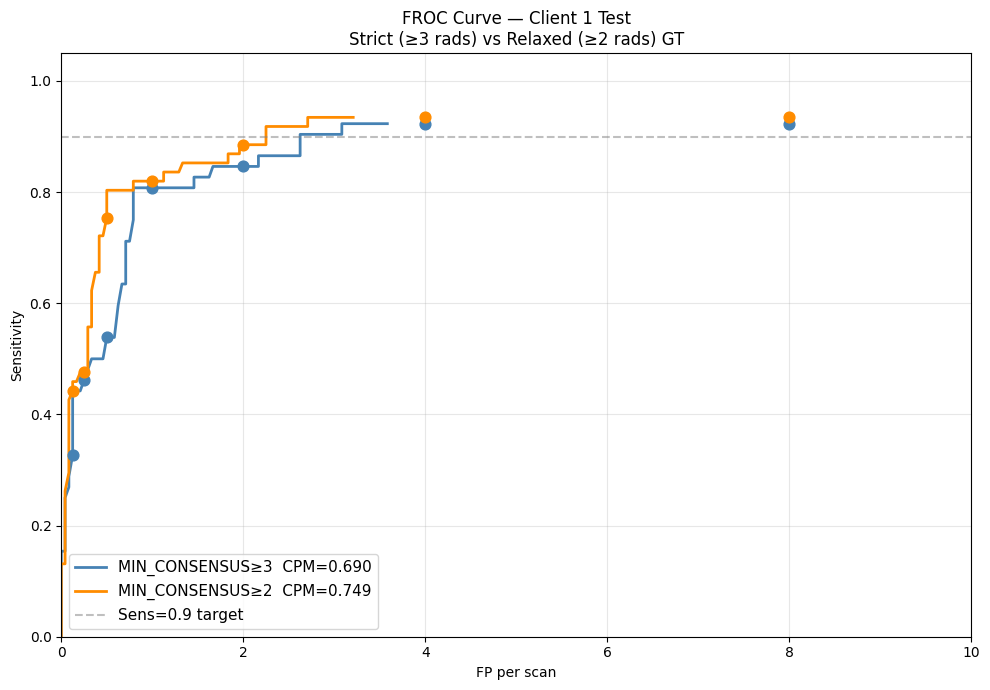


COMPARISON SUMMARY
                    MIN_CONS≥3   MIN_CONS≥2
GT nodules        :         52           61
TP                :         48           57
FP                :         86           77
FN                :          4            4
Sensitivity       :      0.923        0.934
FP/scan           :       3.58         3.21
CPM               :      0.690        0.749

Saved: C:\Users\Administrator\desktop\unet\logs\all_results_min2.pkl
Plot : C:\Users\Administrator\desktop\unet\logs\froc_strict_vs_relaxed.png


In [7]:
# CELL 6-ADJUSTED — rerun inference evaluation with MIN_CONSENSUS=2
# Uses same heatmaps/detections from all_results
# Just changes the matching criterion
# ============================================================
import pickle
import json
import numpy as np
import matplotlib.pyplot as plt

with open(LOG_DIR / "all_results.pkl", "rb") as f:
    all_results = pickle.load(f)
print(f"Loaded {len(all_results)} patient results")

# ── rebuild GT with MIN_CONSENSUS=2 ──────────────────────────
def get_nodules_min2(pid):
    """Load all annotations with ≥2 radiologist agreement."""
    with open(ANNOT_DIR / f"{pid}.json") as f:
        record = json.load(f)
    # exclusion_zones contains ALL annotations regardless of count
    # we need to reload from pylidc to get exact counts
    return record["exclusion_zones"]  # all annotated regions

# actually we need the exact annotation counts
# let's use pylidc directly
import pylidc as pl
import warnings
warnings.filterwarnings("ignore")

if not hasattr(np, 'int'):
    np.int = int

all_scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()
seen = {}
for s in all_scans:
    if s.patient_id not in seen:
        seen[s.patient_id] = s

import SimpleITK as sitk

def load_sitk_original(scan):
    dicom_path = scan.get_path_to_dicom_files()
    ids   = sitk.ImageSeriesReader.GetGDCMSeriesIDs(str(dicom_path))
    files = sitk.ImageSeriesReader.GetGDCMSeriesFileNames(
                str(dicom_path), ids[0])
    reader = sitk.ImageSeriesReader()
    reader.SetFileNames(files)
    return reader.Execute()

def build_resampled_sitk(pid):
    meta = np.load(
        PREPROC_DIR / f"{pid}_meta.npy",
        allow_pickle=True
    ).item()
    sitk_res = sitk.Image(
        [int(x) for x in meta['res_size']],
        sitk.sitkFloat32
    )
    sitk_res.SetSpacing([float(x) for x in meta['res_spacing']])
    sitk_res.SetOrigin([float(x) for x in meta['res_origin']])
    sitk_res.SetDirection([float(x) for x in meta['res_direction']])
    return sitk_res

def get_nodules_with_min_consensus(scan, min_consensus,
                                    sitk_orig, sitk_res):
    """Get all nodule clusters with >= min_consensus annotations."""
    nodules = []
    for ann_group in scan.cluster_annotations():
        if len(ann_group) < min_consensus:
            continue
        ann      = ann_group[0]
        bbox     = ann.bbox()
        orig_col = (bbox[1].start + bbox[1].stop) // 2
        orig_row = (bbox[0].start + bbox[0].stop) // 2
        orig_k   = (bbox[2].start + bbox[2].stop) // 2
        phys     = sitk_orig.TransformIndexToPhysicalPoint(
            (int(orig_col), int(orig_row), int(orig_k))
        )
        res_idx  = sitk_res.TransformPhysicalPointToIndex(phys)
        size     = sitk_res.GetSize()
        res_z    = max(0, min(size[2]-1, res_idx[2]))
        res_y    = max(0, min(size[1]-1, res_idx[1]))
        res_x    = max(0, min(size[0]-1, res_idx[0]))

        diameters = []
        for a in ann_group:
            try:
                diameters.append(a.diameter)
            except:
                pass
        radius_mm = float(np.mean(diameters))/2 if diameters else 5.0

        nodules.append({
            "center_res" : [int(res_z), int(res_y), int(res_x)],
            "radius_mm"  : round(radius_mm, 2),
            "n_annotators": len(ann_group)
        })
    return nodules

def match_detections_to_gt_nodules(detections, gt_nodules):
    matched_gt = set()
    tp_list    = []
    fp_list    = []
    for det in detections:
        dz,dy,dx,score = det
        best_dist   = float('inf')
        best_gt_idx = -1
        for gi, nod in enumerate(gt_nodules):
            if gi in matched_gt:
                continue
            gz,gy,gx  = nod["center_res"]
            radius_mm = nod["radius_mm"]
            dist = np.sqrt((dz-gz)**2+(dy-gy)**2+(dx-gx)**2)
            thresh = max(radius_mm, 10.0)
            if dist < thresh and dist < best_dist:
                best_dist   = dist
                best_gt_idx = gi
        if best_gt_idx >= 0:
            tp_list.append({
                "det"    : det,
                "gt"     : gt_nodules[best_gt_idx],
                "dist_mm": best_dist
            })
            matched_gt.add(best_gt_idx)
        else:
            fp_list.append({"det": det})
    fn_list = [{"gt": nod} for gi,nod in enumerate(gt_nodules)
               if gi not in matched_gt]
    return tp_list, fp_list, fn_list

# ── get test patient IDs ──────────────────────────────────────
CLIENT_PATCH_DIR = PATCH_DIR / "client1"
with open(CLIENT_PATCH_DIR / "split_manifest.json") as f:
    manifest = json.load(f)
tst_pids = manifest["tst_pids"]

# ── re-evaluate with MIN_CONSENSUS=2 ─────────────────────────
print(f"\nRe-evaluating {len(tst_pids)} patients with MIN_CONSENSUS=2...")

all_results_adj = []
all_scores_adj  = []
total_gt_adj    = 0

for r in all_results:
    pid  = r["pid"]
    scan = seen.get(pid)
    if scan is None:
        print(f"  WARNING: {pid} not found in pylidc")
        continue

    try:
        sitk_orig = load_sitk_original(scan)
        sitk_res  = build_resampled_sitk(pid)
        gt_nodules_2 = get_nodules_with_min_consensus(
            scan, 2, sitk_orig, sitk_res
        )
    except Exception as e:
        print(f"  ERROR {pid}: {e}")
        continue

    total_gt_adj += len(gt_nodules_2)

    # get detections from existing results
    detections = [item["det"] for item in r["tp_list"]] + \
                 [item["det"] for item in r["fp_list"]]

    tp_list, fp_list, fn_list = match_detections_to_gt_nodules(
        detections, gt_nodules_2
    )

    all_results_adj.append({
        "pid"       : pid,
        "gt_nodules": len(gt_nodules_2),
        "detections": len(detections),
        "tp"        : len(tp_list),
        "fp"        : len(fp_list),
        "fn"        : len(fn_list),
        "tp_list"   : tp_list,
        "fp_list"   : fp_list,
        "fn_list"   : fn_list,
    })

    for item in tp_list:
        all_scores_adj.append((item["det"][3], 1))
    for item in fp_list:
        all_scores_adj.append((item["det"][3], 0))

    print(f"  {pid}: GT(≥2)={len(gt_nodules_2):2d}  "
          f"GT(≥3)={r['gt_nodules']:2d}  "
          f"TP={len(tp_list):2d}  FP={len(fp_list):3d}  "
          f"FN={len(fn_list):2d}")

# ── aggregate metrics ─────────────────────────────────────────
total_tp = sum(r["tp"] for r in all_results_adj)
total_fp = sum(r["fp"] for r in all_results_adj)
total_fn = sum(r["fn"] for r in all_results_adj)
n_scans  = len(all_results_adj)

sensitivity = total_tp / max(total_tp+total_fn, 1)
precision   = total_tp / max(total_tp+total_fp, 1)
f1          = 2*precision*sensitivity / max(precision+sensitivity, 1e-6)
fp_per_scan = total_fp / n_scans

print(f"\n{'='*55}")
print(f"RESULTS WITH MIN_CONSENSUS=2")
print(f"{'='*55}")
print(f"Total GT nodules (≥2 rads) : {total_gt_adj}")
print(f"TP={total_tp}  FP={total_fp}  FN={total_fn}")
print(f"Sensitivity : {sensitivity:.3f}")
print(f"Precision   : {precision:.3f}")
print(f"F1          : {f1:.3f}")
print(f"FP/scan     : {fp_per_scan:.2f}")

# ── FROC ─────────────────────────────────────────────────────
if len(all_scores_adj) > 0:
    all_scores_adj.sort(key=lambda x: x[0], reverse=True)
    scores_arr = np.array([s[0] for s in all_scores_adj])
    labels_arr = np.array([s[1] for s in all_scores_adj])

    sensitivities = []
    fp_per_scans  = []
    for thresh in np.linspace(0.95, 0.01, 500):
        keep = scores_arr >= thresh
        tp_t = labels_arr[keep].sum()
        fp_t = (1-labels_arr[keep]).sum()
        sensitivities.append(float(tp_t / max(total_gt_adj, 1)))
        fp_per_scans.append(float(fp_t / n_scans))

    cpm_fp_points     = [0.125, 0.25, 0.5, 1, 2, 4, 8]
    cpm_sensitivities = []
    for target_fp in cpm_fp_points:
        diffs = [abs(fp-target_fp) for fp in fp_per_scans]
        cpm_sensitivities.append(sensitivities[np.argmin(diffs)])
    cpm_adj = np.mean(cpm_sensitivities)

    print(f"\nCPM (MIN_CONSENSUS=2) : {cpm_adj:.3f}")
    print(f"Sensitivity at standard FP/scan points:")
    for fp_pt, sens in zip(cpm_fp_points, cpm_sensitivities):
        print(f"  {fp_pt:5.3f} FP/scan → {sens:.3f}")

    # ── comparison plot ───────────────────────────────────────
    # load original strict FROC data
    with open(LOG_DIR / "all_scores.pkl", "rb") as f:
        all_scores_strict = pickle.load(f)

    all_scores_strict.sort(key=lambda x: x[0], reverse=True)
    sc_strict = np.array([s[0] for s in all_scores_strict])
    lb_strict = np.array([s[1] for s in all_scores_strict])
    total_gt_strict = sum(r["gt_nodules"] for r in all_results)

    sens_strict = []
    fps_strict  = []
    for thresh in np.linspace(0.95, 0.01, 500):
        keep = sc_strict >= thresh
        tp_t = lb_strict[keep].sum()
        fp_t = (1-lb_strict[keep]).sum()
        sens_strict.append(float(tp_t / max(total_gt_strict, 1)))
        fps_strict.append(float(fp_t / n_scans))

    cpm_strict_sens = []
    for target_fp in cpm_fp_points:
        diffs = [abs(fp-target_fp) for fp in fps_strict]
        cpm_strict_sens.append(sens_strict[np.argmin(diffs)])
    cpm_strict = np.mean(cpm_strict_sens)

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.plot(fps_strict, sens_strict,
            color='steelblue', linewidth=2,
            label=f'MIN_CONSENSUS≥3  CPM={cpm_strict:.3f}')
    ax.plot(fp_per_scans, sensitivities,
            color='darkorange', linewidth=2,
            label=f'MIN_CONSENSUS≥2  CPM={cpm_adj:.3f}')
    ax.scatter(cpm_fp_points, cpm_strict_sens,
               color='steelblue', zorder=5, s=60)
    ax.scatter(cpm_fp_points, cpm_sensitivities,
               color='darkorange', zorder=5, s=60)
    ax.axhline(0.9, color='gray', linestyle='--',
               alpha=0.5, label='Sens=0.9 target')
    ax.set_xlabel('FP per scan')
    ax.set_ylabel('Sensitivity')
    ax.set_title('FROC Curve — Client 1 Test\n'
                 'Strict (≥3 rads) vs Relaxed (≥2 rads) GT',
                 fontsize=12)
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(LOG_DIR / "froc_strict_vs_relaxed.png",
                dpi=100, bbox_inches='tight')
    plt.show()

    print(f"\n{'='*55}")
    print(f"COMPARISON SUMMARY")
    print(f"{'='*55}")
    print(f"                    MIN_CONS≥3   MIN_CONS≥2")
    print(f"GT nodules        : {total_gt_strict:>10}   {total_gt_adj:>10}")
    print(f"TP                : {sum(r['tp'] for r in all_results):>10}   {total_tp:>10}")
    print(f"FP                : {sum(r['fp'] for r in all_results):>10}   {total_fp:>10}")
    print(f"FN                : {sum(r['fn'] for r in all_results):>10}   {total_fn:>10}")
    print(f"Sensitivity       : {sum(r['tp'] for r in all_results)/max(total_gt_strict,1):>10.3f}   {sensitivity:>10.3f}")
    print(f"FP/scan           : {sum(r['fp'] for r in all_results)/n_scans:>10.2f}   {fp_per_scan:>10.2f}")
    print(f"CPM               : {cpm_strict:>10.3f}   {cpm_adj:>10.3f}")

# ── save ──────────────────────────────────────────────────────
with open(LOG_DIR / "all_results_min2.pkl", "wb") as f:
    pickle.dump(all_results_adj, f)

print(f"\nSaved: {LOG_DIR / 'all_results_min2.pkl'}")
print(f"Plot : {LOG_DIR / 'froc_strict_vs_relaxed.png'}")

In [17]:
import shutil
shutil.copy(
    WEIGHTS_DIR / "client1_best.pt",
    WEIGHTS_DIR / "client1_best_v1_no_jitter.pt"
)
print("Baseline saved.")

Baseline saved.


In [9]:
import pylidc as pl
import warnings
warnings.filterwarnings("ignore")

all_scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()
seen = {}
for s in all_scans:
    if s.patient_id not in seen:
        seen[s.patient_id] = s

all_unique = list(seen.values())

# client 1 patient IDs — already used
client1_pids = set(s.patient_id for s in all_unique[:160])

# usable patients NOT in client 1
usable_remaining = [
    s for s in all_unique
    if s.slice_thickness <= 2.5
    and s.patient_id not in client1_pids
]

print(f"Total unique patients     : {len(all_unique)}")
print(f"Client 1 patients         : {len(client1_pids)}")
print(f"Usable remaining (≤2.5mm) : {len(usable_remaining)}")

# split remaining into clients 2-5
c2 = usable_remaining[0:180]
c3 = usable_remaining[180:380]
c4 = usable_remaining[380:550]
c5 = usable_remaining[550:736]

print(f"\nClient 2: {len(c2)} patients  "
      f"({c2[0].patient_id} → {c2[-1].patient_id})")
print(f"Client 3: {len(c3)} patients  "
      f"({c3[0].patient_id} → {c3[-1].patient_id})")
print(f"Client 4: {len(c4)} patients  "
      f"({c4[0].patient_id} → {c4[-1].patient_id})")
print(f"Client 5: {len(c5)} patients  "
      f"({c5[0].patient_id} → {c5[-1].patient_id})")

total_used = 160 + len(c2) + len(c3) + len(c4) + len(c5)
remaining  = len(usable_remaining) - (len(c2)+len(c3)+len(c4)+len(c5))
print(f"\nTotal patients used       : {total_used}")
print(f"Usable patients leftover  : {remaining} → global test pool contribution")

# save this split definition
import json
split_def = {
    "client1_pids": sorted(client1_pids),
    "client2_pids": [s.patient_id for s in c2],
    "client3_pids": [s.patient_id for s in c3],
    "client4_pids": [s.patient_id for s in c4],
    "client5_pids": [s.patient_id for s in c5],
}
with open(OUT_ROOT / "federation_splits.json", "w") as f:
    json.dump(split_def, f, indent=2)

print(f"\nSplit definition saved to: {OUT_ROOT / 'federation_splits.json'}")

Total unique patients     : 1010
Client 1 patients         : 160
Usable remaining (≤2.5mm) : 754

Client 2: 180 patients  (LIDC-IDRI-0161 → LIDC-IDRI-0350)
Client 3: 200 patients  (LIDC-IDRI-0352 → LIDC-IDRI-0589)
Client 4: 170 patients  (LIDC-IDRI-0590 → LIDC-IDRI-0779)
Client 5: 186 patients  (LIDC-IDRI-0780 → LIDC-IDRI-0990)

Total patients used       : 896
Usable patients leftover  : 18 → global test pool contribution

Split definition saved to: C:\Users\Administrator\desktop\unet\federation_splits.json


In [13]:
# TEST OLD MODEL ON CENTERED PATCHES
# ============================================================
import torch
import torch.nn as nn
import numpy as np
import json
import random
from pathlib import Path

# ── UNet definition (copy from Cell 5) ───────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool = nn.MaxPool3d(2)
        self.conv = DoubleConv3D(in_ch, out_ch)
    def forward(self, x):
        return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up   = nn.ConvTranspose3d(in_ch, out_ch, 2, stride=2)
        self.conv = DoubleConv3D(in_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)

class UNet3D(nn.Module):
    def __init__(self, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1       = DoubleConv3D(1,   f)
        self.enc2       = Down(f,   f*2)
        self.enc3       = Down(f*2, f*4)
        self.enc4       = Down(f*4, f*8)
        self.bottleneck = Down(f*8, f*16)
        self.dec4       = Up(f*16, f*8)
        self.dec3       = Up(f*8,  f*4)
        self.dec2       = Up(f*4,  f*2)
        self.dec1       = Up(f*2,  f)
        self.head       = nn.Conv3d(f, 1, 1)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        b  = self.bottleneck(e4)
        d4 = self.dec4(b,  e4)
        d3 = self.dec3(d4, e3)
        d2 = self.dec2(d3, e2)
        d1 = self.dec1(d2, e1)
        return torch.sigmoid(self.head(d1))

# ── load OLD model ────────────────────────────────────────────
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
model_old = UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
model_old.load_state_dict(torch.load(
    WEIGHTS_DIR / "client1_best_v1_no_jitter.pt",
    map_location=DEVICE
))
model_old.eval()
print("Old model loaded (no jitter training)")

# ── load manifest ─────────────────────────────────────────────
CLIENT_PATCH_DIR = PATCH_DIR / "client1"
with open(CLIENT_PATCH_DIR / "split_manifest.json") as f:
    manifest = json.load(f)

tst_pids = set(manifest["tst_pids"])

# get centered patches (j00) from test patients
all_pos = list((CLIENT_PATCH_DIR / "positives").glob("*_j00*.npz"))
test_pos_centered = [
    f for f in all_pos
    if f.stem.split('_n')[0] in tst_pids
]
# get negatives from test patients directly from disk
all_neg = list((CLIENT_PATCH_DIR / "negatives").glob("*.npz"))
test_neg = [
    f for f in all_neg
    if f.stem.split('_neg')[0] in tst_pids
]
print(f"Test negatives from disk: {len(test_neg)}")

print(f"Test centered positives : {len(test_pos_centered)}")
print(f"Test negatives          : {len(test_neg)}")

# ── evaluate positives ────────────────────────────────────────
print(f"\n--- CENTERED POSITIVE PATCHES ---")
pos_peaks      = []
pos_center_vals = []
ph = PATCH_SIZE // 2

sample_pos = random.sample(test_pos_centered,
                            min(20, len(test_pos_centered)))

for f in sample_pos:
    data = np.load(f)
    vol  = data['vol']

    with torch.no_grad():
        t    = torch.from_numpy(vol).unsqueeze(0).unsqueeze(0).float().to(DEVICE)
        pred = model_old(t).squeeze().cpu().numpy()

    peak       = pred.max()
    center_val = pred[ph, ph, ph]
    pos_peaks.append(peak)
    pos_center_vals.append(center_val)
    print(f"  {f.stem[:35]}: peak={peak:.3f}  at_center={center_val:.3f}")

print(f"\nSummary positives:")
print(f"  Mean peak      : {np.mean(pos_peaks):.3f}")
print(f"  Mean at center : {np.mean(pos_center_vals):.3f}")
print(f"  Peak > 0.5     : {sum(p>0.5 for p in pos_peaks)}/{len(pos_peaks)}")
print(f"  Peak > 0.3     : {sum(p>0.3 for p in pos_peaks)}/{len(pos_peaks)}")

# ── evaluate negatives ────────────────────────────────────────
print(f"\n--- NEGATIVE PATCHES ---")
neg_peaks = []

sample_neg = random.sample(test_neg, min(20, len(test_neg)))

for f in sample_neg:
    data = np.load(f)
    vol  = data['vol']

    with torch.no_grad():
        t    = torch.from_numpy(vol).unsqueeze(0).unsqueeze(0).float().to(DEVICE)
        pred = model_old(t).squeeze().cpu().numpy()

    peak = pred.max()
    neg_peaks.append(peak)

print(f"  Mean peak  : {np.mean(neg_peaks):.3f}")
print(f"  Peak > 0.5 : {sum(p>0.5 for p in neg_peaks)}/{len(neg_peaks)}")
print(f"  Peak > 0.3 : {sum(p>0.3 for p in neg_peaks)}/{len(neg_peaks)}")
print(f"  Peak > 0.1 : {sum(p>0.1 for p in neg_peaks)}/{len(neg_peaks)}")

# ── conclusion ────────────────────────────────────────────────
print(f"\n{'='*50}")
print(f"CONCLUSION:")
print(f"  Pos mean peak : {np.mean(pos_peaks):.3f}")
print(f"  Neg mean peak : {np.mean(neg_peaks):.3f}")
gap = np.mean(pos_peaks) - np.mean(neg_peaks)
print(f"  Gap           : {gap:.3f}")
if gap > 0.4:
    print(f"  ✓ Model learned real nodule features")
    print(f"  → Jitter fix should resolve inference problem")
elif gap > 0.2:
    print(f"  ⚠ Moderate separation")
else:
    print(f"  ✗ Poor separation — consider RPN")

Old model loaded (no jitter training)
Test negatives from disk: 445
Test centered positives : 52
Test negatives          : 445

--- CENTERED POSITIVE PATCHES ---
  LIDC-IDRI-0012_n06_j00: peak=0.889  at_center=0.883
  LIDC-IDRI-0043_n01_j00: peak=0.911  at_center=0.896
  LIDC-IDRI-0039_n02_j00: peak=0.879  at_center=0.869
  LIDC-IDRI-0031_n01_j00: peak=0.902  at_center=0.885
  LIDC-IDRI-0012_n02_j00: peak=0.857  at_center=0.847
  LIDC-IDRI-0144_n01_j00: peak=0.848  at_center=0.835
  LIDC-IDRI-0121_n01_j00: peak=0.911  at_center=0.903
  LIDC-IDRI-0012_n04_j00: peak=0.891  at_center=0.887
  LIDC-IDRI-0141_n01_j00: peak=0.882  at_center=0.859
  LIDC-IDRI-0090_n00_j00: peak=0.896  at_center=0.878
  LIDC-IDRI-0012_n03_j00: peak=0.898  at_center=0.886
  LIDC-IDRI-0097_n00_j00: peak=0.875  at_center=0.860
  LIDC-IDRI-0012_n07_j00: peak=0.905  at_center=0.893
  LIDC-IDRI-0134_n00_j00: peak=0.857  at_center=0.836
  LIDC-IDRI-0073_n00_j00: peak=0.880  at_center=0.870
  LIDC-IDRI-0121_n00_j00: pe

In [1]:
import json
from pathlib import Path

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")

# load client 1 manifest
with open(OUT_ROOT / "patches" / "client1" / "split_manifest.json") as f:
    c1_manifest = json.load(f)
c1_test_pids = c1_manifest["tst_pids"]

# create global test manifest with client 1
global_test = {
    "test_pids": sorted(c1_test_pids),
    "by_client": {
        "client1": sorted(c1_test_pids)
    }
}

with open(OUT_ROOT / "global_test_pids.json", "w") as f:
    json.dump(global_test, f, indent=2)

print(f"global_test_pids.json created")
print(f"Client 1 test pids: {len(c1_test_pids)}")
print(f"Total so far: {len(global_test['test_pids'])}")

global_test_pids.json created
Client 1 test pids: 24
Total so far: 24
